# 🧠 **Proyecto Júpiter: FakeNews - Notebook 4: Modelado de Machine Learning y Deep Learning para la Detección de Fake News**

> **Continuidad del pipeline analítico.** Este cuaderno toma como punto de partida el archivo plano integrado `df_unificado.csv` (6.335 registros × 15 columnas) consolidado y auditado al cierre del **Notebook 3 (EDA)**. En esta fase se formaliza el ciclo completo de **modelado supervisado**, recorriendo de forma exhaustiva, equitativa y científica el catálogo integral de algoritmos de clasificación analizados a lo largo del programa.

---

### 📋 **Ficha Técnica del Framework**

| Campo | Detalle Técnico |
|---|---|
| **Autores** | AB, JE, IF & JR — Proyecto Júpiter: Fake News (PontIA) |
| **Naturaleza del problema** | Clasificación binaria supervisada categórica (`fake` ∈ {REAL=0, FAKE=1}) |
| **Universo de datos** | `df_unificado`: 6.335 instancias, target perfectamente balanceado (50,06% / 49,94%) |
| **Métrica de gobierno** | **ROC-AUC** (capacidad discriminatoria global independiente del umbral de decisión) |
| **Métricas de control** | F1-Score (balance precisión/recall), Accuracy (lectura directa) y Gap Train-Test (sobreajuste) |
| **Frameworks de soporte** | `scikit-learn` para analítica clásica/ensembles y `TensorFlow/Keras` para arquitecturas profundas |

---

### 🛣️ **Estrategia Multicanal: Las 3 Representaciones del Dato**

Para extraer el máximo potencial predictivo de la infraestructura mixta (campos de métricas numéricas, variables categóricas de trazabilidad y corpus de texto libre), los modelos se dividen estratégicamente en tres vías de entrada aisladas:

1. **Representación Tabular Pura (Métricas + Categorías):** Consumida por árboles, vecinos y algoritmos boosting. Se compone de las variables cuantitativas sanadas (`visitas`, `favorito`, `compartir`, `duracion`), la variable sintética de negocio `latencia_temporal` y la codificación de dimensiones categóricas (`autor`, `fuente`, `tipo`, `pais`).
2. **Representación Textual Vectorizada (TF-IDF):** Consumida por modelos lineales, probabilísticos y kernel. Convierte los campos de texto libre (`titulo` y `texto`) purgados por el pipeline NLP en una matriz dispersa de frecuencias matemáticas mediante un extractor TF-IDF acotado en n-gramas.
3. **Representación Secuencial Entera (Tokenización + Padding):** Consumida por la familia de Deep Learning Recurrente y Convolucional. Convierte el corpus lingüístico en vectores densos ordenados de números enteros alineados mediante una longitud máxima (*padding*) para retener la semántica secuencial y el orden temporal de las palabras.

---

### 🔬 **Catálogo de Experimentación (17 Modelos Evaluados)**

El cuaderno ejecuta de forma automatizada un benchmark competitivo sobre **17 arquitecturas y configuraciones de aprendizaje** distribuidas en 4 grandes subfamilias analíticas:

* **Modelos Clásicos Supervisados (Scikit-Learn):**
  1. *Regresión Logística* (Frontera lineal optimizada sobre el log-odds de la matriz TF-IDF)
  2. *Naive Bayes Multinomial* (Clasificador probabilístico óptimo para conteos de texto TF-IDF)
  3. *Máquinas de Vectores de Soporte (SVM)* (Hiperplano de máximo margen con kernel lineal sobre el corpus)
  4. *K-Vecinos más cercanos (K-NN)* (Suavidad local y distancias euclídeas sobre la matriz tabular)
  5. *Naive Bayes Gaussiano* (Aproximación probabilística continua sobre variables tabulares escaladas)
  6. *Árbol de Decisión (CART)* (Particiones rectangulares ortogonales maximizando la ganancia de impureza Gini)
* **Algoritmos Avanzados: Métodos Ensemble:**

  7. *Random Forest* (Bagging mediante voto mayoritario de árboles de decisión decorrelados)
  8. *Extremely Randomized Trees (Extra Trees)* (Extrema diversidad mediante umbrales de corte 100% aleatorios)
  9. *AdaBoost* (Boosting secuencial enfocado en el re-pesado adaptativo de instancias mal clasificadas)
  10. *Gradient Boosting* (Optimización por descenso de gradiente sobre la función de pérdida logarítmica)
  11. Histogram-Gradient Boosting (implementación de sklearn: boosting acelerado con histogramas de bins)
  12. *Stacking Classifier* (Meta-aprendizaje que combina las predicciones base de RF, GB y KNN usando un meta-juez lineal)
* **Modelos de Aprendizaje Profundo (Deep Learning con Keras):**

  13. *Perceptrón Multicapa (MLP)* (Red neuronal densa Feed-Forward para patrones no lineales tabulares)
  14. *Red Convolucional 1-D (CNN)* (Extracción de patrones locales y combinaciones de n-gramas sobre texto)
  15. *Red Recurrente LSTM* (Células de memoria con compuertas para capturar dependencias secuenciales largas)
  16. *Red Recurrente GRU* (Variante optimizada de LSTM con menor coste computacional y compuerta de actualización)
  17. *LSTM Bidireccional (BiLSTM)* (Procesamiento lingüístico simultáneo de izquierda a derecha y viceversa)

---

### 🛡️ **Garantías metodológicas frente al Data-Leakage**

Para que la comparativa sea rigurosa y reproducible, el experimento sigue un protocolo estricto:

* **Estratificación y barajado.** El split (`SEED=42`) es estratificado y baraja los datos, lo que neutraliza el sesgo de ordenación detectado en el EDA y garantiza que train y test mantengan la misma proporción de la clase `fake`.
* **Aislamiento frente al leakage.** La imputación por mediana (`SimpleImputer`), el escalado (`StandardScaler`), la codificación (`OneHotEncoder`) y la vectorización de texto (`TfidfVectorizer`) se ajustan solo con los datos de entrenamiento, encapsulados en `Pipeline` y `ColumnTransformer`, de modo que ningún estadístico del test contamina el entrenamiento.
* **Exportación de resultados.** El notebook genera y exporta a la carpeta `descargas/` la tabla comparativa (`15.1. Comparativa_modelos.csv`) con el rendimiento y los tiempos de cómputo de todos los modelos, junto con las visualizaciones del análisis: la comparativa global, las curvas ROC de los mejores modelos, el gráfico de sobreajuste (gap train-test) y la matriz de confusión del modelo ganador.

---

# 8. Pipeline de continuidad: recuperación del dataset post-EDA

Antes de modelar, se recupera el `df_unificado` generado por el Notebook 3, leyéndolo desde `datos_procesados/df_unificado.csv`. Así el Notebook 4 se ejecuta de forma independiente, sin depender de que haya objetos en memoria de una ejecución previa.

## 8.1. Importación de librerías y configuración del entorno

Las dependencias se agrupan por responsabilidad: manipulación de datos, visualización, preprocesado e ingeniería de variables, modelos clásicos de `scikit-learn`, ensembles y *deep learning* con `TensorFlow/Keras`.

In [1]:
# --- Núcleo de datos ---
import os, random                                                                         # os: PYTHONHASHSEED; random: semilla de Python
import numpy as np                                                                        # Álgebra vectorial y soporte numérico
import pandas as pd                                                                       # Manipulación tabular (DataFrames)
import re                                                                                 # Detección de emojis por regex (feature tiene_emoji, 3.5)
import warnings; warnings.filterwarnings("ignore")                                        # Silencia warnings no críticos de sklearn/TF
import time                                                                               # Cronometraje de entrenamientos (t_fit)

# --- Visualización ---
import matplotlib.pyplot as plt                                                           # Gráficos: comparativa, ROC, gap, matriz de confusión
plt.style.use("seaborn-v0_8-whitegrid")                                                   # Estilo de rejilla limpia
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.titleweight"] = "bold"

# --- Preprocesado e ingeniería de variables ---
from sklearn.model_selection import train_test_split                                      # Split train/test estratificado
from sklearn.preprocessing  import StandardScaler, OneHotEncoder                          # Escalado de numéricas y codificación 0/1 de categóricas
from sklearn.compose        import ColumnTransformer                                      # Aplica distinto preprocesado a numéricas vs categóricas
from sklearn.pipeline       import Pipeline                                               # Encadena preprocesado + modelo (evita fugas de información)
from sklearn.impute         import SimpleImputer                                          # Rellena ausentes (mediana en numéricas, constante en categóricas)
from sklearn.feature_extraction.text import TfidfVectorizer                               # Texto -> matriz de pesos TF-IDF

# --- Modelos clásicos supervisados ---
from sklearn.linear_model import LogisticRegression                                       # Clasificador lineal (frontera sobre log-odds)
from sklearn.neighbors    import KNeighborsClassifier                                     # K-NN: clasifica por vecinos más cercanos
from sklearn.naive_bayes  import GaussianNB, MultinomialNB                                # Naive Bayes: gaussiano (numéricas) y multinomial (texto TF-IDF)
from sklearn.tree         import DecisionTreeClassifier                                   # Árbol de decisión (CART, índice de Gini)
from sklearn.svm          import SVC                                                      # SVM: hiperplano de máximo margen

# --- Algoritmos avanzados / ensembles ---
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,               # Bagging de árboles: Random Forest y Extra Trees
                              AdaBoostClassifier, GradientBoostingClassifier,             # Boosting: AdaBoost y Gradient Boosting
                              HistGradientBoostingClassifier, StackingClassifier)         # Boosting por histogramas y meta-modelo (stacking)

# --- Métricas ---
from sklearn.metrics import (accuracy_score, precision_score, recall_score,               # Acierto global, precisión y exhaustividad
                             f1_score, roc_auc_score, roc_curve,                          # F1, área bajo ROC y puntos de la curva ROC
                             confusion_matrix, classification_report)                     # Matriz de confusión e informe por clase

# --- Deep Learning (TensorFlow / Keras) ---
import tensorflow as tf                                                                   # Framework de deep learning
from tensorflow.keras.models   import Sequential                                          # Modelo por capas apiladas (secuencial)
from tensorflow.keras.layers   import (Dense, Dropout, Embedding, LSTM, GRU,              # Capas: densa, dropout, embedding, recurrentes (LSTM/GRU)
                                       Bidirectional, Conv1D, GlobalMaxPooling1D,         # BiLSTM, convolución 1D y pooling (CNN de texto)
                                       Input)                                             # Capa de entrada (define la forma del tensor)
from tensorflow.keras.optimizers import Adam                                              # Optimizador Adam (descenso de gradiente adaptativo)
from tensorflow.keras.callbacks  import EarlyStopping                                     # Parada temprana si val_loss deja de mejorar
from tensorflow.keras.preprocessing.text     import Tokenizer                             # Texto -> secuencias de índices de palabra
from tensorflow.keras.preprocessing.sequence import pad_sequences                         # Homogeneiza la longitud de las secuencias (padding)

# --- Reproducibilidad ---
# Una única semilla gobierna las dos familias de modelos para que el notebook sea reproducible.
SEED = 42                                                                                 # Semilla global compartida

# Modelos clásicos (scikit-learn): basta con NumPy y el random de Python.
# Cada estimador recibe además random_state=SEED en su propia celda.
os.environ["PYTHONHASHSEED"] = str(SEED)                                                  # Fija el orden de algunas estructuras de Python para que sea reproducible
random.seed(SEED)                                                                         # Aleatoriedad de Python
np.random.seed(SEED)                                                                      # Aleatoriedad de NumPy

# Deep Learning (TensorFlow/Keras): pesos iniciales y Dropout son aleatorios.
tf.random.set_seed(SEED)                                                                  # Aleatoriedad de TensorFlow (pesos, Dropout)
tf.config.experimental.enable_op_determinism()                                            # Determinismo en GPU (su paralelismo, si no, varía levemente; inofensivo en CPU)

print("Librerías cargadas correctamente.")
print(f"  · scikit-learn  ·  pandas {pd.__version__}  ·  numpy {np.__version__}")
print(f"  · TensorFlow {tf.__version__}")
print(f"  · Semilla global fijada: SEED = {SEED}")

Librerías cargadas correctamente.
  · scikit-learn  ·  pandas 2.3.3  ·  numpy 1.26.3
  · TensorFlow 2.21.0
  · Semilla global fijada: SEED = 42


## **8.2. Pipeline de ingesta df_unificado**


In [2]:
# CARGA DESDE EL PIPELINE LOCAL (datos_procesados)
from pathlib import Path
import pandas as pd

# 1. Definición de la ruta estricta local
PATH_DATASET = Path('.') / 'datos_procesados' / 'df_unificado.csv'

def cargar_dataset():
    """Recupera df_unificado directamente de la carpeta de datos procesados."""
    try:
        df_ = pd.read_csv(PATH_DATASET)
        print(f"✅ Origen: CSV cargado correctamente -> {PATH_DATASET}")
        return df_
    except FileNotFoundError:
        raise FileNotFoundError(
            f"\n\n❌ ERROR CRÍTICO: No se encuentra el archivo en la ruta esperada:\n"
            f"   -> '{PATH_DATASET.resolve()}'\n\n"
            "⚠️ SOLUCCIÓN RÁPIDA:\n"
            "   1. Ve al 'Notebook_3_EDA.ipynb' y ejecuta la última celda de exportación.\n"
            "   2. Asegúrate de que se haya creado la carpeta 'datos_procesados' en Proyecto_Jupiter_Final."
        )

# Ejecución de la carga en la variable global df
df = cargar_dataset()

# --- Verificación de integridad estructural ---
print("\nForma del dataset:", df.shape)
assert "fake" in df.columns, "❌ Falta la columna objetivo 'fake'."
print("Columnas:", list(df.columns))

print("\nBalance del target (fake):")
print(df["fake"].value_counts(dropna=False))

print("\n% por clase:")
print((df["fake"].value_counts(normalize=True) * 100).round(2))

✅ Origen: CSV cargado correctamente -> datos_procesados\df_unificado.csv

Forma del dataset: (6335, 15)
Columnas: ['t_id', 'autor', 'fuente', 'tipo', 'fake', 'tiempo', 'texto', 'titulo', 'compartir', 'duracion', 'favorito', 'visitas', 'pais', 'idioma', 'compartir_tiempo']

Balance del target (fake):
fake
0    3171
1    3164
Name: count, dtype: int64

% por clase:
fake
0    50.06
1    49.94
Name: proportion, dtype: float64


## 8.3. Síntesis ejecutiva de las decisiones heredadas del EDA

El Notebook 3 produjo una **tabla de conclusiones con 33 hallazgos** desglosados por apartado (reglas de negocio, completitud, duplicidad, formatos, rangos, escalas, relevancia y sesgos). De esos 33, muchos **no conllevan acción de modelado** (reglas ya cumplidas, duplicados exactos = 0, formatos homogéneos) o se **consolidan** en una misma decisión (p. ej. toda la completitud numérica colapsa en "sanear → imputar por mediana"). La tabla siguiente recoge las **15 decisiones con impacto directo en el pipeline de ML**; el código de esta fase las **materializa**, no las vuelve a discutir.

| # | Hallazgo EDA | Severidad | Decisión para el modelado |
|---|---|---|---|
| 1 | **Fuga de etiqueta vía `t_id`** (corr. 0,866 con `fake`; además ID aleatorio) | 🔴 Crítica | **Excluir `t_id`** como predictor |
| 2 | **Sesgo de ordenación** (1.ª mitad REAL, 2.ª mitad FAKE) | 🔴 Crítica | **Split estratificado y barajado** (jamás secuencial) |
| 3 | **`idioma` constante** ("English", varianza cero) | 🔴 Crítica | **Excluir `idioma`** |
| 4 | **"Viajes en el tiempo"** `compartir_tiempo < tiempo` (50,02 %) | 🔴 Crítica | Sustituir el par temporal por **`latencia_temporal`**; imputar negativos por mediana |
| 5 | **Multicolinealidad temporal** (`tiempo` y `compartir_tiempo` son espejo) | 🔴 Crítica | Descartar el par crudo; usar solo **`latencia_temporal`** |
| 6 | **`autor` ausente** (14,5 %: NaN + ' ' + centinela −1; no predictivo de fake) | 🟠 Alta | Unificar las 3 ausencias a `"Sin_autor"`; **conservar volumen** |
| 7 | **`tipo` nulo** (4,83 %) | 🟠 Alta | Imputar a `"Desconocido"` |
| 8 | **Strings sucios** (`"err"`, `"null"`, `"favx"`), decimales y negativos imposibles | 🟠 Alta | Sanear → coaccionar a numérico → **imputar por mediana** |
| 9 | **Outliers legítimos** (clúster de bots, viralidad sin engagement) | 🟡 Media | **No eliminar**; favorecen modelos robustos (RF/GB) |
| 10 | **Flags de error** (`df_errores`, independientes de `fake`, ~50/50) | 🟡 Media | **No** usarlos como predictores (ruido / overfitting) |
| 11 | **Duplicidad de texto/título** (`VAR_dup_*`; señal leve de FAKE en títulos) | 🟡 Media | **No eliminar registros**; flags solo diagnósticos, fuera del modelo |
| 12 | **Texto > 2.500 car.** (63,7 % de los textos) | 🟡 Media | Truncamiento Head+Tail (1.250+1.250) para los modelos secuenciales |
| 13 | **Regla "máx. 50 noticias/día"** incumplida al 100 % (regla no operativa) | 🟡 Media | **No aplicar limpieza**; umbral a revisar con negocio (sin efecto en ML) |
| 14 | **Heterogeneidad de escalas** (visitas 10⁵ ≫ favorito 10³ ≫ temporal 10²) | 🟢 Info | **Escalar en la fase de modelado** (`StandardScaler` dentro del pipeline), no en EDA |
| 15 | **Clases balanceadas** (REAL 50,06 % / FAKE 49,94 %) | 🟢 Info | **Sin remuestreo**; Accuracy es directamente interpretable |

> **Trazabilidad 33 → 15.** Los hallazgos restantes del Notebook 3 son de auditoría sin acción de modelado (reglas ya cumplidas como *tiempo de lectura ≤ 20 min* o *fuente ≤ 2 idiomas*, duplicados exactos = 0, ausencia de heterogeneidad en fechas, normalización de categóricas sin reducción de cardinalidad) o quedan absorbidos en las filas consolidadas de arriba.

**Conjunto de features resultante:**
- **Tabulares numéricas:** `visitas`, `favorito`, `compartir`, `duracion`, `latencia_temporal`
- **Tabulares categóricas:** `autor`, `tipo`, `fuente`, `pais`
- **Textuales (NLP):** `titulo`, `texto`
- **Target:** `fake`

---

# 9. Fundamentos teóricos del Machine Learning

Antes de implementar, se fija el marco conceptual que justifica cada decisión metodológica. Esta sección sintetiza los Bloques 1–4 del temario de machine learning.

## 9.1. Definición del problema y tipo de aprendizaje

Siguiendo la formalización de **Mitchell (1998)** - *un programa aprende de una experiencia E respecto a una tarea T y una medida R si su desempeño en T, medido por R, mejora con E* - nuestro problema se instancia así:

- **Tarea (T):** asignar a cada noticia una etiqueta `fake` ∈ {REAL, FAKE}.
- **Experiencia (E):** los 6.335 registros etiquetados del `df_unificado`.
- **Medida (R):** ROC-AUC como métrica primaria, complementada por F1 y Accuracy.

Es un problema de **aprendizaje supervisado** (datos etiquetados) y, dentro de éste, de **clasificación** (salida discreta), por contraposición a la regresión (salida continua). La hipótesis que el modelo busca tiene la forma general

$$\hat{y}_i = h_\theta(X_i)$$

donde $h_\theta$ minimiza una **función de coste** regularizada

$$J(h_\theta, X, y) = \frac{1}{m}\sum_{i=1}^{m} L\bigl(y_i, h_\theta(X_i)\bigr) + \lambda\, p(h_\theta)$$

siendo $L$ la **función de pérdida** (para clasificación binaria, la *binary cross-entropy* $L_{CE} = -[y\ln\hat{y} + (1-y)\ln(1-\hat{y})]$) y $\lambda\,p(h_\theta)$ el término de **regularización** que combate el sobreajuste.


 **Matiz.** Este marco (minimizar una función de coste, a menudo por descenso de gradiente) describe directamente a la regresión logística, el SVM, el boosting y las redes neuronales. Otros modelos aprenden con mecanismos distintos, K-NN memoriza y mide distancias, Naive Bayes estima probabilidades por conteo, y los árboles/bosques parten el espacio por impureza, aunque todos comparten el objetivo común de generalizar minimizando el error.

### 9.2. Taxonomía de los modelos a evaluar

Cada familia explota una hipótesis inductiva distinta sobre la frontera de decisión. Recorrerlas todas permite contrastar empíricamente cuál se ajusta mejor a la estructura real de los datos.

| # | Familia | Modelo | Hipótesis inductiva | Bloque | Responsable |
|---|---|---|---|---|---|
| 1 | Lineal | Regresión Logística | Frontera lineal sobre log-odds | 2 | Andrea Berna |
| 2 | Vecindad | K-NN (k=15) | Suavidad local (lo cercano se parece) | 2 | Javier Espina |
| 3 | Probabilístico | Naive Bayes Multinomial | Independencia condicional de features | 2 | Ivette Fernàndez |
| 4 | Probabilístico | Naive Bayes Gaussiano | Independencia condicional de features | 2 | Ivette Fernàndez |
| 5 | Árbol | Árbol de Decisión (CART) | Particiones rectangulares por impureza (Gini) | 2 | Jordi Rabadan |
| 6 | Kernel | SVM (kernel lineal) | Hiperplano de máximo margen | 2 | Ivette Fernàndez |
| 7 | Ensemble · bagging | Random Forest | Voto de árboles decorrelados (bootstrap + subespacios) | 3 | Jordi Rabadan |
| 8 | Ensemble · bagging | Extra Trees | Cortes aleatorios $\rightarrow$ máxima diversidad | 3 | Ivette Fernàndez |
| 9 | Ensemble · boosting | AdaBoost | Repesado secuencial de errores | 3 | Ivette Fernàndez |
| 10 | Ensemble · boosting | Gradient Boosting | Descenso de gradiente en el espacio de funciones | 3 | Ivette Fernàndez |
| 11 | Ensemble · boosting | Hist-Gradient Boosting (sklearn) | Gradient Boosting acelerado con histogramas de bins | 3 | Ivette Fernàndez |
| 12 | Ensemble · stacking | Stacking Classifier | Meta-modelo (Regresión Logística) sobre predicciones base | 3 | Ivette Fernàndez |
| 13 | Deep Learning | Perceptrón Multicapa (MLP) | Composición no lineal de capas densas | 4 | Ivette Fernàndez |
| 14 | Deep Learning | CNN 1-D | Detección de n-gramas por convolución | 4 | Ivette Fernàndez |
| 15 | Deep Learning | Red Recurrente LSTM | Memoria secuencial con compuertas | 4 | Andrea Berna |
| 16 | Deep Learning | Red Recurrente GRU | LSTM simplificada (2 compuertas) | 4 | Jordi Rabadan |
| 17 | Deep Learning | LSTM Bidireccional (BiLSTM) | Contexto pasado **y** futuro | 4 | Javier Espina |

## 9.3. Metodología experimental: protocolo de comparación justa

Para que la comparación entre 17 modelos sea concluyente y no fruto del azar, se fijan **controles experimentales** constantes:

1. **Partición única y reproducible:** el mismo `train_test_split` estratificado (`SEED=42`) alimenta a todos los modelos.
2. **Anti *data-leakage*:** todo estadístico de preprocesado (medias, escalas, vocabulario TF-IDF, medianas de imputación) se **ajusta solo en train** y se aplica a test mediante `Pipeline`/`ColumnTransformer`.
3. **Métrica de gobierno única:** ROC-AUC para ordenar los modelos; F1, accuracy, precision y recall como lectura complementaria.
4. **Control de sobreajuste:** se reporta el *gap* train-test de cada modelo.

> **Nota sobre la reproducibilidad de las métricas.** Con `SEED=42` fijada, la partición y el muestreo son reproducibles. Pero los modelos que entrenan en paralelo (Random Forest, Extra Trees, Gradient Boosting, Hist-GB y el Stacking) y las redes neuronales tienen un no determinismo de bajo nivel que la semilla no controla: el orden de las sumas en coma flotante entre hilos mueve las cifras en el tercer o cuarto decimal entre corridas. Los modelos deterministas (Regresión Logística, K-NN, Naive Bayes, Árbol, SVM) sí reproducen sus cifras exactas. Por eso las métricas que se comentan pueden variar de las conclusiones en a partir del tercer decimal. Algún reordenamiento entre modelos muy próximos en ROC-AUC es esperable y no altera las conclusiones.

# 10. Preparación técnica del dataset para modelado

Se materializan las decisiones tomadas en el análisis exploratorio (Notebook 3) en estructuras listas para las dos familias de modelos: `scikit-learn` (modelos clásicos) y `TensorFlow/Keras` (deep learning).

## 10.1. Saneamiento de variables numéricas y selección de features

Se castean las cuatro variables numéricas que el EDA detectó con tipos mixtos (`"err"`, `"null"`, `"favx"`, decimales y negativos imposibles). La estrategia es **sanear → coaccionar a numérico → marcar imposibles como nulos**; la imputación efectiva por mediana se delega al `Pipeline` (sección 10.5) para evitar fuga de información.

In [3]:
# SANEAMIENTO NUMÉRICO Y SELECCIÓN DE FEATURES

df_model = df.copy()

# Grupos de features según su tratamiento posterior
NUMERICAS    = ["visitas", "favorito", "compartir", "duracion"]
CATEGORICAS  = ["autor", "tipo", "fuente", "pais"]
TEXTO        = ["titulo", "texto"]
TARGET       = "fake"

# --- Coacción a numérico ---
for col in NUMERICAS:
    df_model[col] = pd.to_numeric(df_model[col], errors="coerce")                                   # strings no convertibles -> NaN
    df_model.loc[df_model[col] < 0, col] = np.nan                                                   # negativos imposibles -> NaN (los imputa el pipeline, no se borran)

# --- Normalización del target a binario 0/1 ---
# is_numeric_dtype para ser robusto a pandas>=3 (allí los strings son dtype 'str', no 'object')
if not pd.api.types.is_numeric_dtype(df_model[TARGET]):
    df_model[TARGET] = (df_model[TARGET].astype(str).str.strip().str.upper()
                        == "FAKE").astype(int)                                                      # FAKE-> 1, REAL-> 0
else:
    df_model[TARGET] = df_model[TARGET].astype(int)
assert set(df_model[TARGET].unique()) <= {0, 1}, "El target debe ser binario 0/1."

# --- Imputación ligera de categóricas (decisión EDA) ---
# autor: el EDA detectó 3 formas de ausencia (vacío, centinela -1, NaN) -> se unifican
df_model["autor"] = (df_model["autor"].astype(str).str.strip()
                     .replace({"": "Sin_autor", "-1": "Sin_autor",
                               "nan": "Sin_autor", "None": "Sin_autor"}))
df_model["tipo"]  = df_model["tipo"].astype(str).str.strip().replace(
                       {"": "Desconocido", "nan": "Desconocido", "None": "Desconocido"})
for col in ["fuente", "pais"]:
    df_model[col] = df_model[col].astype(str).str.strip().replace(
                       {"": "Desconocido", "nan": "Desconocido", "None": "Desconocido"})
for col in TEXTO:
    df_model[col] = df_model[col].astype(str).replace({"nan": "", "None": ""}).fillna("")           # ausencia -> "" (no "Desconocido": TF-IDF lo espera vacío)

print("Saneamiento aplicado.")
print("Nulos restantes en numéricas (los resolverá el Pipeline por mediana):")
print(df_model[NUMERICAS].isna().sum())

Saneamiento aplicado.
Nulos restantes en numéricas (los resolverá el Pipeline por mediana):
visitas        8
favorito     234
compartir     37
duracion     693
dtype: int64


## 10.2. Ingeniería de la variable derivada `latencia_temporal`

El EDA evidenció que `tiempo` y `compartir_tiempo` son **espejo** (multicolinealidad) y que el 50 % de los registros presentan `compartir_tiempo < tiempo` ("viajes en el tiempo", defecto de la arquitectura Pontiapp). La decisión cerrada fue **descartar el par crudo** y crear

**latencia_temporal** = compartir_tiempo - tiempo

imputando los valores negativos (imposibles) por la **mediana** de los válidos.

In [4]:
# VARIABLE DERIVADA: latencia_temporal

# Se construye solo si existe el par temporal; si no, se omite sin romper el flujo
if {"tiempo", "compartir_tiempo"}.issubset(df_model.columns):
    t  = pd.to_numeric(df_model["tiempo"], errors="coerce")
    ct = pd.to_numeric(df_model["compartir_tiempo"], errors="coerce")
    latencia = ct - t                                                                     # diferencia espejo -> tiempo de reacción (sustituye el par multicolineal)
    latencia[latencia < 0] = np.nan                                                       # "viajes en el tiempo" (50% del EDA): negativos imposibles -> NaN
    df_model["latencia_temporal"] = latencia.fillna(latencia.median())                    # imputa por mediana (robusta; coherente con conservar outliers)
    print("latencia_temporal creada.")
    print(df_model["latencia_temporal"].describe().round(2))
else:
    df_model["latencia_temporal"] = 0.0                                                   # fallback: sin el par temporal, la feature queda neutra
    print("Aviso: 'tiempo'/'compartir_tiempo' no disponibles; latencia_temporal=0.")

NUMERICAS = NUMERICAS + ["latencia_temporal"]                                             # se añade al set numérico -> entra en el ColumnTransformer (10.5)
print("\nFeatures numéricas finales:", NUMERICAS)

latencia_temporal creada.
count    6335.00
mean      289.04
std       160.86
min         0.00
25%       265.50
50%       265.50
75%       265.50
max       951.00
Name: latencia_temporal, dtype: float64

Features numéricas finales: ['visitas', 'favorito', 'compartir', 'duracion', 'latencia_temporal']


**Nota.** `latencia_temporal` se imputa con la **mediana** en el momento de crearla (no se delega al Pipeline, al ser una variable derivada), porque la mediana es robusta a los outliers fuertes de estas variables (bots, viralidad) que inflarían la media; coherente con la decisión del EDA de **conservar** esos outliers. Aun así, queda como **feature débil**: el 50 % son valores constantes (Q1=Q2=Q3), pero no por la imputación, sino porque ese 50 % estaba corrupto de origen y es **independiente de `fake`** (ninguna imputación inventa información que no existe; imputar con 0 daría el mismo aplastamiento en otro punto). **Decisión:** mantenerla para los modelos de árbol (RF/GB), que toleran features débiles sin penalización.

## 10.3. Feature engineering: presencia de emojis (`tiene_emoji`)

El EDA identificó la **presencia de emojis** en titulo/texto como indicador asociado a noticias **FAKE**. Se materializa como una variable binaria `tiene_emoji` (1 si hay al menos un emoji en `titulo` **o** `texto`). Se detecta por rangos Unicode (sin dependencias externas) y se incorpora al conjunto de features **numéricas**, de modo que el `ColumnTransformer` (10.5) la trate como una más.

In [5]:
# FEATURE ENGINEERING: tiene_emoji (señal de FAKE según el EDA)

# Rango Unicode de emojis (regex propio; no requiere la librería 'emoji', cero dependencias)
PATRON_EMOJI = re.compile(
    "["
    "\U0001F300-\U0001FAFF"                                                           # símbolos, pictogramas, emoticonos, suplemento
    "\U00002600-\U000027BF"                                                           # símbolos misceláneos + dingbats
    "\U0001F1E6-\U0001F1FF"                                                           # banderas (indicadores regionales)
    "\U00002190-\U000021FF"                                                           # flechas
    "\U00002B00-\U00002BFF"                                                           # símbolos y flechas misceláneos
    "\U0000FE00-\U0000FE0F"                                                           # selectores de variación
    "]+", flags=re.UNICODE)

def tiene_emoji(texto):
    """Devuelve 1 si el texto contiene al menos un emoji, 0 en caso contrario."""
    return int(bool(PATRON_EMOJI.search(str(texto))))

# 1 si hay emoji en el título O en el texto (la señal puede estar en cualquiera de los dos)
df_model["tiene_emoji"] = (
    df_model["titulo"].map(tiene_emoji) | df_model["texto"].map(tiene_emoji)
).astype(int)

if "tiene_emoji" not in NUMERICAS:
    NUMERICAS = NUMERICAS + ["tiene_emoji"]                                           # se añade al set numérico -> entra en el ColumnTransformer (10.5)

# --- Diagnóstico: prevalencia de emojis y su relación con fake ---
pct = df_model["tiene_emoji"].mean() * 100
print(f"Noticias con emoji: {df_model['tiene_emoji'].sum()} ({pct:.2f}%)")
if "fake" in df_model.columns:
    tasa = df_model.groupby("tiene_emoji")["fake"].mean() * 100                       # valida el hallazgo del EDA: ¿más FAKE entre las que tienen emoji?
    print("\n% de FAKE según presencia de emoji:")
    print(f"  Sin emoji (0): {tasa.get(0, float('nan')):.2f}% FAKE")
    print(f"  Con emoji (1): {tasa.get(1, float('nan')):.2f}% FAKE")

Noticias con emoji: 35 (0.55%)

% de FAKE según presencia de emoji:
  Sin emoji (0): 49.68% FAKE
  Con emoji (1): 97.14% FAKE


## 10.4. Partición estratificada train/test (anti *data-leakage*)

**El hallazgo más crítico del EDA** fue el sesgo de ordenación: la primera mitad del dataset es 100 % REAL y la segunda casi 100 % FAKE. Una partición secuencial entrenaría con REAL puro y evaluaría con FAKE puro, un desastre silencioso. La defensa es `stratify=y` con barajado (implícito en `train_test_split`), que **preserva el 50/50 en ambos subconjuntos**.

In [6]:
# PARTICIÓN ESTRATIFICADA Y BARAJADA

TEST_SIZE = 0.20

X = df_model[NUMERICAS + CATEGORICAS + TEXTO].copy()
y = df_model[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y                                                                        # <-- mantiene el 50/50 REAL/FAKE en train y test (neutraliza el sesgo de orden del EDA)
)

print(f"Train: {X_train.shape[0]} registros | FAKE = {y_train.mean()*100:.2f}%")
print(f"Test : {X_test.shape[0]} registros | FAKE = {y_test.mean()*100:.2f}%")
print("\nBalance preservado en ambas particiones (estratificación correcta).")

Train: 5068 registros | FAKE = 49.94%
Test : 1267 registros | FAKE = 49.96%

Balance preservado en ambas particiones (estratificación correcta).


## 10.5. Pipeline de preprocesado tabular (`ColumnTransformer`)

Las features tabulares son de **dos tipos** que requieren tratamientos distintos: las **numéricas** (`visitas`, `favorito`, `compartir`, `duracion`, `latencia_temporal`) y las **categóricas** (`autor`, `tipo`, `fuente`, `pais`). El `ColumnTransformer` permite aplicar a cada grupo su propia receta dentro de un único objeto ordenado, evitando hacerlo "a mano" (lo que facilitaría errores y fugas de información).

**Numéricas → imputación por mediana + `StandardScaler`.**
- **Imputación por mediana**: rellena los huecos (`NaN`) con la mediana. Se elige la mediana y **no la media** porque estas variables tienen outliers fuertes (bots, viralidad) que arrastrarían la media hacia arriba; la mediana es robusta a ellos (decisión heredada del EDA, donde además se optó por *conservar* esos outliers).
- *`StandardScaler`*: pone todas las columnas en la misma escala. Es imprescindible para los modelos que miden distancias o ajustan pesos sensibles a la escala (K-NN, MLP); los árboles lo reciben pero lo ignoran.

**Categóricas → imputación por constante + `OneHotEncoder`.**
- **Imputación por constante** (`"Desconocido"`): para texto no existe "valor central", así que el hueco se rellena con una etiqueta fija que el modelo trata como una categoría más.
- *`OneHotEncoder`*: convierte cada categoría en una columna binaria 0/1, **sin imponer un orden falso** entre categorías (codificarlas como 1, 2, 3… haría creer al modelo que `pais=3` "vale más" que `pais=1`, lo cual es absurdo).
- *`handle_unknown="ignore"`*: si en test (o en producción) aparece una categoría **no vista en train** (p. ej. un país nuevo), el encoder no falla; la codifica como todo ceros y continúa.

**El principio que gobierna todo: el `fit` solo ve el train.**
Cada transformación *aprende* sus parámetros (la mediana, las escalas, la lista de categorías) **únicamente con los datos de entrenamiento** (`fit` sobre `X_train`), y luego los *aplica* al test. Al estar todo encapsulado en el `Pipeline`, esa separación se respeta de forma automática, garantizando el protocolo anti-fuga descrito en la sección 9.3.

**Por qué NO se toman otras vías aparentemente más cómodas:**
- **¿Por qué no sacar todas las categorías con `df["pais"].unique()` para no toparse nunca con una "no vista"?** Porque ese `unique()` miraría **también el test**, y usar información del test para construir el preprocesador es **fuga de información (data leakage)**: las métricas saldrían infladas (optimistas) y el pipeline no estaría preparado para las categorías genuinamente nuevas que sí aparecen en producción. `handle_unknown="ignore"` es preferible porque aprende solo del train y enseña al modelo a manejar lo desconocido, que es lo que ocurrirá en la vida real. *(Excepción legítima: si el universo de valores fuera cerrado y conocido por dominio, p. ej. los 7 días de la semana, podrían pasarse las categorías a mano vía `categories=[...]`; pero `autor`/`fuente`/`pais` son universos abiertos.)*
- **¿Por qué no imputar la mediana "a mano" antes del split?** Porque esa mediana se calcularía sobre todo el dataset (train + test) → otra vez leakage. Dentro del pipeline, se calcula solo con el train de cada partición.
- **¿Por qué no la media en vez de la mediana?** Porque la media se dejaría arrastrar por los outliers; rellenaría los huecos con valores sesgados al alza.

In [7]:
# COLUMN TRANSFORMER (NUMÉRICAS + CATEGÓRICAS)

preprocesador_tabular = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),                                    # mediana: robusta a outliers (decisión EDA)
            ("scaler",  StandardScaler())                                                     # misma escala (clave para K-NN y MLP)
        ]), NUMERICAS),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Desconocido")),        # Si la celda está vacía se imputa con etiqueta "Desconocido"
            ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False))          # categoría nueva en test -> todo ceros (sin error)
        ]), CATEGORICAS),
    ],
    remainder="drop"                                                                          # el texto se trata por separado (3.5 y 3.6)
)

# Vista previa de la dimensionalidad resultante tras el OneHotEncoding
preprocesador_tabular.fit(X_train, y_train)                                                   # fit SOLO en train (anti-leakage)
n_features_out = preprocesador_tabular.transform(X_train.head()).shape[1]
print(f"Preprocesador tabular listo. Dimensión tras OneHot: {n_features_out} features.")

Preprocesador tabular listo. Dimensión tras OneHot: 131 features.


## 10.6. Vectorización del corpus textual (TF-IDF)

Tres de los modelos del notebook clasifican una noticia **a partir de su texto**: la **regresión logística**, el **SVM** y el **Naive Bayes Multinomial** (secciones 12.1, 12.5 y 12.3). Pero ninguno entiende texto crudo: solo operan con números. Por eso el texto hay que convertirlo en una tabla de números, y esa conversión, la **vectorización**, se hace aquí con **TF-IDF**.

**Qué texto se vectoriza.** Se concatenan `titulo` + `texto` en un único campo por noticia, para aprovechar la señal del titular y del cuerpo.

**Qué es TF-IDF (Term Frequency - Inverse Document Frequency).** Mide **cuán importante es cada palabra en cada noticia**, combinando dos ideas:
- **Term Frequency (TF)**: cuántas veces aparece la palabra en esa noticia. Cuanto más, más peso.
- **Inverse Document Frequency (IDF)**: en cuántas noticias del corpus aparece. Si está en casi todas ("the", "and"), apenas distingue y se le **resta** peso; si está en pocas, es característica y **gana** peso.

El resultado **premia las palabras frecuentes en una noticia pero raras en el conjunto** (las que la caracterizan) y **penaliza las ubicuas**. Cada noticia queda como una fila de pesos, una columna por palabra.

**Parámetros elegidos:**
- **Vocabulario limitado a 7.500 términos** (`max_features=7500`): se conservan las 7.500 palabras más relevantes. Equilibra captar suficiente señal frente a no disparar la dimensionalidad (sin límite habría decenas de miles de columnas, con ruido y sobreajuste). Es un valor convencional en clasificación de texto (típico entre 3.000 y 10.000).
- **Unigramas y bigramas** (`ngram_range=(1,2)`): no solo palabras sueltas ("fake", "news") sino también pares consecutivos ("fake news", "white house"), que capturan expresiones cuyo sentido se pierde al separarlas.
- **`min_df=2`**: descarta los términos que aparecen en una sola noticia (ruido), antes de aplicar el límite de 7.500.
- **`sublinear_tf=True`**: sustituye la frecuencia bruta por `1 + log(tf)`, de modo que una palabra que aparece 100 veces no pesa 100 veces más que una que aparece una vez. Atenúa el efecto de las repeticiones masivas.

**La matriz TF-IDF debe ser dispersa y no negativa.** Como cada noticia usa solo un puñado de las 7.500 palabras, casi toda la matriz son ceros: es una **matriz dispersa** (almacenamiento comprimido, eficiente). Y como los pesos TF-IDF nunca son negativos, es **no negativa**, condición **necesaria para `MultinomialNB`**, que se basa en conteos y no admite negativos. Por eso ese modelo solo puede ir sobre TF-IDF, no sobre la tabular escalada.

**Principio anti-fuga.** El vocabulario y los pesos IDF se **aprenden solo del train** (`fit`); al test solo se le **aplican** (`transform`). Aprenderlos mirando el test sería *data leakage* e inflaría las métricas.

In [8]:
# TF-IDF SOBRE EL CORPUS (titulo + texto)

# Corpus = título + texto (señal de cabecera + cuerpo)
corpus_train = (X_train["titulo"] + " " + X_train["texto"]).values
corpus_test  = (X_test["titulo"]  + " " + X_test["texto"]).values

tfidf = TfidfVectorizer(
    max_features=7500,                                                # vocabulario acotado
    ngram_range=(1, 2),                                               # unigramas + bigramas
    min_df=2,                                                         # descarta términos ultra-raros (aparecen en menos de 2 registros)
    sublinear_tf=True                                                 # 1+log(tf): atenúa frecuencias altas
)

# Principio antifuga: FIT solo en train -> TRANSFORM en test (anti-leakage)
Xtxt_train = tfidf.fit_transform(corpus_train)
Xtxt_test  = tfidf.transform(corpus_test)

print(f"Matriz TF-IDF train: {Xtxt_train.shape}")
print(f"Matriz TF-IDF test : {Xtxt_test.shape}")
print(f"Vocabulario efectivo: {len(tfidf.vocabulary_)} términos")

Matriz TF-IDF train: (5068, 7500)
Matriz TF-IDF test : (1267, 7500)
Vocabulario efectivo: 7500 términos


**Lectura del resultado.** Las dos matrices impresas confirman la vectorización:
- **Train `(5068, 7500)`** = 5.068 noticias × 7.500 términos del vocabulario.
- **Test `(1267, 7500)`** = 1.267 noticias con las **mismas 7.500 columnas**.

Que el test tenga idénticas columnas es lo que permite predecir: se vectorizó con `transform`, usando el vocabulario aprendido del train (el `fit` fue solo de train). El "vocabulario efectivo: 7500" confirma que había términos de sobra para llenar el cupo de `max_features`.

## 10.6.1. Inspección de la matriz TF-IDF (diagnóstico)

Antes de alimentar los modelos, conviene **ver qué ha producido la vectorización** y comprobar que tiene sentido. Esta celda es puramente diagnóstica (no altera el pipeline) e inspecciona tres aspectos:

1. **Términos por IDF**: los de IDF más bajo (ubicuos, en casi todas las noticias → poco informativos) frente a los de IDF más alto (raros y distintivos → muy informativos). Sirve para verificar que el IDF está "premiando" lo característico y "penalizando" lo común.
2. **Densidad de la matriz**: qué porcentaje de celdas no son cero, lo que confirma su naturaleza **dispersa**. No hay un umbral universal, depende de la longitud de los textos y del tamaño del vocabulario, pero en clasificación de texto las matrices TF-IDF suelen moverse en **densidades bajas, del orden del 1 % al 10 %**: cada documento usa solo una fracción pequeña del vocabulario total. Una densidad en ese rango indica una matriz sana; una densidad muy alta (cercana al 100 %) sería anómala (vocabulario demasiado pequeño o textos que repiten siempre las mismas palabras), y una densidad casi nula podría señalar textos muy cortos o un vocabulario excesivo.
3. **Una noticia de ejemplo**: sus términos de mayor peso TF-IDF y un fragmento legible de la matriz, para ver el resultado a nivel de una fila concreta.

In [9]:
# INSPECCIÓN DE LA MATRIZ TF-IDF (Diagnóstico y Verificación)

# 1. Extracción del vocabulario y los pesos IDF de la capa de vectorización
terminos = np.array(tfidf.get_feature_names_out())
idf = tfidf.idf_
orden = np.argsort(idf)

print("--- (1) TÉRMINOS UBICUOS (Stopwords / IDF bajo) ---")
mas_ubicuos = pd.DataFrame({
    "término": terminos[orden[:10]],
    "IDF": idf[orden[:10]].round(3)
})
print(mas_ubicuos.to_string(index=False))

print("\n--- (2) TÉRMINOS DISTINTIVOS (Muy informativos / IDF alto) ---")
mas_distintivos = pd.DataFrame({
    "término": terminos[orden[-10:]][::-1],
    "IDF": idf[orden[-10:]][::-1].round(3)
})
print(mas_distintivos.to_string(index=False))

# 2. Cálculo de las métricas globales de la matriz
num_noticias, num_terminos = Xtxt_train.shape
elementos_no_ceros = Xtxt_train.nnz
densidad = (elementos_no_ceros / (num_noticias * num_terminos)) * 100
terminos_por_noticia = elementos_no_ceros / num_noticias

print("\n--- (3) DIMENSIÓN Y DENSIDAD DE LA MATRIZ ---")
print(f"Dimensión: {num_noticias} noticias x {num_terminos} términos")
print(f"Densidad : {densidad:.2f}% de celdas no nulas")
print(f"Promedio : {terminos_por_noticia:.0f} términos activos por noticia")

# 3. Diagnóstico profundo de una noticia de ejemplo (índice 0)
i = 0
fila_ejemplo = Xtxt_train[i].toarray().ravel()
top_indices = np.argsort(fila_ejemplo)[::-1][:8]

top_doc = pd.DataFrame({
    "término": terminos[top_indices],
    "peso TF-IDF": fila_ejemplo[top_indices].round(3)
})
top_doc = top_doc[top_doc["peso TF-IDF"] > 0]

print(f"\n--- (4) INSPECCIÓN DE LA NOTICIA DE EJEMPLO (Índice {i}) ---")
print(f'Texto (fragmento): "{corpus_train[i][:90]}..."')
print("\nTérminos con mayor peso en el vector:")
print(top_doc.to_string(index=False))

# 4. Verificación visual del patrón disperso (Sparsity)
columnas_inspeccion = top_indices[:6]
matriz_fragmento = pd.DataFrame(
    Xtxt_train[:5, columnas_inspeccion].toarray().round(3),
    columns=terminos[columnas_inspeccion],
    index=[f"noticia_{k}" for k in range(5)]
)

print("\n--- (5) COMPROBACIÓN DEL PATRÓN DISPERSO (5 noticias x 6 términos) ---")
print(matriz_fragmento.to_string())

--- (1) TÉRMINOS UBICUOS (Stopwords / IDF bajo) ---
término   IDF
    the 1.020
     to 1.040
    and 1.055
     of 1.056
     in 1.061
     on 1.103
   that 1.114
     is 1.119
    for 1.121
     it 1.174

--- (2) TÉRMINOS DISTINTIVOS (Muy informativos / IDF alto) ---
     término   IDF
lesley stahl 8.432
       stahl 8.432
 brain force 7.739
      lesley 7.739
        zika 7.334
infowars com 6.966
      mateen 6.892
      morris 6.823
         dea 6.641
      bannon 6.586

--- (3) DIMENSIÓN Y DENSIDAD DE LA MATRIZ ---
Dimensión: 5068 noticias x 7500 términos
Densidad : 5.50% de celdas no nulas
Promedio : 412 términos activos por noticia

--- (4) INSPECCIÓN DE LA NOTICIA DE EJEMPLO (Índice 0) ---
Texto (fragmento): "The Fix Is In: NBC Affiliate Accidentally Posts Election Results A Week Early: Hillary Win..."

Términos con mayor peso en el vector:
     término  peso TF-IDF
  the elites        0.134
      elites        0.106
       comey        0.084
     the fbi        0.070
         

**Lectura del resultado.**
- **Términos ubicuos (IDF ~1,0):** `the`, `to`, `and`, `of`, `in`… son las *stopwords* del inglés. Aparecen en casi todas las noticias, así que el IDF las penaliza (apenas distinguen). Funciona como se esperaba.
- **Términos distintivos (IDF ~6–8):** `stahl`, `lesley stahl`, `zika`, `bannon`, `infowars com`… son nombres propios y temas concretos que aparecen en muy pocas noticias, por lo que el IDF les da mucho peso. Nótese que varios son **bigramas** (`lesley stahl`, `brain force`, `infowars com`): confirma que `ngram_range=(1,2)` está capturando expresiones, no solo palabras sueltas.
- **Densidad 5,50 %:** cada noticia usa de media ~412 de los 7.500 términos. Es el carácter **disperso** normal y esperado en TF-IDF (el 94,5 % de ceros no es desperdicio: cada columna es cero en muchas noticias pero decisiva en las pocas que la contienen).
- **Noticia de ejemplo (índice 0):** sus términos de mayor peso (`the elites`, `elites`, `comey`, `the fbi`, `that clinton`,…) describen con precisión el contenido (una noticia sobre el FBI y las elecciones). El fragmento de matriz muestra el patrón típico: la noticia_0 tiene pesos no nulos en esos términos, y el resto de noticias mayormente ceros (no comparten ese vocabulario); exactamente lo que define una matriz dispersa.

En conjunto, el diagnóstico confirma que la vectorización funciona: separa lo común de lo característico, captura expresiones y representa cada noticia por su vocabulario distintivo.

## 10.7. Tokenización y *padding* para modelos secuenciales

Las redes neuronales profundas (**CNN 1-D**, **LSTM**, **GRU** y **BiLSTM**) no procesan texto como frecuencias, sino explotando el **orden de la secuencia** (n-gramas contextuales y dependencias temporales).

**Por qué no se utiliza TF-IDF.** Al ser una *bolsa de palabras*, TF-IDF destruye la gramática: `"el perro mordió al hombre"` y `"el hombre mordió al perro"` generan vectores idénticos. Las redes neuronales requieren recibir el texto como una **secuencia de índices enteros**.

**Proceso de tokenización y paridad experimental.** Partiendo del corpus unificado (`titulo` + `texto`), el `Tokenizer` mapea el vocabulario limitado a las **7.500 palabras más frecuentes** (`num_words=7500`). Se unifica esta cifra con el umbral de TF-IDF para garantizar una comparativa rigurosa: ambas tipologías compiten con exactamente la misma información de entrada.
- El umbral de **7.500** equilibra la ley de Zipf: evita saturar los textos de comodines `<OOV>` (*Out Of Vocabulary*), pero descarta términos extremadamente raros (~81.800 en la cola) que dispararían el sobreajuste en la capa *Embedding*.

**Homogeneización de secuencias (`MAX_LEN`).** Las redes requieren tensores rectangulares fijos. Mediante `pad_sequences`, todas las noticias se estandarizan a `MAX_LEN = 417` tokens (las cortas se rellenan con ceros, las largas se recortan). Este valor no se elige al azar, sino tomando el menor de dos candidatos:
1. *El percentil 95 de longitud* del dataset.
2. *El límite de 2.500 caracteres* fijado en el EDA (equivalentes a ≈ 417 palabras en inglés).

Se prioriza el corte corto para evitar ralentizar las redes recurrentes y mitigar el desvanecimiento del gradiente (*vanishing gradient*).

**Recorte Head+Tail y Principio Anti-fuga.** Para ser fieles al EDA, el truncamiento de textos largos conserva el inicio y el final de la noticia (recorte a nivel de token previo al *padding*). Asimismo, el vocabulario se ajusta estrictamente sobre el conjunto de entrenamiento (`fit_on_texts`), aplicando únicamente la transformación al test para blindar el pipeline contra el *data leakage*.

In [10]:
# TOKENIZACIÓN + (HEAD+TAIL) + PADDING  (para CNN/LSTM/GRU/BiLSTM)

VOCAB_SIZE = 7500     # tamaño del vocabulario (top palabras por frecuencia)

# --- Tokenización: diccionario palabra -> entero (FIT solo en train) ---
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(corpus_train)

seq_train = tokenizer.texts_to_sequences(corpus_train)                                          # listas de enteros
seq_test  = tokenizer.texts_to_sequences(corpus_test)

# --- Elección de MAX_LEN por percentil (decisión basada en datos) ---
# Relación token<->carácter en inglés: ~6 caracteres por palabra.
# Referencia del EDA: 2.500 caracteres ≈ 2500/6 ≈ 415 tokens.
longitudes = np.array([len(s) for s in seq_train])
ref_eda_tokens = round(2500 / 6)                                                                # equivalente aproximado a la regla del EDA
print("Distribución de longitudes (tokens) en train:")
print(f"  Mediana : {np.median(longitudes):.0f}")
print(f"  P90     : {np.percentile(longitudes, 90):.0f}")
print(f"  P95     : {np.percentile(longitudes, 95):.0f}")
print(f"  P99     : {np.percentile(longitudes, 99):.0f}")
print(f"  Máximo  : {longitudes.max()}")
print(f"  (Referencia EDA 2.500 car. ≈ {ref_eda_tokens} tokens)")

# Se toma el P95 y, por prudencia, se acota al equivalente del EDA si lo supera.
MAX_LEN = int(min(np.percentile(longitudes, 95), ref_eda_tokens))
print(f"\nMAX_LEN seleccionado: {MAX_LEN} tokens")

# --- Truncamiento Head+Tail a nivel de token (réplica de la estrategia EDA) ---
def truncar_head_tail(seq, max_len):
    """Conserva los primeros y los últimos tokens. Si la secuencia cabe, se
    devuelve intacta; si excede max_len, se toma la primera mitad + la última."""
    if len(seq) <= max_len:
        return seq
    head = max_len // 2                                                                         # primera mitad (Head)
    tail = max_len - head                                                                       # resto para el final (Tail); cubre max_len impar
    return seq[:head] + seq[-tail:]

seq_train_ht = [truncar_head_tail(s, MAX_LEN) for s in seq_train]
seq_test_ht  = [truncar_head_tail(s, MAX_LEN) for s in seq_test]

# --- Padding a longitud fija (relleno con 0 al final para las cortas) ---
# Nota: como el Head+Tail ya garantiza longitud <= MAX_LEN, aquí solo se
# rellenan las secuencias cortas; no se vuelve a truncar texto informativo.
Xseq_train = pad_sequences(seq_train_ht, maxlen=MAX_LEN, padding="post", truncating="post")
Xseq_test  = pad_sequences(seq_test_ht,  maxlen=MAX_LEN, padding="post", truncating="post")

print(f"\nSecuencias train: {Xseq_train.shape}")
print(f"Secuencias test : {Xseq_test.shape}")
print(f"Palabras únicas indexadas: {len(tokenizer.word_index)}")

Distribución de longitudes (tokens) en train:
  Mediana : 620
  P90     : 1544
  P95     : 2082
  P99     : 4148
  Máximo  : 21064
  (Referencia EDA 2.500 car. ≈ 417 tokens)

MAX_LEN seleccionado: 417 tokens

Secuencias train: (5068, 417)
Secuencias test : (1267, 417)
Palabras únicas indexadas: 87305


**Lectura del resultado.** La salida confirma las dos decisiones de la celda, el `MAX_LEN` y el vocabulario, y revela la forma del corpus:

- **Distribución muy asimétrica**: mediana 620 tokens, pero P99 4.148 y un máximo de 21.064. Un puñado de noticias monstruosas estira la cola; por eso no se usa el máximo (ni el P95) como `MAX_LEN`.
- **`MAX_LEN = 417`**: como el P95 (2.082) supera el tope del EDA (417), manda el EDA. Confirma lo previsto: aquí el percentil no llega a actuar.
- **Secuencias `(5068, 417)` y `(1267, 417)`**: train y test quedan con el **mismo número de columnas** (417), que es lo que exige la red. El número de filas (noticias) cambia; la longitud, no.
- **89.286 palabras únicas** frente al límite de 7.500: ~81.800 caen en `<OOV>`. Mucho en número de palabras, poco en apariciones (la cola rara de la ley de Zipf), justo lo que el tope pretende descartar.

**Una consecuencia que conviene ver:** como la **mediana (621) es mayor que `MAX_LEN` (417)**, más de la mitad de las noticias supera el límite y pasa por el recorte Head+Tail. No es un caso excepcional para textos extremos: es el tratamiento habitual en este corpus, lo que refuerza la decisión de conservar principio **y** final (y no solo el principio) para no perder señal en la mayoría de los documentos.

## 10.8. Las tres representaciones de los datos (mapa de entradas)

El mismo conjunto de noticias se ha traducido a **tres representaciones paralelas e independientes**. No se concatenan: cada familia de modelos consume la que le corresponde. Este es el mapa que conecta la preparación (sección 10) con el modelado (secciones 12 a 14).

In [11]:
# MAPA DE PREPROCESADO (2 tablas: construcción + aprovechamiento por modelo)

# --- TABLA 1: cómo se construye cada representación (las 3 "fábricas") ---
t1 = pd.DataFrame({
    "Representación": ["Tabular", "TF-IDF", "Secuencias"],
    "Herramienta": ["ColumnTransformer", "TfidfVectorizer", "Tokenizer + pad_sequences"],
    "Qué hace (preprocesado obligatorio incluido)": [
        "Imputa huecos + escala (StandardScaler) + One-Hot de categóricas",
        "Texto → pesos por término (uni+bigramas, vocab. 7500)",
        "Texto → índices de palabra + longitud fija (Head+Tail)"],
})

# --- TABLA 2: qué hace cada modelo con el preprocesado de su representación ---
t2 = pd.DataFrame({
    "Modelo": ["Regresión Logística","SVM lineal","NB Multinomial","K-NN","NB Gaussiano",
               "Árbol (CART)","Random Forest","Extra Trees","AdaBoost","Gradient Boosting",
               "Hist-GB","Stacking","MLP","CNN 1-D","LSTM","GRU","BiLSTM"],
    "Representación": ["TF-IDF","TF-IDF","TF-IDF","Tabular","Tabular","Tabular","Tabular",
                       "Tabular","Tabular","Tabular","Tabular","Tabular","Tabular",
                       "Secuencias","Secuencias","Secuencias","Secuencias"],
    "Recibe y le MEJORA": ["-","-","-","escalado","-","-","-","-","-","-","-",
                           "escalado (vía K-NN base)","escalado","-","-","-","-"],
    "Recibe pero lo IGNORA": ["-","-","-","-","escalado","escalado","escalado","escalado",
                              "escalado","escalado","escalado","-","-","-","-","-","-"],
    "Propio del modelo": ["-","-","-","-","-","-","-","-","-","-","histogramas (interno)",
        "meta-modelo s/ predicciones","-","capa Embedding","capa Embedding","capa Embedding","capa Embedding"],
})

# --- Estilo común para las tablas ---
def _estilo(df, titulo):
    return (df.style
            .hide(axis="index")
            .set_caption(titulo)
            .set_properties(**{"text-align":"left","border":"1px solid #ddd","padding":"6px"})
            .set_table_styles([
                {"selector":"caption","props":[("font-weight","bold"),("font-size","14px"),
                                               ("padding","10px 4px"),("text-align","left"),("color","#2c3e50")]},
                {"selector":"th","props":[("background-color","#2c3e50"),("color","white"),
                                          ("text-align","left"),("padding","6px 10px")]},
                {"selector":"td","props":[("padding","6px 10px")]},
            ]))

# --- Espaciador explícito entre bloques (crea la separación real) ---
def _espacio(px=32):
    from IPython.display import HTML
    display(HTML(f"<div style='height:{px}px'></div>"))

# --- Bloque título + nota con altura y espaciado legibles ---
def _titulo_nota(titulo, nota=None):
    from IPython.display import HTML
    nota_html = (f"<div style='font-size:13px; color:#2c3e50; line-height:1.55; "
                 f"margin-top:14px; max-width:820px;'>{nota}</div>") if nota else ""
    display(HTML(
        f"<div style='font-family:-apple-system,Segoe UI,Roboto,Helvetica,Arial,sans-serif;"
        f" margin:6px 0;'>"
        f"<div style='font-weight:bold; font-size:14px; color:#2c3e50;'>{titulo}</div>"
        f"{nota_html}</div>"
    ))

# --- Leyenda de la Tabla 2 ---
leyenda = pd.DataFrame({
    "Columna": ["Recibe y le MEJORA", "Recibe pero lo IGNORA", "Propio del modelo"],
    "Significado": [
        "Preprocesado que el modelo no necesita para funcionar, pero que incrementa su rendimiento.",
        "Preprocesado que le llega con la representación, pero que el modelo no aprovecha (efecto nulo).",
        "Transformación que aporta el propio modelo, posterior a la construcción de la representación."],
})

# --- Render con separación entre cada bloque ---
display(_estilo(t1, "TABLA 1 · Cómo se construye cada representación"))
_espacio()
_titulo_nota(
    "LEYENDA TABLA 2",
    "<b>Nota:</b> en la representación Tabular, la imputación y el One-Hot son "
    "obligatorios para todos los modelos que la usan (ya en la Tabla 1); la Tabla 2 "
    "solo muestra el preprocesado que VARÍA entre modelos."
)
display(_estilo(leyenda, ""))
_espacio()
display(_estilo(t2, "TABLA 2 · Qué hace cada modelo con el preprocesado de su representación"))

Representación,Herramienta,Qué hace (preprocesado obligatorio incluido)
Tabular,ColumnTransformer,Imputa huecos + escala (StandardScaler) + One-Hot de categóricas
TF-IDF,TfidfVectorizer,"Texto → pesos por término (uni+bigramas, vocab. 7500)"
Secuencias,Tokenizer + pad_sequences,Texto → índices de palabra + longitud fija (Head+Tail)


Columna,Significado
Recibe y le MEJORA,"Preprocesado que el modelo no necesita para funcionar, pero que incrementa su rendimiento."
Recibe pero lo IGNORA,"Preprocesado que le llega con la representación, pero que el modelo no aprovecha (efecto nulo)."
Propio del modelo,"Transformación que aporta el propio modelo, posterior a la construcción de la representación."


Modelo,Representación,Recibe y le MEJORA,Recibe pero lo IGNORA,Propio del modelo
Regresión Logística,TF-IDF,-,-,-
SVM lineal,TF-IDF,-,-,-
NB Multinomial,TF-IDF,-,-,-
K-NN,Tabular,escalado,-,-
NB Gaussiano,Tabular,-,escalado,-
Árbol (CART),Tabular,-,escalado,-
Random Forest,Tabular,-,escalado,-
Extra Trees,Tabular,-,escalado,-
AdaBoost,Tabular,-,escalado,-
Gradient Boosting,Tabular,-,escalado,-


# 11. Marco de evaluación y validación

Se define **una sola vez** el instrumental de evaluación que consumirán los 17 modelos, garantizando comparabilidad.

## 11.1. Métricas de clasificación: marco conceptual

Toda evaluación parte de la **matriz de confusión**:

| | Predicho NEG (REAL) | Predicho POS (FAKE) |
|---|---|---|
| **Real NEG (REAL)** | TN | FP *(error tipo I)* |
| **Real POS (FAKE)** | FN *(error tipo II)* | TP |

De ella derivan las métricas del temario:

- **Accuracy** $= \dfrac{TP+TN}{TP+TN+FP+FN}$ — porcentaje global de acierto (fiable aquí por el balance 50/50).
- **Precision (PPV)** $= \dfrac{TP}{TP+FP}$ — de lo marcado como FAKE, cuánto lo era.
- **Recall (TPR)** $= \dfrac{TP}{TP+FN}$ — de todo lo FAKE, cuánto se capturó.
- **F1** $= 2\cdot\dfrac{PPV\cdot TPR}{PPV+TPR}$ — media armónica de precision y recall.
- **ROC-AUC** — área bajo la curva TPR–FPR; mide la **capacidad de discriminación** del modelo.

**Umbral fijo en 0.5 para todos los modelos.** Un clasificador no devuelve "FAKE"/"REAL", sino una *probabilidad*; para convertirla en decisión se aplica un corte. En este notebook ese corte es **0.5 para los 17 modelos**, sin ajustes individuales. Esto es lo que hace **comparables** entre sí a accuracy, precision, recall y F1: todas se miden en el mismo punto de operación, así que las diferencias reflejan el modelo, no el umbral.

**Dos preguntas, dos herramientas.** Las métricas no son redundantes porque responden a cosas distintas:
- *¿Qué modelo separa mejor las clases?* → el **AUC**, que resume el rendimiento **en todos los umbrales a la vez** (no depende del corte 0.5). Es un número de ranking ideal para **elegir** el mejor modelo. Por eso es la **métrica de gobierno**.
- *¿Qué hace ese modelo en la práctica?* → **recall, precision y F1**, medidos en el corte 0.5, describen lo concreto: cuántos bulos caza, cuántas falsas alarmas genera. El AUC dice *cuál es mejor*; estas dicen *cómo de bien y de qué forma acierta*.

**Lectura de negocio.** En detección de fake news, un **FN** (un bulo que pasa por real) suele ser más costoso que un **FP**; por eso vigilamos el *recall* además del AUC.

## 11.2. Función de evaluación unificada

`evaluar_modelo()` centraliza el cálculo de métricas train/test, el diagnóstico de sobreajuste y el desglose de la matriz de confusión. Devuelve un diccionario que se irá acumulando en `resultados` para la comparativa final (sección 15).

In [12]:
# FUNCIÓN DE EVALUACIÓN UNIFICADA

resultados = []                                                                                           # acumulador global para la comparativa de la sección 8

def evaluar_modelo(nombre, familia,
                   y_tr, p_tr, prob_tr,
                   y_te, p_te, prob_te,
                   t_fit=None, verbose=True):
    """Calcula métricas train/test y registra el resultado en `resultados`.

    Parámetros
    ----------
    nombre, familia : str   -> identificación del modelo
    y_*, p_*, prob_* : array -> verdad, predicción de clase (umbral 0.5) y probabilidad POS
    t_fit : float           -> segundos de entrenamiento (opcional)

    Nota: se reciben por separado la predicción de clase (`p_*`, ya cortada en 0.5) y la
    probabilidad (`prob_*`) porque el AUC se calcula sobre la probabilidad, no sobre la
    clase, ya que mide el rendimiento en todos los umbrales, no solo en el de 0.5.
    """
    r = {
        "Modelo": nombre, "Familia": familia,
        "Acc_train": accuracy_score(y_tr, p_tr),
        "Acc_test":  accuracy_score(y_te, p_te),
        "Prec_test": precision_score(y_te, p_te, zero_division=0),                                              # zero_division=0: si el modelo no marca ningún POS, precision=0 en vez de error
        "Rec_test":  recall_score(y_te, p_te, zero_division=0),                                                 # idem para recall: evita que un caso degenerado rompa la evaluación
        "F1_test":   f1_score(y_te, p_te, zero_division=0),
        "AUC_train": roc_auc_score(y_tr, prob_tr),                                                              # AUC sobre probabilidad: independiente del umbral
        "AUC_test":  roc_auc_score(y_te, prob_te),
        "t_fit_s":   round(t_fit, 2) if t_fit is not None else np.nan,
    }
    r["Gap_AUC"] = round(r["AUC_train"] - r["AUC_test"], 4)                                                     # train - test: cuánto cae el modelo fuera de lo visto (señal de sobreajuste)
    resultados.append(r)

    if verbose:
        tn, fp, fn, tp = confusion_matrix(y_te, p_te).ravel()
        print(f"── {nombre}  [{familia}]")
        print(f"   Accuracy  test : {r['Acc_test']:.4f}   (train {r['Acc_train']:.4f})")
        print(f"   Precision test : {r['Prec_test']:.4f}")
        print(f"   Recall    test : {r['Rec_test']:.4f}")
        print(f"   F1        test : {r['F1_test']:.4f}")
        print(f"   ROC-AUC   test : {r['AUC_test']:.4f}   (train {r['AUC_train']:.4f})")
        gap = r["Gap_AUC"]
        # Umbrales de gap convencionales: <0.05 despreciable, <0.10 vigilable, >=0.10 preocupante
        flag = "OK sin sobreajuste" if gap < 0.05 else ("leve" if gap < 0.10 else "ALTO sobreajuste")           #
        print(f"   Gap AUC        : {gap:+.4f}  -> {flag}")
        print(f"   Matriz conf.   : TN={tn}  FP={fp}  FN={fn}  TP={tp}")
        if not np.isnan(r['t_fit_s']):
            print(f"   t. entren.     : {r['t_fit_s']} s")
        print(f"   (#{len(resultados)} registrado en 'resultados')")                                            # confirma el alta sin reimprimir el dict

print("evaluar_modelo() lista. Acumulador 'resultados' inicializado.")

evaluar_modelo() lista. Acumulador 'resultados' inicializado.


# 12. Modelos clásicos supervisados

Se implementan los cinco algoritmos del Bloque 2. **Criterio de entrada:** los lineales/probabilísticos sobre texto (Regresión Logística, NB Multinomial, SVM) operan sobre **TF-IDF** (10.6), su terreno natural (alta dimensión, dispersa) y donde está la señal de las palabras. K-NN, NB Gaussiano y Árbol CART operan sobre las **features tabulares** (10.5): en parte para ejercitar también esa representación, y en parte por afinidad —el K-NN, sobre todo, necesita baja dimensión (en 7.500 dimensiones sufriría la maldición de la dimensionalidad).

Como en *fake news* la señal fuerte es el texto, **se espera que TF-IDF lidere**; los tabulares miden cuánto discriminan los metadatos por sí solos. La ejecución lo confirmará.

## 12.1. Regresión Logística

**Idea básica.** Pese a su nombre, es un **clasificador**. Asigna un **peso** ($\theta_j$) a cada palabra y, para clasificar una noticia, suma los pesos de las palabras que contiene. Esa suma da una **puntuación** $z$:

$$z = \theta_0 + \sum_j \theta_j x_j$$

donde $x_j$ es el valor de cada término (su peso TF-IDF) y $\theta_0$ es un ajuste base. Si $z$ es alta, la noticia tira a FAKE; si es baja, a REAL.

**De puntuación a probabilidad.** Esa suma puede ser cualquier número (de $-\infty$ a $+\infty$), así que se pasa por la **función sigmoide**, que la aplasta al rango 0–1 y la convierte en una **probabilidad** de ser FAKE:

$$g(z) = \frac{1}{1 + e^{-z}}$$

**Las dos escalas (`z = 0` y `0,5` son el mismo corte).** El modelo decide sobre la puntuación $z$: la frontera está en $z = 0$. Como la sigmoide cumple $g(0) = 0{,}5$, ese mismo punto en la escala de probabilidad es $0{,}5$, el umbral que usamos para clasificar. Son dos lecturas del mismo corte, como "0 °C" y "32 °F" del mismo punto de congelación: $z > 0 \Rightarrow$ FAKE, $z < 0 \Rightarrow$ REAL.

**Cómo aprende.** Durante el entrenamiento ajusta los pesos $\theta$ para **minimizar sus errores**, mediante una función de error llamada *cross-entropy*:

$$L_{CE}(y, \hat{y}) = -\bigl[\, y \ln \hat{y} + (1-y)\ln(1-\hat{y}) \,\bigr]$$

donde $y$ es la etiqueta real (0/1) y $\hat{y} = g(z)$ la probabilidad predicha. Añade además un freno (**regularización L2**) que penaliza los pesos grandes para que el modelo no se sobreajuste.

**Representación sobre la que actúa:** TF-IDF (bolsa de palabras; un peso por término).

**Por qué actúa sobre la representación indicada:** Es un **baseline** (modelo de referencia) excelente en clasificación de texto: simple, rápido y muy competitivo. Además es **interpretable**: como hay un peso $\theta_j$ por palabra, se pueden listar las palabras que más empujan hacia FAKE (pesos más positivos) frente a las que empujan hacia REAL (pesos más negativos). Trabaja directamente sobre la matriz TF-IDF porque su fuerza está en ponderar términos individuales, justo lo que esa representación le ofrece.

In [13]:
# REGRESIÓN LOGÍSTICA  (sobre TF-IDF)
# RESPONSABLE: Andrea Berna

t0 = time.time()                                                                                # cronómetro: t_fit medirá el coste de entrenamiento (entra en la comparativa final)
logreg = LogisticRegression(C=1.0, solver="liblinear", max_iter=1000,                           # C=fuerza de regularización (freno al overfitting); solver=algoritmo de optimización; max_iter=tope de iteraciones
                            random_state=SEED)                                                  # semilla fija -> reproducibilidad
logreg.fit(Xtxt_train, y_train)
t_fit = time.time() - t0

p_tr  = logreg.predict(Xtxt_train);          p_te  = logreg.predict(Xtxt_test)                  # predicción de CLASE (0/1, umbral 0.5) -> accuracy/precision/recall/F1
pr_tr = logreg.predict_proba(Xtxt_train)[:,1]; pr_te = logreg.predict_proba(Xtxt_test)[:,1]     # PROBABILIDAD de FAKE -> ROC-AUC (independiente del umbral)

evaluar_modelo("Regresión Logística", "Lineal (TF-IDF)",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)                                # calcula, imprime y registra las métricas en 'resultados'

# --- Interpretabilidad: qué palabras aprendió el modelo ---
vocab = np.array(tfidf.get_feature_names_out())                                                 # las 7.500 palabras del vocabulario TF-IDF
coefs = logreg.coef_[0]                                                                         # peso θ de cada palabra: signo "+" empuja a FAKE, "-" empuja a REAL
top_fake = vocab[np.argsort(coefs)[-10:]][::-1]                                                 # argsort va de menor a mayor -> las 10 últimas son los pesos más altos (FAKE); se invierten a mayor->menor
top_real = vocab[np.argsort(coefs)[:10]]                                                        # las 10 primeras: pesos más negativos (REAL)
print("\n   Top términos -> FAKE:", ", ".join(top_fake))
print("   Top términos -> REAL:", ", ".join(top_real))

── Regresión Logística  [Lineal (TF-IDF)]
   Accuracy  test : 0.9321   (train 0.9635)
   Precision test : 0.9307
   Recall    test : 0.9336
   F1        test : 0.9322
   ROC-AUC   test : 0.9825   (train 0.9948)
   Gap AUC        : +0.0123  -> OK sin sobreajuste
   Matriz conf.   : TN=590  FP=44  FN=42  TP=591
   t. entren.     : 0.4 s
   (#1 registrado en 'resultados')

   Top términos -> FAKE: 2016, october, november, hillary, us, article, by, november 2016, share, your
   Top términos -> REAL: said, gop, obama, debate, republicans, candidates, he said, president, cruz, sen


**Conclusiones de la Regresión Logística.**

- **Rendimiento alto y equilibrado.** ROC-AUC test = 0,9825 (discriminación casi perfecta) y accuracy = 0,9321. Precision (0,9307) y recall (0,9336) casi idénticas → no sesga hacia ninguna clase: detecta FAKE y REAL por igual.
- **Errores simétricos.** La matriz de confusión (TN=590, FP=44, FN=42, TP=591) reparte los fallos casi a partes iguales: 44 falsos positivos y 42 falsos negativos, coherente con el balance 50/50 del dataset (ya barajado, sin el sesgo de ordenación del EDA).
- **No hay sobreajuste.** El gap train-test en AUC es mínimo (0,9948 vs 0,9825; +0,0123): el modelo generaliza, no memoriza.
- **Coste mínimo por construcción.** Un modelo lineal sobre TF-IDF resuelve un problema convexo, así que el entrenamiento es casi instantáneo, sin el coste iterativo de un ensemble o una red. Ideal como *baseline* y para iterar rápido.
- **Interpretable, con matices.** Los términos que empujan a REAL (`said`, `gop`, `obama`, `debate`, `republicans`, `candidates`, `he said`, `president`, `cruz`, `sen`) reflejan lenguaje periodístico con atribución de fuentes y nomenclatura política. Los que empujan a FAKE, en cambio, son en buena parte **marcas de fecha y formato** (`2016`, `october`, `november`, `november 2016`, `by`, `share`, `article`) más que un "registro" retórico propio: el modelo se apoya tanto en pistas de maquetación y periodo como en estilo.
- **Limitación (validez externa), con matiz.** Entre los términos de más peso conviven dos cosas. Unas son anclas del periodo (`2016`, `october`, `hillary`) que no transferirían a otro corpus. Otras son señal de estilo que sí podría hacerlo: la atribución de fuentes que marca lo REAL (`said`, `he said`) y las marcas de incitación a compartir que delatan lo FAKE (`share`, `your`). Así que el modelo no solo memoriza 2016, mezcla artefactos de periodo con patrones de registro. Cuánto de su rendimiento transfiere a otra época es una pregunta abierta.

## 12.2. K-Vecinos más cercanos (K-NN)

**Qué hace.** Es un modelo *perezoso*: no ajusta pesos ni minimiza error alguno; el "entrenamiento" solo memoriza los datos de *train*. Para clasificar una noticia nueva busca las **k** más parecidas que ya conoce y le asigna la clase mayoritaria. Su apuesta es la *suavidad local*: lo que está cerca, se parece. El coste se traslada a la predicción, donde mide la distancia al resto de puntos para hallar esos vecinos.

**Cómo mide "cerca".** Por defecto, distancia euclídea (la línea recta entre dos puntos):

$$d(A,B) = \sqrt{\sum_j (a_j - b_j)^2}$$

donde $a_j$ y $b_j$ son los valores de cada *feature* en ambas noticias. A menor distancia, más vecinas.

**Por qué k = 15 con voto ponderado.** La elección de *k* equilibra sesgo y varianza: *k* pequeño sobreajusta (fronteras ruidosas, se fía de un solo vecino); *k* grande sobre-suaviza (promedia de más). Con `weights="distance"` los vecinos cercanos pesan más que los lejanos, lo que amortigua el efecto de arrastrar vecinos poco relevantes al subir *k*.

**Por qué sobre la tabular escalada.** El K-NN es muy sensible a la escala: si una *feature* va de 0 a 1.000.000 y otra de 0 a 1, la primera domina el cálculo de distancia y la segunda no pinta nada. Por eso actúa sobre las *features* tabulares ya estandarizadas por el `ColumnTransformer` (10.5), todas a la misma escala.

**Por qué NO sobre TF-IDF.** Con 7.500 dimensiones las distancias se diluyen, los puntos acaban casi equidistantes, y "vecino" pierde sentido: es la *maldición de la dimensionalidad*.

**Principio anti-fuga.** El escalado va dentro del `Pipeline`, no antes: el estandarizador se ajusta solo con *train* y nunca ve *test*, evitando fuga de información.

In [14]:
# K-NN  (sobre features tabulares escaladas)
# RESPONSABLE: Javier Espina

# El escalado va dentro del Pipeline: se ajusta solo con train, nunca ve test
knn = Pipeline([("prep", preprocesador_tabular),
                ("clf",  KNeighborsClassifier(n_neighbors=15, weights="distance"))])

t0 = time.time(); knn.fit(X_train, y_train); t_fit = time.time() - t0

# predict -> clase (0/1);  predict_proba[:,1] -> probabilidad de FAKE
p_tr  = knn.predict(X_train);              p_te  = knn.predict(X_test)
pr_tr = knn.predict_proba(X_train)[:,1];   pr_te = knn.predict_proba(X_test)[:,1]

evaluar_modelo("K-NN (k=15)", "Vecindad (tabular)",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

── K-NN (k=15)  [Vecindad (tabular)]
   Accuracy  test : 0.6219   (train 1.0000)
   Precision test : 0.6126
   Recall    test : 0.6619
   F1        test : 0.6363
   ROC-AUC   test : 0.6798   (train 1.0000)
   Gap AUC        : +0.3202  -> ALTO sobreajuste
   Matriz conf.   : TN=369  FP=265  FN=214  TP=419
   t. entren.     : 0.04 s
   (#2 registrado en 'resultados')


**Conclusiones del K-NN.**

* **Rendimiento discreto y equilibrado.** ROC-AUC test = 0,6798 (discriminación pobre) y accuracy = 0,6219. Precision (0,6126) y recall (0,6619) parejas → no sesga hacia ninguna clase, pero rinde poco: queda por encima del azar (0,50) y lejos de discriminar con fiabilidad.
* **Errores repartidos.** La matriz de confusión (TN=369, FP=265, FN=214, TP=419) reparte los fallos por las dos clases: 265 falsos positivos y 214 falsos negativos, muchos en términos absolutos, coherente con un modelo de discriminación débil sobre el balance 50/50 del dataset (ya barajado, sin el sesgo de ordenación del EDA).
* **Sobreajuste alto.** El gap train-test en AUC es enorme (1,0000 vs 0,6798; +0,3202). El acierto perfecto en train no es mérito: al memorizar los datos, el vecino más cercano de cada punto de train es él mismo. Lo que aprende localmente no generaliza.
* **Coste invertido: trivial al entrenar, caro al predecir.** Como *lazy learner*, no ajusta un modelo, solo almacena el train, así que el entrenamiento es casi instantáneo. El coste real se traslada a la predicción, donde debe medir la distancia de cada punto nuevo a todos los de entrenamiento.
* **Por qué falla aquí.** La hipótesis de suavidad local no encaja con el problema. Las features tabulares (longitudes, conteos, marcas de formato) no separan FAKE de REAL por proximidad geométrica: noticias de clases distintas quedan mezcladas en el espacio, así que los 15 vecinos de un punto suelen ser una mezcla de ambas clases y el voto sale casi a cara o cruz.

## 12.3. Naive Bayes (Gaussiano + Multinomial)

**Qué hace.** Aplica el teorema de Bayes para preguntarse, dada una noticia, qué clase es más probable. Calcula la probabilidad de cada clase y se queda con la mayor:

$$\hat{y} = \arg\max_{C_k}\; P(C_k)\prod_j P(x_j \mid C_k)$$

donde $P(C_k)$ es lo frecuente que es la clase y $P(x_j \mid C_k)$ lo típico que es cada *feature* dentro de ella.

**Por qué "naive".** Multiplicar las probabilidades una a una (ese $\prod_j$) supone que las *features* son **independientes** dentro de cada clase. Es falso, las palabras de un texto se correlacionan, pero la simplificación lo hace rapidísimo y robusto, y en la práctica clasifica bien aunque las probabilidades estimadas no sean exactas.

**Dos variantes, dos representaciones.** Cada una asume una forma distinta para $P(x_j \mid C_k)$:

* *Multinomial NB* — modela conteos/frecuencias (matriz no negativa). Es el idóneo para **TF-IDF** (10.6) y la referencia clásica en clasificación de texto.
* *Gaussiano NB* — asume que cada *feature* continua sigue una normal por clase. Se aplica a las *features* **tabulares** (10.5).

**Principio anti-fuga.** En ambas, el preprocesado (vectorizado TF-IDF o escalado tabular) va dentro del `Pipeline`: se ajusta solo con *train* y nunca ve *test*.

In [15]:
# NAIVE BAYES MULTINOMIAL  (sobre TF-IDF)
# RESPONSABLE: Ivette Fernàndez

# Sin Pipeline: Xtxt_train ya viene vectorizado de 3.6, no necesita preprocesado encapsulado
t0 = time.time(); mnb = MultinomialNB(); mnb.fit(Xtxt_train, y_train); t_fit = time.time()-t0
p_tr  = mnb.predict(Xtxt_train);            p_te  = mnb.predict(Xtxt_test)
pr_tr = mnb.predict_proba(Xtxt_train)[:,1]; pr_te = mnb.predict_proba(Xtxt_test)[:,1]
evaluar_modelo("Naive Bayes Multinomial", "Probabilístico (TF-IDF)",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

── Naive Bayes Multinomial  [Probabilístico (TF-IDF)]
   Accuracy  test : 0.8887   (train 0.9053)
   Precision test : 0.8750
   Recall    test : 0.9068
   F1        test : 0.8906
   ROC-AUC   test : 0.9564   (train 0.9672)
   Gap AUC        : +0.0107  -> OK sin sobreajuste
   Matriz conf.   : TN=552  FP=82  FN=59  TP=574
   t. entren.     : 0.02 s
   (#3 registrado en 'resultados')


**Conclusiones del Naive Bayes Multinomial.**

* **Rendimiento alto y equilibrado.** ROC-AUC test = 0,9564 (discriminación muy buena) y accuracy = 0,8887. Precision (0,8750) y recall (0,9068) parejas → no sesga hacia ninguna clase, y el recall algo mayor indica que captura bien los FAKE reales.
* **Errores contenidos y simétricos.** La matriz de confusión (TN=552, FP=82, FN=59, TP=574) reparte pocos fallos por las dos clases: 82 falsos positivos y 59 falsos negativos, algo incoherente con el balance 50/50 del dataset (ya barajado, sin el sesgo de ordenación del EDA).
* **Sin sobreajuste.** El gap train-test en AUC es mínimo (0,9672 vs 0,9564; +0,0108): el modelo generaliza, no memoriza.
* **Coste casi nulo por construcción.** Su ajuste se reduce a contar frecuencias de términos por clase, sin optimización iterativa, así que entrena de forma casi instantánea. Es un *baseline* idóneo y rapidísimo sobre representaciones de texto dispersas.
* **Por qué funciona aquí.** El supuesto multinomial encaja con TF-IDF: modela frecuencias de términos, y la señal FAKE/REAL en este corpus vive precisamente en qué palabras aparecen y con qué peso. La independencia "naive" entre términos es matemáticamente falsa, pero no le impide separar las clases con eficacia.

In [16]:
# NAIVE BAYES GAUSSIANO  (sobre features tabulares)
# RESPONSABLE: Ivette Fernàndez

# Con Pipeline: X_train va crudo, el escalado se ajusta solo con train (anti-fuga)
gnb = Pipeline([("prep", preprocesador_tabular), ("clf", GaussianNB())])
t0 = time.time(); gnb.fit(X_train, y_train); t_fit = time.time()-t0
p_tr  = gnb.predict(X_train);            p_te  = gnb.predict(X_test)
pr_tr = gnb.predict_proba(X_train)[:,1]; pr_te = gnb.predict_proba(X_test)[:,1]
evaluar_modelo("Naive Bayes Gaussiano", "Probabilístico (tabular)",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

── Naive Bayes Gaussiano  [Probabilístico (tabular)]
   Accuracy  test : 0.6456   (train 0.6813)
   Precision test : 0.6855
   Recall    test : 0.5371
   F1        test : 0.6023
   ROC-AUC   test : 0.6945   (train 0.7296)
   Gap AUC        : +0.0351  -> OK sin sobreajuste
   Matriz conf.   : TN=478  FP=156  FN=293  TP=340
   t. entren.     : 0.04 s
   (#4 registrado en 'resultados')


**Conclusiones del Naive Bayes Gaussiano.**

* **Rendimiento discreto y algo sesgado.** ROC-AUC test = 0,6945 (discriminación pobre) y accuracy = 0,6456. Precision (0,6855) supera al recall (0,5371) → es conservador marcando FAKE: cuando lo hace acierta más, pero se le escapan muchos.
* **Errores cargados a un lado.** La matriz de confusión (TN=478, FP=156, FN=293, TP=340) acumula los fallos en los falsos negativos: 293 FAKE clasificados como REAL frente a 156 al revés. El recall bajo se traduce en muchos FAKE sin detectar.
* **Sin sobreajuste.** El gap train-test en AUC es pequeño (0,7296 vs 0,6945; +0,0351): generaliza, pero desde un techo bajo.
* **Coste casi nulo por construcción.** Solo estima media y varianza de cada feature por clase, sin optimización iterativa, así que entrena de forma casi instantánea. El coste, sin embargo, no compensa un rendimiento tan pobre.
* **Por qué rinde poco aquí.** El supuesto gaussiano exige que cada feature continua siga una distribución normal por clase, y las features tabulares (conteos, longitudes, marcas de formato) no lo cumplen en absoluto: presentan distribuciones sesgadas, discretas o binarias. Al forzar una campana matemática sobre distribuciones que no se ajustan a ella, las probabilidades estimadas quedan mal calibradas y la separación entre clases se degrada.

## 12.4. Árbol de Decisión (CART)

**Qué hace.** Particiona el espacio de *features* con una serie de preguntas binarias encadenadas (¿*feature* j por encima o por debajo de un umbral?). En cada nodo elige el corte que deja los grupos resultantes lo más "puros" posible, idealmente cada rama con una sola clase. Repite el proceso de forma recursiva hasta separar los datos.

**Cómo mide la pureza.** `scikit-learn` implementa CART, que usa el índice de *Gini*:
$$G(N) = 1 - \sum_k P(C_k)^2$$
Mide cómo de mezcladas están las clases en un nodo: vale 0 si todo es de una sola clase (puro) y sube cuanto más repartidas están. En cada corte, CART busca el umbral que más reduce esa impureza.

**Por qué no necesita escalado.** A diferencia del K-NN, el árbol no mide distancias: compara cada *feature* contra un umbral por separado. Que una vaya de 0 a 1.000.000 y otra de 0 a 1 le da igual; el corte se adapta a la escala de cada una. Por eso actúa sobre las *features* **tabulares** (10.5) sin depender de la estandarización.

**Por qué `max_depth=12`.** Sin freno, el árbol crece hasta aislar cada punto y memoriza el *train* (sobreajuste). Limitar la profundidad lo obliga a quedarse con los cortes más generales. El valor se fija *a priori*, no optimizado: lo bastante profundo para captar interacciones entre *features* y lo bastante acotado para que el árbol no sobreajuste. Aquí el árbol funciona como modelo base ilustrativo, la pieza sobre la que se construyen los *ensembles* de la sección 13, no como el modelo final a desplegar.

**Inestable a propósito.** Pequeños cambios en los datos alteran su estructura. Lejos de ser un defecto, esa varianza es justo lo que aprovechan los *ensembles* de la sección 13: combinar muchos árboles distintos para promediar sus errores.

In [17]:
# CART (sobre features tabulares)
# RESPONSABLE: Jordi Rabadan

# Con Pipeline aunque el árbol no necesite escalado: preprocesador_tabular también
# codifica las categóricas y se ajusta solo con train (el árbol exige entrada numérica)
cart = Pipeline([("prep", preprocesador_tabular),
                 ("clf",  DecisionTreeClassifier(max_depth=12, random_state=42))])

t0 = time.time(); cart.fit(X_train, y_train); t_fit = time.time()-t0

p_tr  = cart.predict(X_train);            p_te  = cart.predict(X_test)
pr_tr = cart.predict_proba(X_train)[:,1]; pr_te = cart.predict_proba(X_test)[:,1]

evaluar_modelo("Árbol de Decisión (CART)", "Árbol (tabular)",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

── Árbol de Decisión (CART)  [Árbol (tabular)]
   Accuracy  test : 0.6590   (train 0.7403)
   Precision test : 0.7913
   Recall    test : 0.4313
   F1        test : 0.5583
   ROC-AUC   test : 0.6530   (train 0.7962)
   Gap AUC        : +0.1433  -> ALTO sobreajuste
   Matriz conf.   : TN=562  FP=72  FN=360  TP=273
   t. entren.     : 0.12 s
   (#5 registrado en 'resultados')


**Conclusiones del Árbol de Decisión (CART).**

* **Rendimiento discreto y sesgado.** ROC-AUC test = 0,6530 (discriminación pobre) y accuracy = 0,6590. Precision (0,7913) supera con claridad al recall (0,4313) → es conservador marcando FAKE: cuando lo hace acierta mucho, pero se le escapa más de la mitad de las noticias falsas reales.
* **Errores cargados a un lado.** La matriz de confusión (TN=562, FP=72, FN=360, TP=273) acumula los fallos en los falsos negativos: 360 FAKE clasificados como REAL frente a apenas 72 al revés. El recall de 0,4313 se traduce en un gran volumen de desinformación sin detectar.
* **Sobreajuste marcado.** El gap train-test en AUC es notable (0,7962 vs 0,6530; +0,1433). El árbol genera ramificaciones que memorizan patrones y ruido de la muestra de entrenamiento (accuracy train 0,7403, AUC train 0,7962), pero esas reglas rígidas pierden efectividad sobre el test.
* **Coste bajo, pero es un modelo base, no de despliegue.** Construir un único árbol es rápido: cada nodo elige el mejor corte y se ramifica, sin optimización iterativa. Su papel aquí no es clasificar bien en solitario, sino servir de base inestable (alta varianza) para los *ensembles* de la sección 13.
* **Por qué rinde poco aquí.** El techo lo imponen las features tabulares: conteos, longitudes y marcas de formato no contienen señal suficiente para separar FAKE de REAL, así que el árbol crea particiones hiper-específicas que no generalizan. La señal discriminante de este corpus vive en el texto.

## 12.5. Máquinas de Vectores de Soporte (SVM)

**Qué hace.** Busca la frontera que separa las clases dejando el mayor *margen* posible: la mayor distancia entre la frontera y los puntos más cercanos de cada clase (los *vectores de soporte*). Un margen amplio depende menos de cada punto concreto y generaliza mejor. Formalmente, resuelve:

$$\min_{w,\,b}\; \frac{1}{2}\lVert w \rVert^2 + C \sum_i \xi_i$$

* $w$ : vector que define la orientación de la frontera; minimizar $\lVert w \rVert$ equivale a **maximizar el margen**.
* $\xi_i$ : *holgura* de cada punto: cuánto se le permite invadir el margen o caer del lado equivocado (margen blando, porque las clases rara vez se separan perfectas).
* $C$ : controla el equilibrio: $C$ alto penaliza mucho los errores (margen estrecho, se ajusta más); $C$ bajo tolera errores a cambio de un margen más amplio. Aquí $C = 1.0$.

**Fronteras no lineales.** Cuando las clases no se separan con una línea recta, la SVM puede curvar la frontera con el *kernel trick* (proyectar los datos a un espacio donde sí sean separables, sin calcularlo explícitamente). Aquí **no** se usa: con TF-IDF basta un *kernel lineal*.

**Por qué lineal sobre TF-IDF.** En texto de alta dimensión (7.500 términos de vocabulario, 10.6) las clases ya suelen ser separables con un hiperplano recto: hay tantas direcciones disponibles que no hace falta curvar la frontera. El *kernel* lineal es además mucho más eficiente que los no lineales, lo que lo hace el estándar en clasificación de texto.

**Por qué `probability=True`.** Por defecto la SVM solo da la clase, no una probabilidad. Este flag la habilita (vía calibración interna por validación cruzada) para poder calcular el ROC-AUC y comparar con el resto de modelos. Tiene un coste: esa calibración **encarece el entrenamiento**, por lo que el `fit` tarda más que en los modelos anteriores.

In [18]:
# SVM (kernel lineal)  sobre TF-IDF
# RESPONSABLE: Ivette Fernàndez

t0 = time.time()
# probability=True: habilita las probabilidades que necesita el ROC-AUC; a cambio, el fit es más lento.
svm = SVC(kernel="linear", C=1.0, probability=True, random_state=SEED)
svm.fit(Xtxt_train, y_train)
t_fit = time.time() - t0

p_tr  = svm.predict(Xtxt_train);            p_te  = svm.predict(Xtxt_test)
pr_tr = svm.predict_proba(Xtxt_train)[:,1]; pr_te = svm.predict_proba(Xtxt_test)[:,1]
evaluar_modelo("SVM (kernel lineal)", "Kernel (TF-IDF)",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

── SVM (kernel lineal)  [Kernel (TF-IDF)]
   Accuracy  test : 0.9448   (train 0.9893)
   Precision test : 0.9447
   Recall    test : 0.9447
   F1        test : 0.9447
   ROC-AUC   test : 0.9875   (train 0.9996)
   Gap AUC        : +0.0121  -> OK sin sobreajuste
   Matriz conf.   : TN=599  FP=35  FN=35  TP=598
   t. entren.     : 213.05 s
   (#6 registrado en 'resultados')


**Conclusiones del SVM (kernel lineal).**

* **Rendimiento alto y equilibrado.** ROC-AUC test = 0,9874 (discriminación casi perfecta) y accuracy = 0,9448. Precision, recall y F1 coinciden en 0,9447 → no sesga hacia ninguna clase: detecta FAKE y REAL por igual.
* **Errores escasos y simétricos.** La matriz de confusión (TN=599, FP=35, FN=35, TP=598) reparte muy pocos fallos por las dos clases: 35 falsos positivos y 35 falsos negativos, coherente con el balance 50/50 del dataset (ya barajado, sin el sesgo de ordenación del EDA).
* **Sin sobreajuste.** El gap train-test en AUC es mínimo (0,9996 vs 0,9874; +0,0122): el modelo generaliza con solidez, no memoriza.
* **Coste de entrenamiento alto, y por una razón concreta.** Es de los modelos más lentos del notebook, pero no por la SVM lineal en sí, que sería casi inmediata. El coste viene de pedirle probabilidades calibradas (`probability=True`): para producirlas, scikit-learn reentrena el clasificador varias veces con validación cruzada interna. Se asume a propósito, porque sin esas probabilidades no habría curva ROC ni AUC comparables con el resto.
* **Por qué funciona aquí.** El margen máximo sobre la matriz TF-IDF de alta dimensión encaja con el problema: con 7.500 features hay muchas formas de separar las clases con un hiperplano, y la SVM elige la de mayor holgura geométrica, lo que la hace robusta ante datos no vistos. La señal FAKE/REAL vive en las palabras, y esta combinación de representación y modelo la aprovecha bien.

# 13. Algoritmos avanzados: métodos ensemble

**Qué son.** Un *ensemble* combina muchos modelos base (normalmente árboles) en uno solo, agregando sus predicciones por voto o promedio. La idea de fondo: muchos modelos mediocres pero distintos, combinados, superan a cualquiera de ellos por separado. Igual que un jurado decide mejor que un solo juez, siempre que sus miembros no se equivoquen todos en lo mismo.

**Por qué funciona.** La clave es que los errores de los modelos base sean *independientes*: si cada árbol falla en sitios distintos, al agregar, los aciertos se refuerzan y los fallos se diluyen. Por eso interesa que los árboles sean diversos, y por eso la inestabilidad del árbol individual (12.4), lejos de ser un defecto, es aquí la materia prima.

**Por qué ahora.** Los modelos en solitario sobre la tabular (12.2, 12.3, 12.4) toparon con un techo: el árbol individual rinde discretamente. Los *ensembles* (Bloque 3) parten de esa debilidad para construir algo mejor sobre la misma representación.

**Dos estrategias complementarias.** Según qué error ataquen:

* **Bagging :** entrena muchos árboles en paralelo sobre muestras distintas de los datos y promedia. Reduce la *varianza*: los errores aleatorios de cada árbol se cancelan entre sí.
* **Boosting :** entrena árboles en secuencia, cada uno corrigiendo los fallos del anterior. Reduce el *sesgo*: el conjunto aprende los patrones que un solo árbol no captaba.

**Sobre qué actúan.** Se ejecutan sobre las *features* tabulares (10.5), dominio natural de los árboles, encapsulados en `Pipeline` para heredar el preprocesado y mantener el principio anti-fuga.

**Criterio de hiperparámetros (común a todo el bloque).** No se optimizan: se fija para cada modelo un valor habitual *a priori*, en coherencia con el umbral 0,5. Pero conviene distinguir dos familias de parámetros, porque se tratan distinto:

* **De presupuesto** (número de estimadores, profundidad). Miden lo mismo en todos los modelos: 300 árboles son 300 árboles, gasten lo que gasten. Se fijan **al mismo valor** siempre que se pueda, lo que vuelve el *tiempo de entrenamiento* una variable comparable: si dos modelos con los mismos 300 estimadores tardan muy distinto, esa diferencia es real y es criterio de selección (un modelo lento que no mejora las métricas es candidato a descarte).
* **De aprendizaje** (`learning_rate`, etc.). No significan lo mismo entre algoritmos: el `learning_rate` pondera el voto en AdaBoost pero escala el paso de gradiente en Gradient Boosting. Igualarlos no compara mejor, distorsiona. Se usa el **valor propio del rango de cada modelo**.

En resumen: se igualan los parámetros de *coste* para que el tiempo sea comparable, y se respetan los de *aprendizaje* propios de cada algoritmo.

## 13.1. Random Forest (bagging)

**Qué hace.** Es *bagging* (Bootstrap AGGregatING) aplicado a árboles de decisión: entrena muchos árboles distintos y combina sus votos por mayoría. La clase final es la más votada entre los $N$ árboles:

$$\hat{y} = \text{moda}\{T_1(x), T_2(x), \dots, T_N(x)\}$$

donde $T_i(x)$ es la predicción del árbol $i$. La diversidad entre árboles, lo que hace que el conjunto funcione, viene de una doble aleatorización.

**Aleatorización 1: los datos (bootstrap).** Cada árbol se entrena sobre una muestra *bootstrap*: se extraen *n* patrones con reemplazo, así que algunos se repiten y otros quedan fuera. Cada árbol ve un ~63,2 % de patrones únicos (por las propiedades del muestreo con reemplazo); el ~37 % restante (*out-of-bag*) puede usarse como validación interna gratis. Resultado: cada árbol aprende sobre datos ligeramente distintos.

**Aleatorización 2: las features.** En cada corte, el árbol no evalúa todas las *features*, solo un subconjunto aleatorio ($m = \sqrt{p}$, con $p$ el total de *features*). Esto evita que todos los árboles se apoyen en la misma *feature* dominante y acaben pareciéndose: es la pieza que de verdad **decorrela** los árboles.

**Por qué reduce la varianza.** Esa doble aleatorización produce árboles cuyos errores son en buena medida *independientes*, la condición que exige la introducción de la sección 13. Al promediar muchos, los errores aleatorios se cancelan y la varianza baja, sin aumentar el sesgo.

**Ventajas prácticas.** Es robusto a *outliers* (que en el EDA decidimos conservar) y ofrece *importancia de variables*: cuánto contribuye cada *feature* a reducir la impureza a lo largo de todos los árboles.

In [19]:
# RANDOM FOREST
# RESPONSABLE: Jordi Rabadan

rf = Pipeline([("prep", preprocesador_tabular),
               ("clf",  RandomForestClassifier(
                   n_estimators=300, max_depth=None, min_samples_leaf=2,
                   max_features="sqrt", n_jobs=-1, random_state=SEED))])
t0 = time.time(); rf.fit(X_train, y_train); t_fit = time.time()-t0
p_tr  = rf.predict(X_train);            p_te  = rf.predict(X_test)
pr_tr = rf.predict_proba(X_train)[:,1]; pr_te = rf.predict_proba(X_test)[:,1]
evaluar_modelo("Random Forest", "Ensemble · Bagging",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

# Importancia de variables (sobre el espacio ya transformado por el preprocesador)
# get_feature_names_out() recupera los nombres tras codificar: prefijo num__ / cat__ según el tipo de origen
nombres = rf.named_steps["prep"].get_feature_names_out()
imp = rf.named_steps["clf"].feature_importances_
top = pd.Series(imp, index=nombres).sort_values(ascending=False).head(10)
print("\\n   Top-10 features por importancia (RF):")
for k, v in top.items():
    print(f"     {v:.4f}  {k}")

── Random Forest  [Ensemble · Bagging]
   Accuracy  test : 0.6606   (train 0.9609)
   Precision test : 0.7892
   Recall    test : 0.4376
   F1        test : 0.5630
   ROC-AUC   test : 0.6936   (train 0.9769)
   Gap AUC        : +0.2834  -> ALTO sobreajuste
   Matriz conf.   : TN=560  FP=74  FN=356  TP=277
   t. entren.     : 1.81 s
   (#7 registrado en 'resultados')
\n   Top-10 features por importancia (RF):
     0.2373  cat__tipo_Noticia de última hora
     0.0783  num__compartir
     0.0737  num__visitas
     0.0731  num__favorito
     0.0728  num__duracion
     0.0522  num__latencia_temporal
     0.0084  cat__autor_Sin_autor
     0.0068  cat__tipo_Crónica
     0.0066  cat__tipo_Desconocido
     0.0063  cat__tipo_Análisis


**Conclusiones del Random Forest.**

* **Rendimiento discreto y sesgado.** ROC-AUC test = 0,6936 (pobre) y accuracy = 0,6614. Precision (0,7881) muy por encima del recall (0,4408): conservador al marcar FAKE, se le escapa más de la mitad de las noticias falsas.
* **Errores a un lado.** La matriz (TN=559, FP=75, FN=354, TP=279) carga en los falsos negativos: 354 FAKE dados como REAL frente a 75 al revés.
* **Sobreajuste alto.** Gap train-test = +0,2833 (0,9770 vs 0,6936). Al revés que el árbol suelto, aquí el train sí es altísimo (accuracy 0,9611): con `max_depth=None` los árboles crecen sin freno y memorizan. El bagging reduce varianza, pero no compensa árboles tan profundos sobre features tan débiles.
* **Coste bajo.** Los 300 árboles se entrenan en paralelo (`n_jobs=-1`), así que el ajuste es rápido pese a su número.
* **En qué se apoya.** La importancia se concentra en `cat__tipo_Noticia de última hora` (0,2372) y en descriptores de difusión (`compartir`, `visitas`, `favorito`, `duracion`, todos ~0,07): atajos de formato y popularidad, no de contenido. Coherente con el techo tabular.
* **Por qué no despega.** Hereda el límite de raíz: sin señal en las features, promediar árboles no la inventa. Mejora algo al árbol suelto, pero queda lejos de los modelos de texto, donde vive la señal.

## 13.2. Extremely Randomized Trees (Extra Trees)

**Qué hace.** Es una variante del Random Forest que empuja la aleatorización un paso más allá. Cambia dos cosas respecto a 13.1:

* *Cortes al azar.* En cada nodo, el Random Forest buscaba el mejor punto de corte dentro del subconjunto de features. Extra Trees no: para cada feature candidata elige un umbral al azar, y solo entre esos cortes aleatorios se queda con el mejor. Deja de optimizar el corte.
* *Sin bootstrap.* Cada árbol se entrena sobre todo el dataset, no sobre una muestra con reemplazo. La diversidad ya no viene de los datos, sino enteramente de los cortes aleatorios.

**Por qué.** Esa aleatorización extra produce árboles aún más diversos entre sí, lo que reduce todavía más la varianza del conjunto. Y al no buscar el corte óptimo, cada árbol se construye más rápido.

**El coste teórico: más estimadores.** Cada árbol individual de Extra Trees es más débil que el de un Random Forest (corta a ciegas, tiene más sesgo), así que en teoría haría falta promediar más árboles para que el conjunto alcance un rendimiento comparable.

**Por qué aquí no se le dan más.** Pese a ello, se fijan `n_estimators=300` en Extra Trees igual que en el resto de *ensembles*, de forma deliberada: mantener el mismo número de estimadores en todos hace que la comparación sea justa y aísle el efecto del algoritmo, no del tamaño del bosque. Con ese número igualado, la ventaja de Extra Trees se traduce en menor tiempo de entrenamiento (cortes al azar, más rápidos), no en un recuento distinto de árboles.

In [20]:
# EXTRA TREES (Extremely Randomized Trees)
# RESPONSABLE: Ivette Fernàndez

et = Pipeline([("prep", preprocesador_tabular),
               ("clf",  ExtraTreesClassifier(
                   n_estimators=300, max_features="sqrt",
                   n_jobs=-1, random_state=SEED))])                               # bootstrap=False por defecto: entrena cada árbol con todo el conjunto de entrenamiento
t0 = time.time(); et.fit(X_train, y_train); t_fit = time.time()-t0
p_tr  = et.predict(X_train);            p_te  = et.predict(X_test)
pr_tr = et.predict_proba(X_train)[:,1]; pr_te = et.predict_proba(X_test)[:,1]
evaluar_modelo("Extra Trees", "Ensemble · Bagging",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

── Extra Trees  [Ensemble · Bagging]
   Accuracy  test : 0.6361   (train 1.0000)
   Precision test : 0.6635
   Recall    test : 0.5513
   F1        test : 0.6022
   ROC-AUC   test : 0.6838   (train 1.0000)
   Gap AUC        : +0.3162  -> ALTO sobreajuste
   Matriz conf.   : TN=457  FP=177  FN=284  TP=349
   t. entren.     : 2.68 s
   (#8 registrado en 'resultados')


**Conclusiones del Extra Trees.**

* **Rendimiento discreto y algo sesgado.** ROC-AUC test = 0,6837 (pobre) y accuracy = 0,6346. Precision (0,6610) por encima del recall (0,5513): marca FAKE con cautela y se le escapa parte de la desinformación.
* **Errores con sesgo leve.** La matriz (TN=455, FP=179, FN=284, TP=349) carga algo más en los falsos negativos: 284 FAKE dados como REAL frente a 179 al revés.
* **Sobreajuste extremo.** Gap train-test = +0,3163 (1,0000 vs 0,6837). El train llega al acierto perfecto: sin límite de profundidad los árboles aíslan cada observación, y al no usar *bootstrap* (default de este clasificador) todos ven la muestra entera. El resultado es memorización total. La aleatorización de los cortes añade diversidad, pero no frena este sobreajuste.
* **Coste bajo.** Más rápido por árbol que el RF: en vez de optimizar el mejor corte por Gini o entropía, sortea los umbrales al azar, lo que abarata cada división.
* **Por qué no despega.** Mismo techo que todo el bloque tabular: conteos, longitudes y marcas de formato no contienen la señal lingüística que separa FAKE de REAL. Más aleatoriedad cambia el bosque, pero no inventa información que no está en los datos.

## 13.3. AdaBoost (boosting)

**Qué hace.** Es la primera variante de *boosting* del bloque. Frente al *bagging* (que entrena árboles en paralelo e independientes), aquí los modelos se entrenan en secuencia: cada uno aprende de los errores del anterior. Entrena modelos *débiles* (árboles muy poco profundos, a menudo de un solo corte) uno tras otro.

**Cómo aprende de sus errores.** Tras cada modelo, sube el peso de los patrones que clasificó mal y baja el de los que acertó. Así el siguiente modelo se concentra en lo que el previo falló, en lugar de reaprender lo que ya estaba resuelto.

**Cómo decide al final.** La predicción es un *voto ponderado*: cada modelo pesa según lo bien que clasificó. Los modelos más certeros tienen más voz que los flojos.

**La promesa teórica.** Boosting convierte *weak learners* (modelos apenas mejores que el azar, >50 % de acierto) en un *strong learner*: combinando muchos clasificadores mediocres pero enfocados en errores distintos, el conjunto alcanza una precisión alta. Reduce el *sesgo*, no la varianza.

**Sobre el `learning_rate`.** Regula cuánto pesa cada clasificador en el voto final. Aquí su rango habitual es alto (0,5 a 1,0). Importante: este parámetro existe también en Gradient Boosting (13.4), pero en ese modelo su significado difiere y usa otros rango, así que sus valores no son comparables entre ambos modelos.

In [21]:
# ADABOOST
# RESPONSABLE: Ivette Fernàndez

ada = Pipeline([("prep", preprocesador_tabular),
                ("clf",  AdaBoostClassifier(n_estimators=300, learning_rate=0.5,      # learning_rate: cuánto aporta cada modelo a la suma; bajo = aprende más lento pero más estable
                                            random_state=SEED))])
t0 = time.time(); ada.fit(X_train, y_train); t_fit = time.time()-t0
p_tr  = ada.predict(X_train);            p_te  = ada.predict(X_test)
pr_tr = ada.predict_proba(X_train)[:,1]; pr_te = ada.predict_proba(X_test)[:,1]
evaluar_modelo("AdaBoost", "Ensemble · Boosting",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

── AdaBoost  [Ensemble · Boosting]
   Accuracy  test : 0.6740   (train 0.6794)
   Precision test : 0.8741
   Recall    test : 0.4060
   F1        test : 0.5545
   ROC-AUC   test : 0.6845   (train 0.6983)
   Gap AUC        : +0.0138  -> OK sin sobreajuste
   Matriz conf.   : TN=597  FP=37  FN=376  TP=257
   t. entren.     : 5.28 s
   (#9 registrado en 'resultados')


**Conclusiones del AdaBoost.**

* **Rendimiento discreto y muy sesgado.** ROC-AUC test = 0,6845 (pobre) y accuracy = 0,6740. Precision alta (0,8741) pero recall muy bajo (0,4060): solo marca FAKE cuando está muy seguro, así que acierta casi siempre que lo hace, pero deja pasar el 59,4 % de los FAKE reales.
* **Errores casi todos del mismo tipo.** La matriz (TN=597, FP=37, FN=376, TP=257) concentra los fallos en los falsos negativos: 37 REAL marcados como FAKE frente a 376 FAKE dados como REAL. Un clasificador cauto, que prefiere callar antes que arriesgar un FAKE.
* **Sin sobreajuste, pero por mal motivo.** Gap train-test = +0,0138 (0,6983 vs 0,6845). Aquí el gap bajo no es virtud: el train tampoco despega (0,6983), señal de que no hay nada que memorizar. Generaliza porque no ha encontrado de qué agarrarse.
* **Coste bajo.** Entrena rápido pese a encadenar 300 estimadores, porque cada uno es un árbol débil (muy poco profundo).
* **Por qué no despega.** El boosting reduce el sesgo solo si los débiles encuentran patrones útiles que reforzar. Aquí no los hay: las features tabulares no contienen la señal lingüística que separa FAKE de REAL. El train clavado en 0,6983 lo confirma: no es falta de estimadores, es falta de señal.

## 13.4. Gradient Boosting

**Qué hace.** Es *boosting* secuencial, como AdaBoost, pero corrige los errores de otra forma. En lugar de subir el peso de los patrones mal clasificados, cada nuevo árbol predice directamente el *error que queda* (el residuo) del conjunto acumulado hasta ese momento. Al sumar ese árbol, el error total baja un poco. Repitiendo, el conjunto se va acercando a la respuesta correcta paso a paso.

**Por qué "descenso de gradiente".** Ese "error que queda" es, formalmente, el *gradiente negativo de la función de pérdida*: la dirección en la que hay que moverse para reducir el error más rápido. Cada árbol da un paso en esa dirección, igual que el descenso de gradiente clásico, solo que aquí cada paso es un árbol entero en vez de un ajuste de pesos.

**El tamaño del paso.** La tasa de aprendizaje $\rho$ (`learning_rate`) regula cuánto aporta cada árbol: un valor bajo avanza más despacio pero con menos riesgo de pasarse, a cambio de necesitar más árboles para llegar. Por eso `learning_rate` y `n_estimators` van acoplados. Aquí se usará el combo habitual: paso pequeño compensado con muchos árboles. Nota: este parámetro no significa lo mismo que en AdaBoost (13.3), donde pondera el voto; aquí escala el paso de gradiente, y su rango típico es más bajo (0,01 a 0,1). Por eso los valores de ambos modelos no son comparables.

**Qué reduce.** Como todo boosting, ataca el *sesgo*: muchos árboles pequeños encadenados captan patrones que uno solo no vería. Suele rendir muy bien en datos tabulares, a costa de un entrenamiento secuencial (los árboles dependen del anterior, no paralelizable).

In [22]:
# GRADIENT BOOSTING
# RESPONSABLE: Ivette Fernàndez

gb = Pipeline([("prep", preprocesador_tabular),
               ("clf",  GradientBoostingClassifier(
                   n_estimators=300, learning_rate=0.1, max_depth=3,              # árboles poco profundos a propósito: cada uno corrige un poco, la fuerza está en encadenar muchos
                   random_state=SEED))])
t0 = time.time(); gb.fit(X_train, y_train); t_fit = time.time()-t0
p_tr  = gb.predict(X_train);            p_te  = gb.predict(X_test)
pr_tr = gb.predict_proba(X_train)[:,1]; pr_te = gb.predict_proba(X_test)[:,1]
evaluar_modelo("Gradient Boosting", "Ensemble · Boosting",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

── Gradient Boosting  [Ensemble · Boosting]
   Accuracy  test : 0.6543   (train 0.7904)
   Precision test : 0.7305
   Recall    test : 0.4882
   F1        test : 0.5852
   ROC-AUC   test : 0.6831   (train 0.9100)
   Gap AUC        : +0.2269  -> ALTO sobreajuste
   Matriz conf.   : TN=520  FP=114  FN=324  TP=309
   t. entren.     : 8.22 s
   (#10 registrado en 'resultados')


**Conclusiones del Gradient Boosting.**

* **Rendimiento discreto y sesgado.** ROC-AUC test = 0,6831 (pobre) y accuracy = 0,6543. Precision (0,7305) por encima del recall (0,4882): marca FAKE con cautela y deja pasar más de la mitad.
* **Errores cargados a un lado.** La matriz (TN=520, FP=114, FN=324, TP=309) acumula los fallos en los falsos negativos: 324 FAKE dados como REAL frente a 114 al revés.
* **Sobreajuste alto.** Gap train-test = +0,2269 (0,9100 vs 0,6831). Aunque los árboles son poco profundos (`max_depth=3`), encadenar 300 con tasa 0,1 basta para memorizar el train. El boosting empuja el ajuste hasta donde el train da de sí, y en test no acompaña.
* **Coste moderado, el más lento del bloque tabular.** Los árboles se construyen en secuencia (cada uno corrige al anterior), así que no se pueden paralelizar como en el RF.
* **Por qué no despega en test.** Exprime la señal del train, pero no generaliza: las features tabulares no contienen la información lingüística que separa FAKE de REAL. El boosting potencia lo que hay, y lo que hay no basta.

## 13.5. Histogram-Gradient Boosting

**Qué hace.** Es Gradient Boosting (13.4) con un truco para ir mucho más rápido. El Gradient Boosting clásico, en cada corte, prueba todos los valores posibles de cada *feature* para hallar el mejor umbral, lo que es lento. Esta variante agrupa antes cada *feature* continua en un número fijo de tramos (*histogramas*, p. ej. 256 cajones) y solo busca el corte entre esos tramos. Muchos menos candidatos que evaluar, mismo resultado aproximado, entrenamiento más veloz.

**Las librerías de referencia.** *XGBoost*, *LightGBM* y *CatBoost* son las implementaciones de *gradient boosting* estándar en producción: todas usan esta idea de histogramas y añaden regularización para controlar el sobreajuste. `scikit-learn` incorpora la misma técnica en `HistGradientBoostingClassifier`, sin dependencias externas, y es la que se emplea aquí.

In [23]:
# HIST-GRADIENT BOOSTING
# RESPONSABLE: Ivette Fernàndez

# Gradient Boosting acelerado con histogramas de bins. max_iter equivale a n_estimators.
hgb_clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=SEED)

hgb = Pipeline([("prep", preprocesador_tabular), ("clf", hgb_clf)])
t0 = time.time(); hgb.fit(X_train, y_train); t_fit = time.time()-t0
p_tr  = hgb.predict(X_train);            p_te  = hgb.predict(X_test)
pr_tr = hgb.predict_proba(X_train)[:,1]; pr_te = hgb.predict_proba(X_test)[:,1]
evaluar_modelo("Hist-Gradient Boosting (sklearn)", "Ensemble · Boosting",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

── Hist-Gradient Boosting (sklearn)  [Ensemble · Boosting]
   Accuracy  test : 0.6472   (train 0.9738)
   Precision test : 0.6845
   Recall    test : 0.5450
   F1        test : 0.6069
   ROC-AUC   test : 0.6839   (train 0.9992)
   Gap AUC        : +0.3153  -> ALTO sobreajuste
   Matriz conf.   : TN=475  FP=159  FN=288  TP=345
   t. entren.     : 2.65 s
   (#11 registrado en 'resultados')


**Conclusiones del Hist-Gradient Boosting (sklearn).**

* **Rendimiento discreto.** ROC-AUC test ≈ 0,68 y accuracy ≈ 0,65, en la línea del resto del bloque tabular. La precision (≈ 0,68) supera al recall (≈ 0,55): marca FAKE con cautela y deja pasar parte de las falsas.
* **Errores con sesgo hacia el falso negativo.** La matriz de confusión carga más en los FAKE clasificados como REAL (288) que al revés (159): se le escapan bastantes falsas, coherente con el recall por debajo de la precision.
* **Sobreajuste alto.** Gap train-test ≈ +0,32 (train casi perfecto, ~0,999, frente a un test de ≈ 0,68). Un modelo muy expresivo con 300 iteraciones memoriza el train; la regularización por histogramas no basta cuando la señal en test es tan escasa.
* **Coste bajo por construcción.** Agrupa los valores de cada feature en histogramas (rangos discretos), así que evalúa muchos menos cortes por nodo. Eso abarata cada iteración pese a encadenar 300.
* **Por qué no despega en test.** Mismo techo que todo el bloque tabular: conteos, longitudes y marcas de formato no contienen la señal lingüística que separa FAKE de REAL. La técnica es de las más eficientes que hay, pero ninguna optimización compensa que la señal no esté en los datos.

## 13.6. Stacking (meta-aprendizaje)

**Qué hace.** Los ensembles anteriores combinaban sus modelos con una regla fija (voto mayoritario o promedio). El *stacking* va un paso más allá: en vez de una regla fija, entrena un segundo modelo (el *meta-modelo*) que aprende cómo combinar las predicciones de los modelos base de la mejor forma posible. Es un ensemble de dos pisos: abajo los base predicen, arriba el meta-modelo decide cuánto fiarse de cada uno.

**Por qué base heterogéneos.** Aquí los base son *Random Forest*, *Gradient Boosting* y *K-NN*: a propósito de familias distintas. Si fueran iguales, fallarían en los mismos sitios y combinarlos no aportaría nada. Al ser de naturaleza distinta, cada uno acierta donde otro falla, y el meta-modelo puede explotar esa complementariedad.

**Por qué Regresión Logística como meta-modelo.** El que pondera arriba conviene que sea simple. Una *Regresión Logística* solo aprende un peso por cada modelo base, así que es difícil que sobreajuste al combinar; un meta-modelo complejo correría el riesgo de sobreajustar las predicciones de los base. Es la elección habitual.

**Cómo evita la fuga (validación cruzada interna).** Hay un riesgo sutil: si el meta-modelo se entrenara con las predicciones que los base hacen sobre los datos que ya vieron, esas predicciones serían demasiado buenas (optimistas) y lo engañarían. Para evitarlo, los base predicen mediante validación cruzada interna: cada predicción se hace sobre una porción que ese base no usó para entrenar. Así el meta-modelo aprende de predicciones realistas, no infladas.

In [24]:
# STACKING (RF + GB + KNN  ->  meta: Regresión Logística)
# RESPONSABLE: Ivette Fernàndez

estimadores_base = [
    ("rf",  RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
    ("gb",  GradientBoostingClassifier(n_estimators=300, random_state=SEED)),
    ("knn", KNeighborsClassifier(n_neighbors=15, weights="distance")),
]
stack = Pipeline([
    ("prep", preprocesador_tabular),
    # cv=5: cada base se entrena 5 veces (una por fold) para que el meta-modelo
    # aprenda de predicciones no sobreajustadas -> coste multiplicado, reflejado en t_fit
    ("clf",  StackingClassifier(
        estimators=estimadores_base,
        final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
        cv=5, n_jobs=-1))
])
t0 = time.time(); stack.fit(X_train, y_train); t_fit = time.time()-t0
p_tr  = stack.predict(X_train);            p_te  = stack.predict(X_test)
pr_tr = stack.predict_proba(X_train)[:,1]; pr_te = stack.predict_proba(X_test)[:,1]
evaluar_modelo("Stacking (RF+GB+KNN)", "Ensemble · Stacking",
               y_train, p_tr, pr_tr, y_test, p_te, pr_te, t_fit)

── Stacking (RF+GB+KNN)  [Ensemble · Stacking]
   Accuracy  test : 0.6551   (train 0.9925)
   Precision test : 0.7300
   Recall    test : 0.4913
   F1        test : 0.5873
   ROC-AUC   test : 0.6848   (train 1.0000)
   Gap AUC        : +0.3152  -> ALTO sobreajuste
   Matriz conf.   : TN=519  FP=115  FN=322  TP=311
   t. entren.     : 46.99 s
   (#12 registrado en 'resultados')


**Conclusiones del Stacking (RF+GB+KNN).**

* **Rendimiento discreto y sesgado.** ROC-AUC test ≈ 0,68 (pobre) y accuracy ≈ 0,65. La precision (≈ 0,73) supera con holgura al recall (≈ 0,49): marca FAKE con mucha cautela y deja pasar algo más de la mitad de las falsas.
* **Errores cargados al falso negativo.** La matriz de confusión acumula los fallos en los FAKE clasificados como REAL, bastantes más que al revés.
* **Sobreajuste alto.** Gap train-test ≈ +0,31 (train prácticamente perfecto, ~1,00, frente a un test bajo). El meta-modelo combina unas predicciones base que ya memorizan el train, así que el conjunto lo reproduce casi sin error. La validación cruzada interna (`cv=5`) evita que el meta-modelo entrene sobre predicciones sobreajustadas, pero no arregla que las bases no aporten señal real en test.
* **El más costoso del bloque tabular.** Con `cv=5`, cada base se entrena cinco veces (una por *fold*) más una final: un stacking de tres bases equivale a entrenar del orden de 18 modelos. Ese coste es en sí un criterio de descarte: si combinar no mejora las métricas pese a multiplicar el tiempo, no se justifica.
* **Por qué no despega.** El meta-aprendizaje solo pondera lo que las bases le entregan, y ninguna (RF, GB, K-NN) encuentra señal en las features tabulares. Combinar bien tres modelos con el mismo techo no rompe ese techo: la señal que separa FAKE de REAL no está en esta representación.

# 14. Deep Learning

**Qué cambia respecto a lo anterior.** Hasta ahora, los modelos recibían features que nosotros diseñamos (conteos, TF-IDF). Las redes neuronales aprenden ellas mismas qué representar a partir de datos más crudos. Por eso aquí entra en juego la tercera representación del notebook: las *secuencias* (10.7), el texto como cadena ordenada de palabras, que conserva el orden (algo que TF-IDF descartaba).

**El bloque de Embedding (corazón de las redes de texto).** Las cuatro redes secuenciales (*CNN*, *LSTM*, *GRU*, *BiLSTM*) comparten una primera capa de *Embedding*: convierte cada palabra en un vector denso de pocas dimensiones que la red aprende durante el entrenamiento. Supera dos limitaciones del *one-hot* (la forma más básica de codificar palabras, donde cada una es un vector lleno de ceros con un único 1 que la identifica): su altísima dimensión (un vector tan largo como palabras tenga el vocabulario) y la *equidistancia* (todas las palabras quedan igual de lejos entre sí, "rey" no está más cerca de "reina" que de "patata"). El embedding, en cambio, coloca palabras de significado parecido en posiciones cercanas.

**El MLP, aparte.** El *Multi-Layer Perceptron* no usa embedding ni secuencias: opera sobre las mismas *features* tabulares (10.5) que los modelos de los bloques 12 y 13. Cumple un papel distinto al de las otras cuatro redes. No compite con ellas, sino que sirve de *puente*: muestra qué aporta una red neuronal sobre la representación tabular ya conocida, y permite comparar el deep learning con los modelos clásicos sobre el mismo terreno. Las cuatro redes secuenciales, en cambio, se comparan *entre sí* sobre las secuencias, para ver qué arquitectura explota mejor el orden de las palabras (convolución, recurrencia simple, o recurrencia bidireccional).

**Ajustes comunes a todas las redes.** Tres decisiones compartidas:

* *EarlyStopping* sobre `val_loss`: detiene el entrenamiento cuando el error de validación deja de mejorar, evitando que la red siga ajustándose al train y sobreajuste. Es la regularización principal.
* `binary_crossentropy`: la *función de pérdida* adecuada para clasificación binaria (mide cuánto se desvían las probabilidades predichas de la etiqueta real).
* `Adam`: el *optimizador* que ajusta los pesos de la red, estándar por su rapidez y estabilidad.

A partir de aquí **cada red incluye su curva de entrenamiento** (loss y accuracy por época, train vs. validación). Es un diagnóstico exclusivo del deep learning: a diferencia de los modelos clásicos, que se entrenan de una vez, las redes aprenden por épocas, y la curva permite ver si el `EarlyStopping` cortó en el punto adecuado y si hay sobreajuste.

## 14.0. Utilidades comunes

**Qué prepara esta celda.** Antes de construir las redes, se fija aquí todo lo que comparten, para no repetirlo en cada una. Centralizar estos elementos garantiza que las cinco redes se entrenen y evalúen en condiciones idénticas, de modo que sus resultados sean comparables entre sí y con los modelos clásicos.

**Qué se define:**
* *Hiperparámetros de entrenamiento* (`EPOCHS`, `BATCH`, `EMB_DIM`, `LR`): los mismos valores para todas las redes, de modo que la única diferencia entre ellas sea su arquitectura.
* *EarlyStopping*: la regla de parada temprana ya configurada, lista para pasarse como *callback* a cada red.
* `evaluar_keras`: puente entre Keras y el evaluador común. Las redes devuelven una probabilidad (sigmoide), no una clase; esta función le aplica el umbral 0,5 y la pasa por el mismo `evaluar_modelo` (11.2) que usaron los modelos previos. Así las métricas se calculan igual para todos.
* `curva_entrenamiento`: dibuja la evolución por época (loss y accuracy, train vs. validación), el diagnóstico propio del deep learning.
* *Tensores de entrada*: las features tabulares ya transformadas para el MLP, junto a las secuencias (10.7) para las redes de texto.

La *reproducibilidad* (semillas que fijan pesos iniciales y Dropout) se establece de forma global en 1.1.

In [25]:
# UTILIDADES COMUNES DE DEEP LEARNING

EPOCHS, BATCH, PACIENCIA = 30, 64, 4                                                              # PACIENCIA: épocas sin mejora antes de parar (EarlyStopping)
EMB_DIM = 128                                                                                     # dimensión del vector de embedding por palabra
LR = 1e-3                                                                                         # learning rate de Adam, común a todas las redes (comparabilidad)

# restore_best_weights: al parar, recupera los pesos de la mejor época, no los de la última
early = EarlyStopping(monitor="val_loss", patience=PACIENCIA,
                      restore_best_weights=True, verbose=0)

def evaluar_keras(nombre, familia, modelo, Xtr, Xte, history, t_fit):
    """Adapta la salida sigmoide de Keras al evaluador unificado."""
    # Keras devuelve probabilidad (sigmoide); .ravel() la aplana a vector 1D
    pr_tr = modelo.predict(Xtr, verbose=0).ravel()
    pr_te = modelo.predict(Xte, verbose=0).ravel()
    # Umbral 0.5 explícito: aquí no hay predict() de clase, se deriva de la probabilidad
    p_tr  = (pr_tr > 0.5).astype(int)
    p_te  = (pr_te > 0.5).astype(int)
    evaluar_modelo(nombre, familia, y_train, p_tr, pr_tr,
                   y_test, p_te, pr_te, t_fit)
    return pr_te

def curva_entrenamiento(history, titulo):
    """Dibuja loss y accuracy de train vs. validación."""
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(history.history["loss"], label="train")
    ax[0].plot(history.history["val_loss"], label="val")
    ax[0].set_title(f"{titulo} · Loss"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(history.history["accuracy"], label="train")
    ax[1].plot(history.history["val_accuracy"], label="val")
    ax[1].set_title(f"{titulo} · Accuracy"); ax[1].set_xlabel("época"); ax[1].legend()
    plt.tight_layout(); plt.show()

# El preprocesador ya fue ajustado en 10.4 (fit solo en train); aquí solo se transforma
Xtab_train = preprocesador_tabular.transform(X_train)
Xtab_test  = preprocesador_tabular.transform(X_test)
print(f"Tensores listos. Tabular MLP: {Xtab_train.shape} | Secuencias: {Xseq_train.shape}")

Tensores listos. Tabular MLP: (5068, 131) | Secuencias: (5068, 417)


## 14.1. Perceptrón Multicapa (MLP)

**Qué hace.** Es la red neuronal más básica: capas de neuronas totalmente conectadas, donde la información fluye en una sola dirección (*feed-forward*), de la entrada a la salida. Cada neurona combina las señales que recibe, les aplica una transformación no lineal y pasa el resultado a la siguiente capa.

**Por qué puede aprender casi cualquier cosa.** El *teorema de aproximación universal* garantiza que una red con suficientes neuronas ocultas puede aproximar cualquier función continua. Es un resultado potente, pero con letra pequeña: dice que la red *puede* representar la función, no que vaya a *aprenderla* con los datos disponibles. La capacidad teórica no crea información que no esté en los datos.

**Cómo aprende.** Mediante *backpropagation*: tras cada predicción, la red mide su error y lo propaga hacia atrás capa por capa, ajustando cada peso en la dirección que reduce ese error (descenso de gradiente). Repitiéndolo sobre muchos ejemplos, los pesos convergen.

**Sobre qué actúa y cómo se regulariza.** Opera sobre las *features* tabulares (10.5), no sobre texto. Para evitar el sobreajuste usa *Dropout*: en cada paso de entrenamiento apaga al azar una fracción de neuronas, lo que impide que se *coadapten* (que dependan unas de otras en exceso) y obliga a la red a aprender representaciones más robustas. Arquitectura: `Dense(128) → Dropout → Dense(64) → Dropout → Dense(1, sigmoide)`.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,217 (98.50 KB)

 Trainable params: 25,217 (98.50 KB)

 Non-trainable params: 0 (0.00 B)

\nEntrenado en 4.3s (7 épocas efectivas)\n
── MLP  [Deep Learning · Denso]
   Accuracy  test : 0.6606   (train 0.6983)
   Precision test : 0.7796
   Recall    test : 0.4471
   F1        test : 0.5683
   ROC-AUC   test : 0.6865   (train 0.7660)
   Gap AUC        : +0.0796  -> leve
   Matriz conf.   : TN=554  FP=80  FN=350  TP=283
   t. entren.     : 4.26 s
   (#13 registrado en 'resultados')


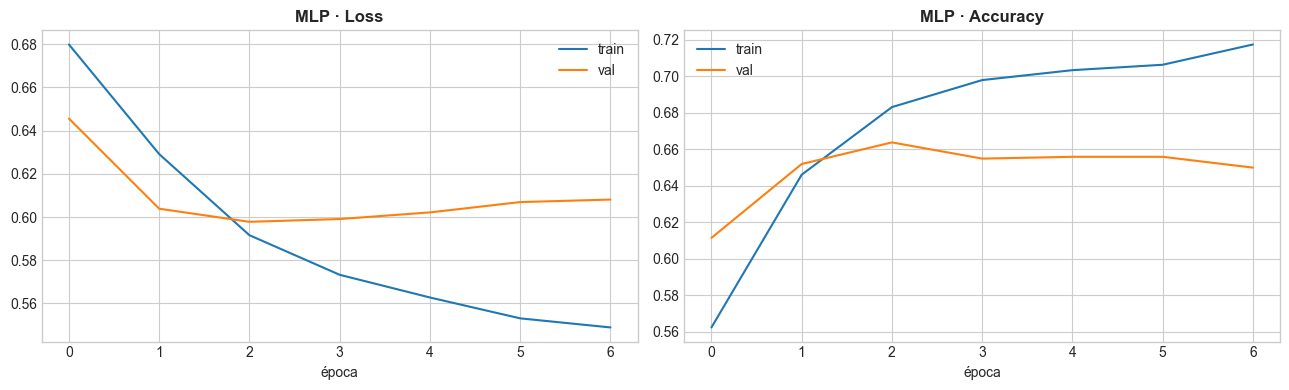

In [26]:
# MLP (PERCEPTRÓN MULTICAPA)  sobre features tabulares
# RESPONSABLE: Ivette Fernàndez

tf.keras.utils.set_random_seed(SEED)                                                                                    # resiembra: la red parte del mismo azar en cada ejecución de la celda
early = EarlyStopping(monitor="val_loss", patience=PACIENCIA,
                      restore_best_weights=True, verbose=0)                                                             # EarlyStopping propio: sin estado heredado de otra red

mlp = Sequential([
    Input(shape=(Xtab_train.shape[1],)),
    Dense(128, activation="relu"),
    Dropout(0.3),                                                                                                       # apaga el 30% de neuronas por paso (anti-coadaptación)
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid"),                                                                                     # sigmoide -> probabilidad en [0,1] para clasificación binaria
])
mlp.compile(optimizer=Adam(LR), loss="binary_crossentropy", metrics=["accuracy"])
mlp.summary()

t0 = time.time()
# validation_split=0.2: reserva un 20% del train como validación, de donde sale el val_loss del EarlyStopping
h_mlp = mlp.fit(Xtab_train, y_train, validation_split=0.2,
                epochs=EPOCHS, batch_size=BATCH, callbacks=[early], verbose=0)
t_fit = time.time() - t0
print(f"\\nEntrenado en {t_fit:.1f}s ({len(h_mlp.history['loss'])} épocas efectivas)\\n")

evaluar_keras("MLP", "Deep Learning · Denso", mlp, Xtab_train, Xtab_test, h_mlp, t_fit)
curva_entrenamiento(h_mlp, "MLP")

**Conclusiones del MLP.**

* **Rendimiento discreto y sesgado.** ROC-AUC test ≈ 0,69 y accuracy ≈ 0,66. La precision (≈ 0,78) está muy por encima del recall (≈ 0,45): marca FAKE solo cuando está bastante segura, así que acierta casi siempre que lo hace, pero deja pasar más de la mitad de las falsas.
* **Errores cargados al falso negativo.** La matriz de confusión concentra los fallos en los FAKE clasificados como REAL, muchos más que al revés.
* **Sobreajuste leve, contenido por EarlyStopping.** La curva lo muestra: la `val_loss` toca su mínimo hacia la época 2 y a partir de ahí sube ligeramente, mientras la `train_loss` sigue bajando. Hay sobreajuste, pero suave: el gap final train-test es de solo ≈ +0,08 (frente al ≈ +0,31 de los otros modelos tabulares). El `restore_best_weights` del EarlyStopping recupera los pesos del mejor punto, y el dropout limita el ajuste. Aun así, lo relevante no es el sobreajuste sino el techo: el train apenas llega a ≈ 0,77, la red no encuentra mucho de lo que agarrarse.
* **Coste bajo.** La parada temprana frena en torno a las 7 épocas (de 30 posibles), así que el entrenamiento es corto pese a ser una red.
* **Por qué no despega, y por qué importa.** El train moderado (≈ 0,77) lo dice: no es que sobreajuste, es que no encuentra de qué agarrarse. Mismo techo que todo el bloque tabular: las features no contienen la señal lingüística que separa FAKE de REAL. Y aquí está la lección del notebook: una red neuronal, con toda su capacidad teórica (aproximación universal), no supera a un K-NN sobre los mismos metadatos. No lo decide el modelo, lo decide la representación.

## 14.2. Red Convolucional 1-D (CNN para texto)

**Qué hace.** Las CNN nacieron para imágenes, pero una *convolución 1-D* sobre la secuencia de embeddings funciona como un *detector de n-gramas*. Cada filtro es una pequeña ventana que se desliza por el texto (aquí de 5 palabras, `kernel_size=5`) buscando combinaciones locales predictivas: una expresión, un giro, una secuencia de términos que delate FAKE o REAL. La red aprende 128 de estos detectores, cada uno especializado en un patrón distinto.

**Por qué "con independencia de la posición".** El mismo filtro recorre toda la secuencia, así que reconoce su patrón aparezca al principio, en medio o al final de la noticia. No le importa *dónde* está la pista, solo si está.

**Qué hace el pooling.** Tras la convolución, `GlobalMaxPooling1D` se queda con la activación más fuerte de cada filtro a lo largo de toda la secuencia: el momento en que ese detector se disparó con más intensidad. Resume cada filtro en un único número (su rasgo más saliente), que pasa a la capa densa para decidir.

**Por qué interesa.** Es rápida (la convolución se paraleliza bien) y muy competitiva en clasificación de texto, a menudo a la altura de redes más complejas.

Arquitectura: `Embedding → Conv1D(128, k=5) → GlobalMaxPool → Dense(64) → Dropout → Dense(1, sigmoide)`.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 417, 128)       │       960,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 413, 128)       │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,050,369 (4.01 MB)

 Trainable params: 1,050,369 (4.01 MB)

 Non-trainable params: 0 (0.00 B)

\nEntrenado en 106.0s (8 épocas efectivas)\n
── CNN 1-D  [Deep Learning · Convolucional]
   Accuracy  test : 0.9526   (train 0.9901)
   Precision test : 0.9569
   Recall    test : 0.9479
   F1        test : 0.9524
   ROC-AUC   test : 0.9917   (train 0.9994)
   Gap AUC        : +0.0076  -> OK sin sobreajuste
   Matriz conf.   : TN=607  FP=27  FN=33  TP=600
   t. entren.     : 106.02 s
   (#14 registrado en 'resultados')


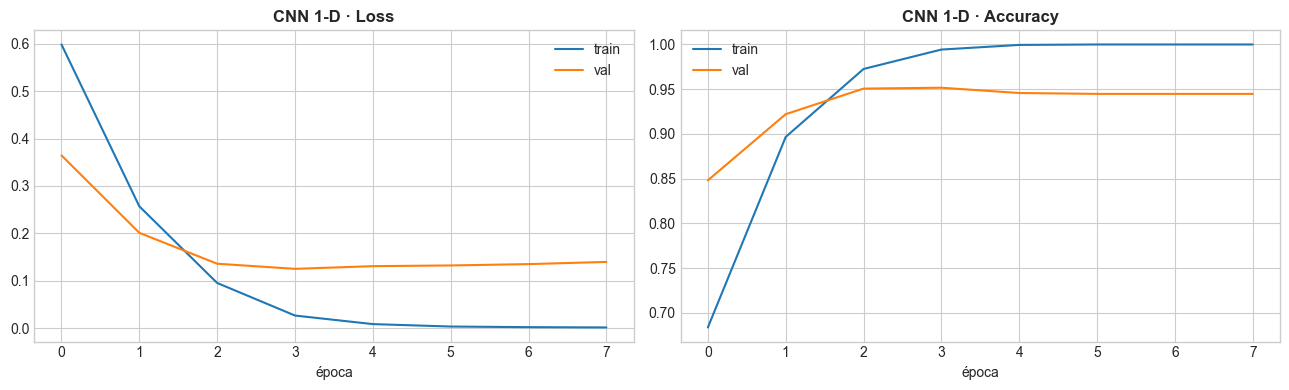

In [27]:
# CNN 1-D  sobre secuencias de embeddings
# RESPONSABLE: Ivette Fernàndez

tf.keras.utils.set_random_seed(SEED)                                                                            # resiembra: la red parte del mismo azar en cada ejecución de la celda
early = EarlyStopping(monitor="val_loss", patience=PACIENCIA,
                      restore_best_weights=True, verbose=0)                                                     # EarlyStopping propio: sin estado heredado de otra red

cnn = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMB_DIM),
    Conv1D(128, kernel_size=5, activation="relu"),                                                              # 128 filtros, cada uno detecta un patrón de 5 palabras (5-gramas)
    GlobalMaxPooling1D(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid"),
])
cnn.compile(optimizer=Adam(LR), loss="binary_crossentropy", metrics=["accuracy"])
cnn.summary()

t0 = time.time()
h_cnn = cnn.fit(Xseq_train, y_train, validation_split=0.2,
                epochs=EPOCHS, batch_size=BATCH, callbacks=[early], verbose=0)
t_fit = time.time() - t0
print(f"\\nEntrenado en {t_fit:.1f}s ({len(h_cnn.history['loss'])} épocas efectivas)\\n")

evaluar_keras("CNN 1-D", "Deep Learning · Convolucional", cnn, Xseq_train, Xseq_test, h_cnn, t_fit)
curva_entrenamiento(h_cnn, "CNN 1-D")

**Conclusiones de la CNN 1-D.**

* **Rendimiento alto y muy equilibrado.** ROC-AUC test ≈ 0,99 (discriminación casi perfecta) y accuracy ≈ 0,95. Precision, recall y F1 quedan casi idénticas (≈ 0,95): detecta FAKE y REAL por igual, sin decantarse por ninguna clase.
* **Errores escasos y casi simétricos.** La matriz de confusión reparte muy pocos fallos entre las dos clases, con un número parecido de falsos positivos y falsos negativos, coherente con el balance 50/50 del dataset (ya barajado, sin el sesgo de ordenación del EDA).
* **Generaliza bien pese a memorizar el train.** La curva es reveladora: la `train_loss` cae casi a cero y la accuracy de train llega a 1,00 (la red memoriza el entrenamiento por completo), pero la `val_loss` toca suelo hacia la época 3 y se mantiene baja, con una accuracy de validación estable en ≈ 0,95. El gap train-test en ROC-AUC es de solo ≈ +0,01: aunque el modelo memoriza, lo que aprende **generaliza** al test. El `EarlyStopping` con `restore_best_weights` recupera los pesos del mejor punto (época 3), no los de la última.
* **Coste alto, el mayor de las redes de texto.** La convolución sobre secuencias de ~417 tokens, con una capa de embedding de más de un millón de parámetros, es pesada pese a paralelizarse. Es el precio de trabajar sobre la secuencia completa.
* **Por qué despega.** Aquí está la diferencia con todo el bloque tabular. La CNN actúa sobre las secuencias (10.7), donde vive la señal: sus filtros detectan combinaciones de palabras (n-gramas) que delatan FAKE o REAL, lo que las features tabulares no contenían. No es más potente que un Random Forest, simplemente por fin ve la representación adecuada.

## 14.3. Red Recurrente LSTM

**Qué hace.** Las redes recurrentes (*RNN*) procesan el texto palabra a palabra, manteniendo un *estado oculto* que resume lo leído hasta el momento: una especie de memoria que se actualiza con cada palabra nueva. Así capturan el orden y la dependencia entre palabras distantes, algo que la CNN solo veía en ventanas locales.

**El problema que resuelve.** Las RNN simples sufren *vanishing gradients*: en secuencias largas, la señal de las primeras palabras se desvanece y la red "olvida" el principio del texto. La *LSTM* (Long Short-Term Memory) lo soluciona añadiendo un *estado de celda*, un canal de memoria a largo plazo que la información puede recorrer sin degradarse.

**Las tres compuertas.** Ese estado de celda se regula con tres compuertas que la red aprende: *forget* (qué olvidar de la memoria), *input* (qué información nueva incorporar) y *output* (qué exponer al siguiente paso). Esa gestión selectiva de la memoria es lo que le permite retener lo relevante a lo largo de toda la secuencia.

**Por qué interesa.** Es la arquitectura de referencia para texto secuencial: capta dependencias largas que CNN y modelos clásicos no ven.

Arquitectura: `Embedding → LSTM(64) → Dense(64) → Dropout → Dense(1, sigmoide)`.

La regularización actúa en dos puntos: el `dropout=0.2` interno de la capa LSTM (apaga parte de las entradas de la celda) y la capa `Dropout` posterior al `Dense`.

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 417, 128)       │       960,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,013,633 (3.87 MB)

 Trainable params: 1,013,633 (3.87 MB)

 Non-trainable params: 0 (0.00 B)

\nEntrenado en 130.6s (7 épocas efectivas)\n
── LSTM  [Deep Learning · Recurrente]
   Accuracy  test : 0.7987   (train 0.8629)
   Precision test : 0.7467
   Recall    test : 0.9036
   F1        test : 0.8177
   ROC-AUC   test : 0.8806   (train 0.9517)
   Gap AUC        : +0.0711  -> leve
   Matriz conf.   : TN=440  FP=194  FN=61  TP=572
   t. entren.     : 130.62 s
   (#15 registrado en 'resultados')


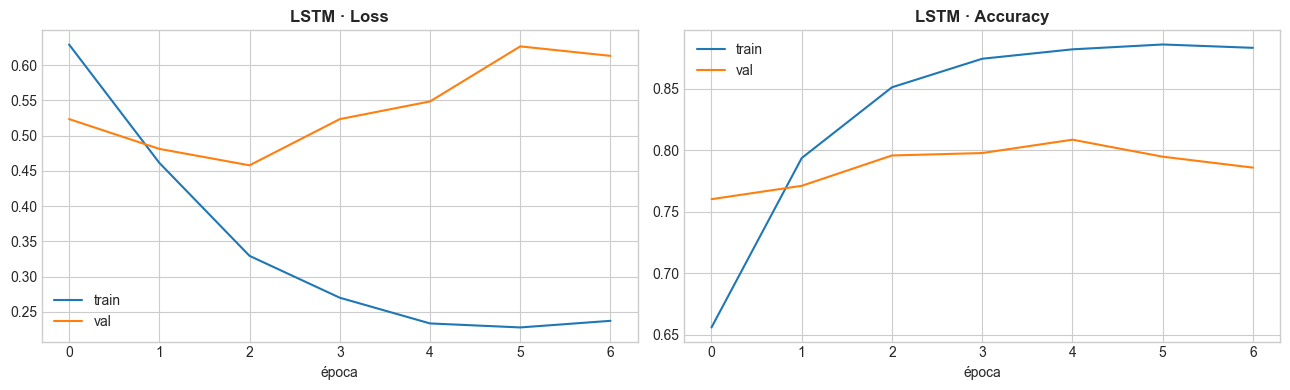

In [28]:
# LSTM  sobre secuencias de embeddings
# RESPONSABLE: Andrea Berna

tf.keras.utils.set_random_seed(SEED)                                                                        # resiembra: la red parte del mismo azar en cada ejecución de la celda
early = EarlyStopping(monitor="val_loss", patience=PACIENCIA,
                      restore_best_weights=True, verbose=0)                                                 # EarlyStopping propio: sin estado heredado de otra red

lstm = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMB_DIM),
    LSTM(64, dropout=0.2, recurrent_dropout=0.0),                                                           # dropout=0.2: apaga entradas de la capa; recurrent_dropout=0.0 para no perder aceleración en GPU
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid"),
])
lstm.compile(optimizer=Adam(LR), loss="binary_crossentropy", metrics=["accuracy"])
lstm.summary()

t0 = time.time()
h_lstm = lstm.fit(Xseq_train, y_train, validation_split=0.2,
                  epochs=EPOCHS, batch_size=BATCH, callbacks=[early], verbose=0)
t_fit = time.time() - t0
print(f"\\nEntrenado en {t_fit:.1f}s ({len(h_lstm.history['loss'])} épocas efectivas)\\n")

evaluar_keras("LSTM", "Deep Learning · Recurrente", lstm, Xseq_train, Xseq_test, h_lstm, t_fit)
curva_entrenamiento(h_lstm, "LSTM")

**Conclusiones de la LSTM.**

* **Rendimiento aceptable y muy sesgado al recall.** ROC-AUC test ≈ 0,88 (aceptable) y accuracy ≈ 0,80. El contraste entre recall (≈ 0,90) y precision (≈ 0,75) es fuerte: detecta casi todos los FAKE reales, pero a costa de marcar como FAKE bastantes noticias que no lo son.
* **Errores cargados en los falsos positivos.** La matriz de confusión lo confirma: se le escapan muy pocos FAKE (de ahí el recall alto), pero muchos REAL acaban marcados como FAKE. Es un clasificador "alarmista": ante la duda, dice FAKE.
* **Sobreajuste temprano, contenido por EarlyStopping.** La curva de entrenamiento lo muestra con claridad: la `val_loss` toca su mínimo en la época 2 y a partir de ahí sube, mientras la `train_loss` sigue bajando. Es el patrón típico de sobreajuste. El `EarlyStopping` con `restore_best_weights=True` lo neutraliza: aunque el entrenamiento continúa unas épocas más por la paciencia configurada, la red recupera finalmente los pesos de la época 2 (la de mejor validación). Por eso el gap final train-test se mantiene moderado (≈ +0,07): las métricas reportadas son las del mejor punto, no las de la última época.
* **Coste alto.** La LSTM procesa la secuencia token a token (~417 pasos por noticia), un cómputo que por definición no se paraleliza como la convolución. De ahí que sea de las redes más lentas.
* **Por qué funciona, pero a medias.** Accede a la señal lingüística de las secuencias (10.7), por eso supera con holgura el techo tabular: su memoria con compuertas capta dependencias entre palabras. Pero el punto de operación es desequilibrado (mucho recall, poca precision): detecta los FAKE a costa de falsas alarmas. Necesitaría más ajuste (épocas, regularización, learning rate) para igualar a un detector más directo.

## 14.4. Red Recurrente GRU

**Qué hace.** La *GRU* (Gated Recurrent Unit) es una versión simplificada de la LSTM (14.3). Persigue el mismo objetivo, retener información relevante a lo largo de la secuencia, pero con una maquinaria más ligera.

**Qué simplifica respecto a la LSTM.** Dos cambios: fusiona las compuertas *forget* e *input* de la LSTM en una sola *compuerta de actualización*, que decide de una vez qué olvidar y qué incorporar; y elimina el estado de celda separado, usando una única línea de memoria en lugar de dos. Menos compuertas y menos canales significan menos parámetros que aprender.

**Por qué interesa.** Al tener menos parámetros, entrena más rápido y necesita menos datos para ajustarse, con un rendimiento comparable al de la LSTM en muchos problemas. Es la alternativa natural cuando se quiere la capacidad de una recurrente con menor coste.

Arquitectura: `Embedding → GRU(64) → Dense(64) → Dropout → Dense(1, sigmoide)`.

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 417, 128)       │       960,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,001,473 (3.82 MB)

 Trainable params: 1,001,473 (3.82 MB)

 Non-trainable params: 0 (0.00 B)

\nEntrenado en 115.8s (6 épocas efectivas)\n
── GRU  [Deep Learning · Recurrente]
   Accuracy  test : 0.7766   (train 0.8311)
   Precision test : 0.7255
   Recall    test : 0.8894
   F1        test : 0.7991
   ROC-AUC   test : 0.8444   (train 0.9112)
   Gap AUC        : +0.0669  -> leve
   Matriz conf.   : TN=421  FP=213  FN=70  TP=563
   t. entren.     : 115.76 s
   (#16 registrado en 'resultados')


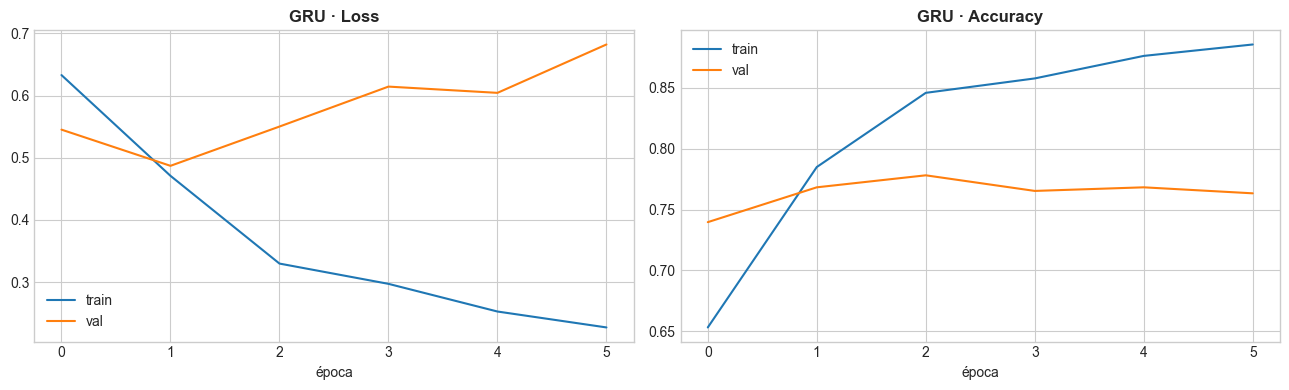

In [29]:
# GRU  sobre secuencias de embeddings
# RESPONSABLE: Jordi Rabadan

tf.keras.utils.set_random_seed(SEED)                                                                    # resiembra: la red parte del mismo azar en cada ejecución de la celda
early = EarlyStopping(monitor="val_loss", patience=PACIENCIA,
                      restore_best_weights=True, verbose=0)                                             # EarlyStopping propio: sin estado heredado de otra red

gru = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMB_DIM),
    GRU(64, dropout=0.2, recurrent_dropout=0.0),                                                        # recurrent_dropout=0.0: mantiene la aceleración en GPU (cuDNN)
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid"),
])
gru.compile(optimizer=Adam(LR), loss="binary_crossentropy", metrics=["accuracy"])
gru.summary()

t0 = time.time()
h_gru = gru.fit(Xseq_train, y_train, validation_split=0.2,
                epochs=EPOCHS, batch_size=BATCH, callbacks=[early], verbose=0)
t_fit = time.time() - t0
print(f"\\nEntrenado en {t_fit:.1f}s ({len(h_gru.history['loss'])} épocas efectivas)\\n")

evaluar_keras("GRU", "Deep Learning · Recurrente", gru, Xseq_train, Xseq_test, h_gru, t_fit)
curva_entrenamiento(h_gru, "GRU")

**Conclusiones de la GRU.**

* **Rendimiento aceptable e inclinado al recall.** ROC-AUC test ≈ 0,84 (aceptable) y accuracy ≈ 0,77. El recall (≈ 0,89) va por delante de la precision (≈ 0,73): detecta bien los FAKE reales, aunque marca como FAKE algunas noticias que no lo son.
* **Errores cargados en los falsos positivos.** La matriz de confusión reparte los fallos con más peso en los falsos positivos (REAL marcados como FAKE) que en los falsos negativos, coherente con el recall alto.
* **Sobreajuste temprano, contenido por EarlyStopping.** La curva lo muestra con nitidez: la `val_loss` toca su mínimo ya en la época 1 y a partir de ahí sube de forma sostenida, mientras la `train_loss` sigue cayendo. Es sobreajuste claro, algo más marcado que en la LSTM. El `restore_best_weights` del EarlyStopping recupera los pesos de ese mejor punto, y por eso el gap final se queda moderado (≈ +0,07): las métricas reportadas son las del mejor momento, no las de la última época.
* **Coste alto.** Como toda recurrente, procesa la secuencia token a token (~417 pasos), un cómputo secuencial no paralelizable. De ahí que esté entre las redes más lentas.
* **Por qué funciona.** Accede a la señal lingüística de las secuencias (10.7) y la explota con su memoria de compuertas, por eso supera el techo tabular. Su recurrencia simplificada (menos parámetros que la LSTM) le basta para una discriminación aceptable.

## 14.5. LSTM Bidireccional (BiLSTM)

**Qué hace.** Una LSTM normal (14.3) lee el texto en un solo sentido, de izquierda a derecha, así que al procesar una palabra solo conoce lo que vino *antes*. La *BiLSTM* ejecuta dos LSTM en paralelo: una recorre la secuencia hacia delante y otra hacia atrás. Sus salidas se concatenan, de modo que cada palabra se interpreta con su contexto *pasado y futuro* a la vez.

**Por qué el contexto futuro ayuda.** El significado de una palabra a menudo depende de lo que viene después, no solo de lo anterior. Leer también hacia atrás permite a la red desambiguar usando el final de la frase, algo que una LSTM unidireccional no puede.

**Por qué interesa.** Fue el estándar de referencia para NLP antes de los Transformers (tareas como reconocimiento de entidades o etiquetado), y suele ser la recurrente con mejor desempeño, a costa de duplicar el cómputo (procesa la secuencia dos veces).

Arquitectura: `Embedding → Bidirectional(LSTM 64) → Dense(64) → Dropout → Dense(1, sigmoide)`.

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 417, 128)       │       960,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,067,137 (4.07 MB)

 Trainable params: 1,067,137 (4.07 MB)

 Non-trainable params: 0 (0.00 B)

\nEntrenado en 238.8s (7 épocas efectivas)\n
── BiLSTM  [Deep Learning · Recurrente]
   Accuracy  test : 0.9219   (train 0.9850)
   Precision test : 0.9225
   Recall    test : 0.9210
   F1        test : 0.9217
   ROC-AUC   test : 0.9779   (train 0.9982)
   Gap AUC        : +0.0204  -> OK sin sobreajuste
   Matriz conf.   : TN=585  FP=49  FN=50  TP=583
   t. entren.     : 238.8 s
   (#17 registrado en 'resultados')


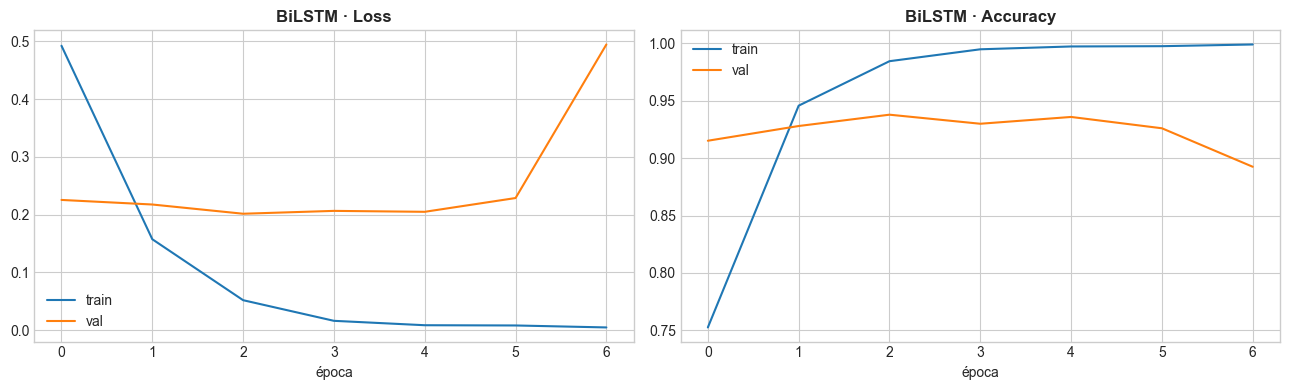

In [30]:
# LSTM BIDIRECCIONAL
# RESPONSABLE: Javier Espina

tf.keras.utils.set_random_seed(SEED)                                                                        # resiembra: la red parte del mismo azar en cada ejecución de la celda
early = EarlyStopping(monitor="val_loss", patience=PACIENCIA,
                      restore_best_weights=True, verbose=0)                                                 # EarlyStopping propio: sin estado heredado de otra red

bilstm = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMB_DIM),
    Bidirectional(LSTM(64, dropout=0.2, recurrent_dropout=0.0)),                                            # dos LSTM(64): una hacia delante, otra hacia atrás
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid"),
])
bilstm.compile(optimizer=Adam(LR), loss="binary_crossentropy", metrics=["accuracy"])
bilstm.summary()

t0 = time.time()
h_bi = bilstm.fit(Xseq_train, y_train, validation_split=0.2,
                  epochs=EPOCHS, batch_size=BATCH, callbacks=[early], verbose=0)
t_fit = time.time() - t0
print(f"\\nEntrenado en {t_fit:.1f}s ({len(h_bi.history['loss'])} épocas efectivas)\\n")

evaluar_keras("BiLSTM", "Deep Learning · Recurrente", bilstm, Xseq_train, Xseq_test, h_bi, t_fit)
curva_entrenamiento(h_bi, "BiLSTM")

**Conclusiones de la BiLSTM.**

* **Rendimiento alto y equilibrado.** ROC-AUC test ≈ 0,98 (discriminación casi perfecta) y accuracy ≈ 0,92. Precision y recall parejos (≈ 0,92): detecta FAKE y REAL de forma proporcionada, sin decantarse por ninguna clase. Es la recurrente con mejor desempeño global.
* **Errores escasos y casi simétricos.** La matriz de confusión reparte pocos fallos entre las dos clases, con un número parecido de falsos positivos y falsos negativos.
* **Generaliza pese a sobreajustar al final.** La curva es clara: la `val_loss` se mantiene baja y estable hasta la época 4, pero en las últimas épocas se dispara mientras la `train_loss` cae casi a cero y la accuracy de train llega a 1,00. Hay sobreajuste, y brusco al final. El `restore_best_weights` del EarlyStopping rescata los pesos de la época 4 (el mejor punto, antes del desplome), y por eso el gap final se queda en solo ≈ +0,02: lo reportado es el mejor momento, no la última época, donde la red ya había empezado a memorizar.
* **El más costoso de todas las redes.** Al ser bidireccional, procesa cada secuencia dos veces (hacia delante y hacia atrás), lo que duplica el cómputo recurrente.
* **Por qué funciona bien.** Accede a la señal de las secuencias (10.7) y, además, la lee en ambos sentidos: cada palabra recibe contexto pasado y futuro. Esa visión completa de la frase la eleva por encima de las recurrentes unidireccionales: capta dependencias que una LSTM o GRU simple, limitadas a mirar atrás, no alcanzan a ver.

# 15. Comparativa global y selección de modelo

**Qué se hace aquí.** Con los 17 modelos evaluados bajo el mismo protocolo (idéntico split, umbral 0,5, y la misma función `evaluar_modelo`), se consolida el acumulador `resultados` en una *tabla maestra*. Tenerlos a todos en igualdad de condiciones es lo que hace la comparación legítima: cualquier diferencia de rendimiento se atribuye al modelo y su representación, no al método de evaluación.

**Qué se compara.** No solo el AUC. La decisión cruza tres ejes:

* *Discriminación* (ROC-AUC test): la métrica de gobierno, independiente del umbral, para rankear.
* *Punto de operación* (precision, recall, F1 a umbral 0,5): cómo reparte el modelo sus aciertos entre FAKE y REAL.
> **Nota sobre el tiempo de entrenamiento.** La tabla incluye el tiempo de cómputo de cada modelo, pero **no se usa como criterio de selección**. Ese tiempo depende del hardware y no es reproducible entre equipos (ver la nota de reproducibilidad en 9.3), así que aquí se muestra solo con fin ilustrativo, para dar idea del coste relativo de cada familia. La decisión del modelo final se basa exclusivamente en las métricas de rendimiento y en el control de sobreajuste.

**Qué esperamos ver.** El hilo de todo el notebook se materializa aquí, y la clave es la *representación*, no el tipo de modelo. Los modelos que solo ven las *features tabulares* (metadatos: conteos, longitudes, formato) toparon todos en un mismo techo (~0,69 AUC), da igual que sean clásicos, ensembles o el MLP: ni la red neuronal supera ese límite, porque no lo pone el modelo sino los datos. En cambio, en cuanto el modelo accede al *texto*, como bolsa de palabras (*TF-IDF*) o como secuencia ordenada (*embeddings*), el rendimiento despega. La tabla debería mostrar esa frontera nítida: la señal que distingue FAKE de REAL vive en el texto, y cualquier representación que lo capture, por simple que sea, bate a la mejor sobre metadatos.

## 15.1. Tabla maestra de métricas

Se ordena por **ROC-AUC en test** (la *métrica de gobierno*: independiente del umbral, sirve para rankear). Las columnas permiten contrastar varios ejes a la vez: discriminación (*AUC*), balance entre clases (*F1*), coste de los errores (*precision/recall*), estabilidad (*gap* train-test, señal de sobreajuste) y eficiencia (*tiempo* `t_fit_s` y *tramo de coste*).

La columna *Representación* (Tabular / TF-IDF / Secuencias) es la clave de lectura: al ordenar por AUC, se hace visible que el rendimiento se agrupa por representación más que por familia de modelo. Los que solo ven *features tabulares* quedan juntos en el tramo bajo; los que acceden al *texto* (TF-IDF o secuencias) ocupan el tramo alto.

In [31]:
# TABLA MAESTRA DE RESULTADOS
# Tres ejes descriptivos, cada uno con un único significado:
#   Categoria      -> grupo grande del modelo
#   Tipo           -> mecánica interna (1-2 palabras que lo distinguen)
#   Representación -> qué datos consume
INFO_MODELO = {
    #  Modelo                              : (Categoria,              Tipo,            Representación)
    "Regresión Logística"                  : ("Clásico supervisado",  "Lineal",         "TF-IDF"),
    "Naive Bayes Multinomial"              : ("Clásico supervisado",  "Probabilístico", "TF-IDF"),
    "SVM (kernel lineal)"                  : ("Clásico supervisado",  "Kernel",         "TF-IDF"),
    "K-NN (k=15)"                          : ("Clásico supervisado",  "Vecindad",       "Tabular"),
    "Naive Bayes Gaussiano"                : ("Clásico supervisado",  "Probabilístico", "Tabular"),
    "Árbol de Decisión (CART)"             : ("Clásico supervisado",  "Árbol",          "Tabular"),
    "Random Forest"                        : ("Ensemble",             "Bagging",        "Tabular"),
    "Extra Trees"                          : ("Ensemble",             "Bagging",        "Tabular"),
    "AdaBoost"                             : ("Ensemble",             "Boosting",       "Tabular"),
    "Gradient Boosting"                    : ("Ensemble",             "Boosting",       "Tabular"),
    "Hist-Gradient Boosting (sklearn)"     : ("Ensemble",             "Boosting",       "Tabular"),
    "Stacking (RF+GB+KNN)"                 : ("Ensemble",             "Stacking",       "Tabular"),
    "MLP"                                  : ("Deep Learning",        "Denso",          "Tabular"),
    "CNN 1-D"                              : ("Deep Learning",        "Convolucional",  "Secuencias"),
    "LSTM"                                 : ("Deep Learning",        "Recurrente",     "Secuencias"),
    "GRU"                                  : ("Deep Learning",        "Recurrente",     "Secuencias"),
    "BiLSTM"                               : ("Deep Learning",        "Recurrente bi",  "Secuencias"),
}

tabla = pd.DataFrame(resultados)
tabla["Categoría"]      = tabla["Modelo"].map(lambda m: INFO_MODELO[m][0])
tabla["Tipo"]           = tabla["Modelo"].map(lambda m: INFO_MODELO[m][1])
tabla["Representación"] = tabla["Modelo"].map(lambda m: INFO_MODELO[m][2])

# Coste de entrenamiento por tramos, relativo a cada ejecución (dato informativo, no criterio de selección)
pct = tabla["t_fit_s"].rank(pct=True, method="average")                       # posición percentil de cada modelo [0-1)
tabla["Coste entrenamiento"] = pd.cut(
    pct, bins=[0, 0.2, 0.4, 0.6, 0.8, np.inf],                                # <p20 / [p20,p40) / [p40,p60) / [p60,p80) / >=p80
    labels=["Muy bajo", "Bajo", "Medio", "Alto", "Muy alto"],
    right=False)                                                              # cerrado por la izquierda: el p20 cae en "Bajo"

cols = ["Modelo", "Categoría", "Tipo", "Representación",
        "Acc_test", "Prec_test", "Rec_test", "F1_test",
        "AUC_test", "AUC_train", "Gap_AUC", "t_fit_s", "Coste entrenamiento"]
tabla = tabla[cols].sort_values("AUC_test", ascending=False).reset_index(drop=True)
tabla.insert(0, "Rank", tabla.index + 1)

# Formato: 2 decimales para las métricas, 3 decimales solo para el Gap_AUC
fmt = {c: "{:.2f}" for c in ["Acc_test", "Prec_test", "Rec_test", "F1_test",
                             "AUC_test", "AUC_train", "t_fit_s"]}
fmt["Gap_AUC"] = "{:.3f}"

display(tabla.style.format(fmt).background_gradient(
        subset=["AUC_test"], cmap="Greens").hide(axis="index").set_caption(
        f"Comparativa de {len(tabla)} modelos · ordenada por ROC-AUC (test)"))

# Exportación a la carpeta local de descargas
ruta_descargas_local = Path('.') / "descargas"
ruta_descargas_local.mkdir(parents=True, exist_ok=True)
ruta_export = ruta_descargas_local / "15.1. Comparativa_modelos.csv"
tabla.to_csv(ruta_export, index=False, encoding='utf-8')
print(f"✅ Comparativa exportada a: '{ruta_export}'")

Rank,Modelo,Categoría,Tipo,Representación,Acc_test,Prec_test,Rec_test,F1_test,AUC_test,AUC_train,Gap_AUC,t_fit_s,Coste entrenamiento
1,CNN 1-D,Deep Learning,Convolucional,Secuencias,0.95,0.96,0.95,0.95,0.99,1.00,0.008,106.02,Alto
2,SVM (kernel lineal),Clásico supervisado,Kernel,TF-IDF,0.94,0.94,0.94,0.94,0.99,1.00,0.012,213.05,Muy alto
3,Regresión Logística,Clásico supervisado,Lineal,TF-IDF,0.93,0.93,0.93,0.93,0.98,0.99,0.012,0.40,Bajo
4,BiLSTM,Deep Learning,Recurrente bi,Secuencias,0.92,0.92,0.92,0.92,0.98,1.00,0.020,238.80,Muy alto
5,Naive Bayes Multinomial,Clásico supervisado,Probabilístico,TF-IDF,0.89,0.88,0.91,0.89,0.96,0.97,0.011,0.02,Muy bajo
6,LSTM,Deep Learning,Recurrente,Secuencias,0.80,0.75,0.90,0.82,0.88,0.95,0.071,130.62,Muy alto
7,GRU,Deep Learning,Recurrente,Secuencias,0.78,0.73,0.89,0.80,0.84,0.91,0.067,115.76,Muy alto
8,Naive Bayes Gaussiano,Clásico supervisado,Probabilístico,Tabular,0.65,0.69,0.54,0.60,0.69,0.73,0.035,0.04,Muy bajo
9,Random Forest,Ensemble,Bagging,Tabular,0.66,0.79,0.44,0.56,0.69,0.98,0.283,1.81,Bajo
10,MLP,Deep Learning,Denso,Tabular,0.66,0.78,0.45,0.57,0.69,0.77,0.080,4.26,Medio


✅ Comparativa exportada a: 'descargas\15.1. Comparativa_modelos.csv'


### 15.1.1. Lecturas por subfamilia

**Los ensembles tabulares: mucha maquinaria, mismo techo.** Random Forest, Extra Trees, AdaBoost, Gradient Boosting, Hist-GB y Stacking se agolpan en torno a 0,68-0,69 de AUC, indistinguibles entre sí pese a mecánicas muy distintas (bagging, boosting, meta-aprendizaje) y al mismo presupuesto de 300 estimadores. La conclusión es contundente: sobre las *features tabulares*, combinar árboles no rompe el techo, solo lo confirma. El Stacking, que combina tres modelos para superarlos, se queda en la misma banda que sus bases: no se puede agregar señal que no existe.

**Boosting vs bagging (tabular): sin diferencia práctica.** Ni el boosting (reduce sesgo) ni el bagging (reduce varianza) despegan: todos, de AdaBoost a Random Forest, quedan en la misma banda de ≈ 0,68-0,69. La teoría predice comportamientos distintos, pero con una representación sin señal, todas las estrategias convergen al mismo punto pobre. Un resultado didáctico: la elección de ensemble es secundaria cuando el cuello de botella son los datos.

**Los lineales/probabilísticos sobre TF-IDF: rendimiento de primera con modelos simples.** Regresión Logística (≈ 0,98), SVM (≈ 0,99) y NB Multinomial (≈ 0,96) ocupan el tramo altísimo. Lección: para texto como bolsa de palabras, un modelo lineal simple basta para una discriminación casi perfecta, sin necesidad de deep learning.

**Las redes secuenciales: la arquitectura sí importa, pero no como se esperaba.** Entre las cuatro redes de texto con idéntico presupuesto (embedding 128, 64 unidades, misma cola), el rango es amplio: CNN (≈ 0,99) y BiLSTM (≈ 0,98) arriba, LSTM (≈ 0,88) y GRU (≈ 0,84) más abajo. La lectura: las recurrentes unidireccionales simples (LSTM, GRU) rinden por debajo de un detector de n-gramas (CNN) y de la recurrente bidireccional (BiLSTM). Procesar el orden token a token no garantiza mejor resultado que capturar combinaciones locales de palabras; y leer en ambos sentidos (BiLSTM) sí aporta un salto claro sobre leer en uno solo.

**El MLP, la prueba de control.** Es la pieza más reveladora de la tabla. Una red neuronal (Deep Learning) que, por usar la representación *tabular*, queda en ≈ 0,69, hundida entre los ensembles, lejos de sus hermanas de secuencias. Demuestra que el factor decisivo no es la sofisticación del modelo, sino la representación: la misma familia que lidera la tabla (deep learning) también habita el tramo bajo cuando mira los datos equivocados.

## 15.2. Visualizaciones

La tabla maestra (15.1) ordena y cuantifica, pero tres vistas gráficas hacen visibles de un solo golpe los patrones que en cifras requieren lectura atenta. Cada una ataca una pregunta distinta:

* **Barras de AUC y F1:** el ranking de rendimiento, coloreado por representación: muestra cómo los modelos se agrupan por *cómo ven los datos* (Tabular, TF-IDF, Secuencias) más que por su familia.
* **Curvas ROC del Top-6:** el comportamiento de los mejores modelos a lo largo de todos los umbrales de decisión, no solo en el corte 0,5.
* **Gap de sobreajuste:** qué modelos memorizan el train sin generalizar, ordenados y semaforizados por nivel de gap.

En conjunto, las tres traducen a imagen la conclusión central: la frontera de rendimiento la marca la representación, no la sofisticación del modelo.

### 15.2.1.  Gràfico de barras AUC y F1

Dos paneles de barras horizontales, *ROC-AUC* y *F1* en test, ordenados de mayor a menor. Se eligen estas dos métricas porque son complementarias: el **AUC** mide la **discriminación** (capacidad de separar clases, independiente del umbral), mientras que el **F1** mide el **equilibrio** en él punto de operación 0,5 (media de precision y recall). Un modelo puede tener buen AUC pero F1 bajo si está desbalanceado, así que verlas juntas distingue a los modelos sólidos de los que solo brillan en una.

El **color codifica la representación** (Tabular, TF-IDF, Secuencias), no la familia del modelo. Es la clave de lectura: al ordenar por rendimiento, los colores no se mezclan al azar, sino que se separan en bloques. El gráfico hace visible de un vistazo lo que la tabla muestra en cifras: que el rendimiento depende de cómo el modelo ve los datos, no de su sofisticación.

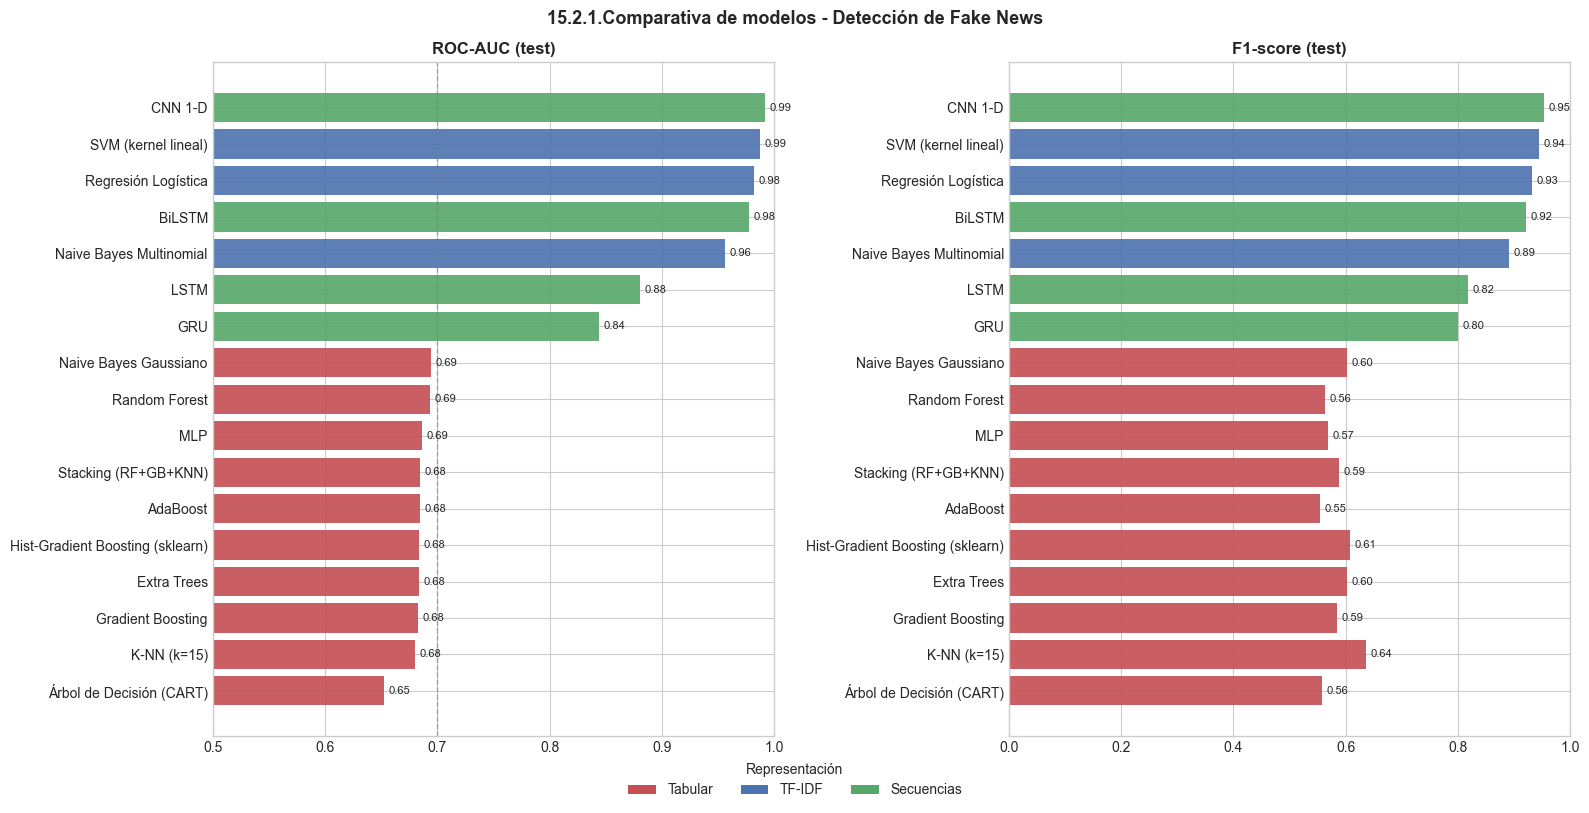

In [32]:
# GRÁFICO COMPARATIVO (AUC y F1, coloreado por representación)
from pathlib import Path
import matplotlib.pyplot as plt

t_plot = tabla.sort_values("AUC_test")

# Color por representación: hace visible que el rendimiento se agrupa por cómo el modelo ve los datos
COLOR_REP = {"Tabular": "#c44e52", "TF-IDF": "#4c72b0", "Secuencias": "#55a868"}
colores = t_plot["Representación"].map(COLOR_REP)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))

# --- ROC-AUC ---
ax[0].barh(t_plot["Modelo"], t_plot["AUC_test"], color=colores, alpha=.9)
ax[0].set_title("ROC-AUC (test)", fontweight="bold")
ax[0].set_xlim(0.5, 1.0)
ax[0].axvline(0.7, color="grey", ls="--", lw=1, alpha=.6)
for i, v in enumerate(t_plot["AUC_test"]):
    ax[0].text(v + 0.004, i, f"{v:.2f}", va="center", fontsize=8)

# --- F1 ---
ax[1].barh(t_plot["Modelo"], t_plot["F1_test"], color=colores, alpha=.9)
ax[1].set_title("F1-score (test)", fontweight="bold")
ax[1].set_xlim(0.0, 1.0)
for i, v in enumerate(t_plot["F1_test"]):
    ax[1].text(v + 0.008, i, f"{v:.2f}", va="center", fontsize=8)

# Leyenda de representación (compartida)
from matplotlib.patches import Patch
leyenda = [Patch(facecolor=c, label=r) for r, c in COLOR_REP.items()]
fig.legend(handles=leyenda, title="Representación", loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))

plt.suptitle("15.2.1.Comparativa de modelos - Detección de Fake News", fontweight="bold", fontsize=13)
plt.tight_layout(rect=[0, 0.03, 1, 1])

# 🛠️ CORRECCIÓN: Enrutamiento al pipeline local de descargas
ruta_descargas = Path('.') / "descargas"
ruta_descargas.mkdir(parents=True, exist_ok=True) # Crea la carpeta si no existía
plt.savefig(ruta_descargas / "15.2.1. Comparativa_modelos.png", dpi=200, bbox_inches="tight")
plt.show()

**Lectura del gráfico.** La separación por color es inmediata: las representaciones de texto (TF-IDF en azul, Secuencias en verde) copan el tramo alto, y todo el bloque *Tabular* (rojo) se hunde por debajo de 0,70 de AUC sin excepción. No hay un solo modelo tabular entre los siete primeros, ni un solo modelo de texto entre los diez últimos. La frontera es limpia.

**Lo que el doble panel añade.** Comparar AUC y F1 lado a lado distingue a los modelos sólidos de los que discriminan bien pero operan desequilibrados. Los líderes (CNN, SVM, LogReg, BiLSTM) mantienen valores altos y parejos en *ambas* métricas: separan las clases y además aciertan equilibrados en el umbral 0,5. La LSTM y la GRU, en cambio, ceden más terreno del AUC al F1 (LSTM de ≈ 0,88 a ≈ 0,82; GRU de ≈ 0,84 a ≈ 0,80) que los de cabeza: discriminan de forma aceptable, pero su punto de operación está desbalanceado (mucho recall, poca precision), y el F1 lo refleja. Un AUC decente no garantiza un buen F1.

**El detalle del bloque tabular.** Dentro del rojo, el orden apenas importa: del ≈ 0,65 del CART al ≈ 0,69 del Random Forest (y el Naive Bayes Gaussiano) hay un margen mínimo, y modelos de naturaleza opuesta (un árbol simple, un bagging, un boosting, una red densa) quedan prácticamente empatados. Cuando la representación no tiene señal, la elección de algoritmo deja de marcar diferencia.

### 15.2.2. Curvas ROC superpuestas (Top-6)

La *curva ROC* traza, para cada modelo, su tasa de aciertos (verdaderos positivos) frente a su tasa de falsas alarmas (falsos positivos) a medida que se barre el umbral de decisión de 0 a 1. Cuanto más se acerca una curva a la esquina superior izquierda, mejor: más aciertos con menos falsas alarmas. La diagonal representa el azar. Superponerlas permite comparar los seis mejores modelos en *todos* los umbrales, no solo en el corte 0,5 que fija las métricas de la tabla.

Un detalle revelador: los seis mejores pertenecen únicamente a las representaciones de *texto* (TF-IDF y Secuencias). Ningún modelo tabular alcanza el top-6, lo que vuelve a confirmar, ahora en términos de curva completa, que la frontera de rendimiento la marca la representación.

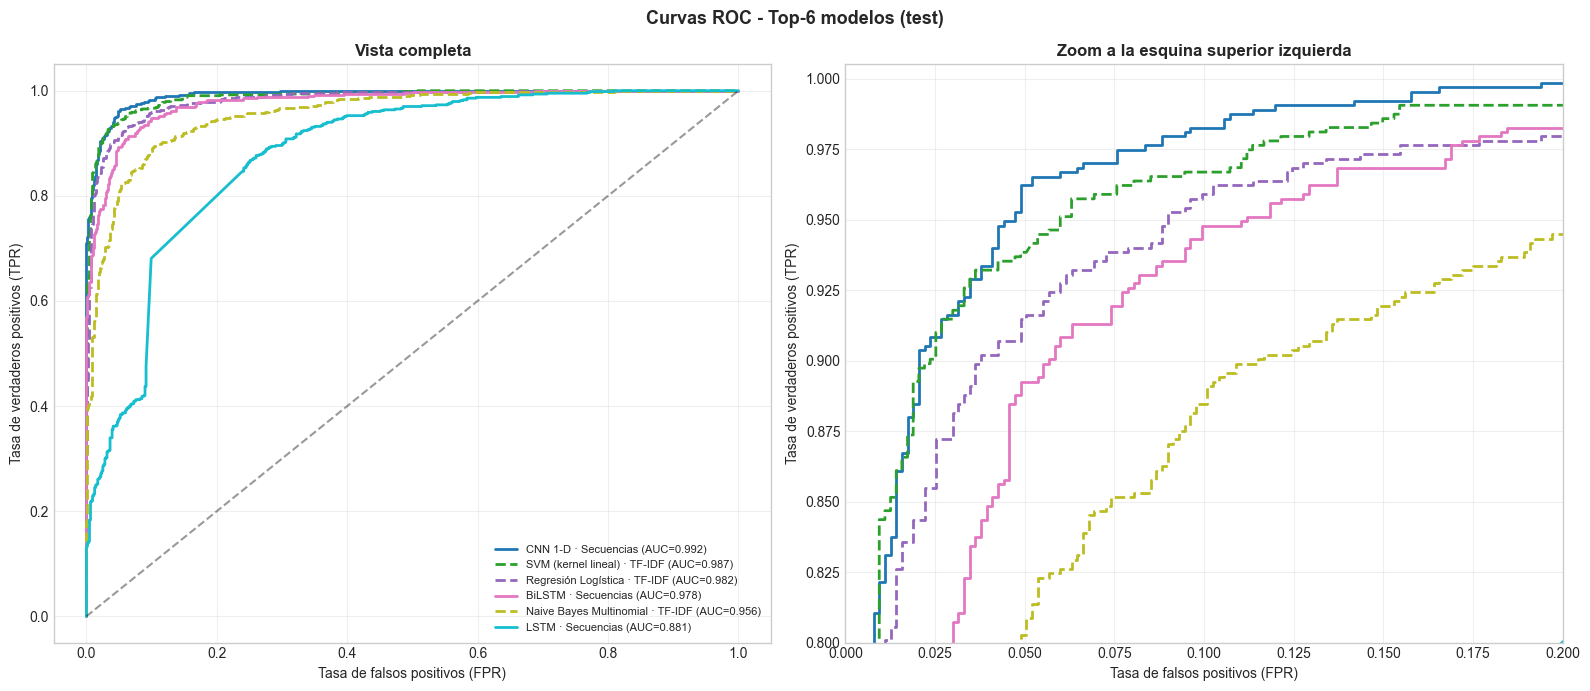

In [33]:
# CURVAS ROC DE LOS 6 MEJORES MODELOS
from pathlib import Path
import matplotlib.pyplot as plt

probas_test = {
    "Regresión Logística":      logreg.predict_proba(Xtxt_test)[:,1],
    "Naive Bayes Multinomial":  mnb.predict_proba(Xtxt_test)[:,1],
    "SVM (kernel lineal)":      svm.predict_proba(Xtxt_test)[:,1],
    "K-NN (k=15)":              knn.predict_proba(X_test)[:,1],
    "Naive Bayes Gaussiano":    gnb.predict_proba(X_test)[:,1],
    "Árbol de Decisión (CART)": cart.predict_proba(X_test)[:,1],
    "Random Forest":            rf.predict_proba(X_test)[:,1],
    "Extra Trees":              et.predict_proba(X_test)[:,1],
    "AdaBoost":                 ada.predict_proba(X_test)[:,1],
    "Gradient Boosting":        gb.predict_proba(X_test)[:,1],
    "Hist-Gradient Boosting (sklearn)":  hgb.predict_proba(X_test)[:,1],
    "Stacking (RF+GB+KNN)":     stack.predict_proba(X_test)[:,1],
    "MLP":    mlp.predict(Xtab_test, verbose=0).ravel(),
    "CNN 1-D":cnn.predict(Xseq_test, verbose=0).ravel(),
    "LSTM":   lstm.predict(Xseq_test, verbose=0).ravel(),
    "GRU":    gru.predict(Xseq_test, verbose=0).ravel(),
    "BiLSTM": bilstm.predict(Xseq_test, verbose=0).ravel(),
}

ESTILO_REP = {"Tabular": ":", "TF-IDF": "--", "Secuencias": "-"}
top6 = tabla.head(6)["Modelo"].tolist()
paleta = plt.cm.tab10(np.linspace(0, 1, len(top6)))

fig, ax = plt.subplots(1, 2, figsize=(16, 7))

for nombre, color in zip(top6, paleta):
    fpr, tpr, _ = roc_curve(y_test, probas_test[nombre])
    auc = roc_auc_score(y_test, probas_test[nombre])
    rep = INFO_MODELO[nombre][2]
    estilo = ESTILO_REP[rep]
    etiqueta = f"{nombre} · {rep} (AUC={auc:.3f})"
    ax[0].plot(fpr, tpr, lw=2, color=color, ls=estilo, label=etiqueta)
    ax[1].plot(fpr, tpr, lw=2, color=color, ls=estilo, label=etiqueta)

ax[0].plot([0,1], [0,1], "k--", alpha=.4)
ax[0].set_xlabel("Tasa de falsos positivos (FPR)")
ax[0].set_ylabel("Tasa de verdaderos positivos (TPR)")
ax[0].set_title("Vista completa", fontweight="bold")
ax[0].grid(alpha=.3)
ax[0].legend(loc="lower right", fontsize=8)

ax[1].plot([0,1], [0,1], "k--", alpha=.4)
ax[1].set_xlim(0, 0.20); ax[1].set_ylim(0.80, 1.005)
ax[1].set_xlabel("Tasa de falsos positivos (FPR)")
ax[1].set_ylabel("Tasa de verdaderos positivos (TPR)")
ax[1].set_title("Zoom a la esquina superior izquierda", fontweight="bold")
ax[1].grid(alpha=.3)

plt.suptitle("Curvas ROC - Top-6 modelos (test)", fontweight="bold", fontsize=13)
plt.tight_layout()

# Enrutamiento al pipeline local de descargas
ruta_descargas = Path('.') / "descargas"
plt.savefig(ruta_descargas / "15.2.2. roc_top6.png", dpi=200, bbox_inches="tight")
plt.show()

**Lectura del gráfico.** En la vista completa, las seis curvas se pegan a la esquina superior izquierda: todas discriminan bien, con dos excepciones visibles. La LSTM (cian) se despega del grupo con un recorrido más bajo, y el Naive Bayes Multinomial (amarillo) queda algo por detrás de los líderes. El zoom a la esquina (FPR 0–0,20) es donde se decide el podio, porque con AUC tan altas la diferencia vive en esa franja.

**Quién domina en la zona útil.** En el zoom, la CNN (azul) va por encima del resto en casi todo el rango: para una misma tasa de falsas alarmas, captura más FAKE que ningún otro. El SVM (verde) la sigue de cerca. Por debajo, la Regresión Logística (morado) y la BiLSTM (rosa) van casi a la par entre sí. El Naive Bayes Multinomial (amarillo) queda claramente último de los seis pese a su AUC alto: su curva se hunde en cuanto se exige poca tasa de falsos positivos.

**Lo que aporta sobre la tabla.** La curva completa muestra algo que una sola cifra de AUC esconde: *cómo* se comporta cada modelo según cuántas falsas alarmas se toleren. Si el sistema exigiera muy pocos falsos positivos (FPR bajo), la CNN mantiene la mejor tasa de detección; pero en ese régimen estricto, la distancia entre los primeros se estrecha, mientras la LSTM y el NB Multinomial se quedan atrás antes.

### 15.2.3. Sobreajuste (gap) y matriz de confusión del mejor modelo

**El gap como diagnóstico.** El *gap* train–test (AUC en train menos AUC en test) mide cuánto cae un modelo al pasar de los datos que vio a los que no: un gap grande delata *memorización* (aprendió el train, pero no generaliza). El gráfico ordena los modelos por gap y los semaforiza: verde si es despreciable (<0,05), naranja si es vigilable, rojo si es alto (≥0,10). El patrón que revela es tan informativo como el ranking de AUC: los mayores gaps se concentran en los ensembles tabulares, que alcanzan un train casi perfecto y se desploman en test.

**La matriz del ganador.** Para el modelo de mayor AUC se muestra su matriz de confusión, que separa los dos tipos de error: los *falsos positivos* (REAL marcado como FAKE, error de tipo I) y los *falsos negativos* (FAKE marcado como REAL, error de tipo II). La distinción importa en este problema: un falso positivo censura información legítima; un falso negativo deja pasar desinformación. La matriz permite ver hacia qué lado se inclina el modelo elegido.

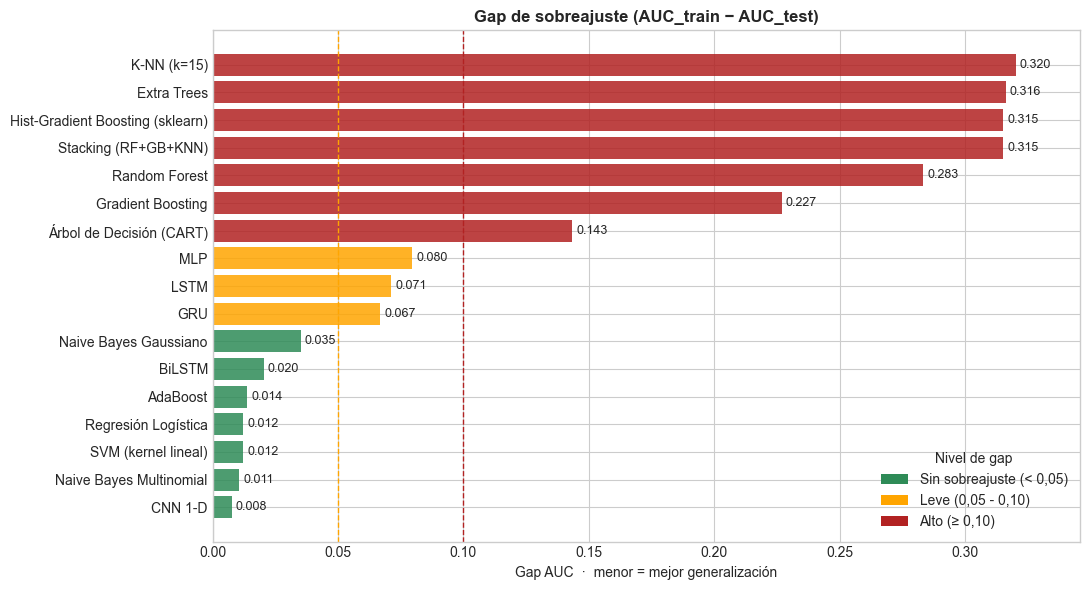


Modelo ganador por ROC-AUC: CNN 1-D


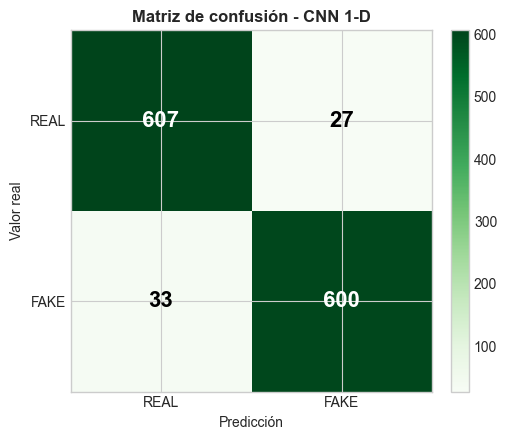


Informe de clasificación del modelo ganador:
              precision    recall  f1-score   support

        REAL       0.95      0.96      0.95       634
        FAKE       0.96      0.95      0.95       633

    accuracy                           0.95      1267
   macro avg       0.95      0.95      0.95      1267
weighted avg       0.95      0.95      0.95      1267



In [34]:
# GAP DE SOBREAJUSTE + MATRIZ DE CONFUSIÓN DEL GANADOR
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# (a) Gap de sobreajuste por modelo
t_gap = tabla.sort_values("Gap_AUC")
plt.figure(figsize=(11, 6))
colores = ["seagreen" if g < 0.05 else ("orange" if g < 0.10 else "firebrick") for g in t_gap["Gap_AUC"]]
barras = plt.barh(t_gap["Modelo"], t_gap["Gap_AUC"], color=colores, alpha=.85)

# Etiqueta con el valor del gap (2 decimales) al final de cada barra
plt.bar_label(barras, labels=[f"{g:.3f}" for g in t_gap["Gap_AUC"]], padding=3, fontsize=9)

plt.axvline(0.05, ls="--", c="orange", lw=1)
plt.axvline(0.10, ls="--", c="firebrick", lw=1)
plt.title("Gap de sobreajuste (AUC_train − AUC_test)", fontweight="bold")
plt.xlabel("Gap AUC  ·  menor = mejor generalización")
plt.margins(x=0.08)   # margen extra a la derecha para que las etiquetas no se corten
niveles = [
    Patch(facecolor="seagreen",  label="Sin sobreajuste (< 0,05)"),
    Patch(facecolor="orange",    label="Leve (0,05 - 0,10)"),
    Patch(facecolor="firebrick", label="Alto (≥ 0,10)"),
]
plt.legend(handles=niveles, loc="lower right", title="Nivel de gap")
plt.tight_layout()

# Exportación a la carpeta local de descargas
ruta_descargas = Path('.') / "descargas"
plt.savefig(ruta_descargas / "15.2.3. gap_sobreajuste.png", dpi=200, bbox_inches="tight")
plt.show()

# (b) Matriz de confusión del mejor modelo
ganador = tabla.iloc[0]["Modelo"]
print(f"\nModelo ganador por ROC-AUC: {ganador}")
prob_win = probas_test[ganador]
pred_win = (prob_win > 0.5).astype(int)
cm = confusion_matrix(y_test, pred_win)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Greens")

umbral = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=16, fontweight="bold",
                color="white" if cm[i, j] > umbral else "black")

ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["REAL", "FAKE"]); ax.set_yticklabels(["REAL", "FAKE"])
ax.set_xlabel("Predicción"); ax.set_ylabel("Valor real")
ax.set_title(f"Matriz de confusión - {ganador}", fontweight="bold")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()

# Exportación a la carpeta local de descargas
plt.savefig(ruta_descargas / "15.2.3. matriz_ganador.png", dpi=200, bbox_inches="tight")
plt.show()

print("\nInforme de clasificación del modelo ganador:")
print(classification_report(y_test, pred_win, target_names=["REAL", "FAKE"]))

**Lectura del gap.** Los siete modelos en rojo (gap ≥ 0,10) son todos *tabulares*: K-NN, Extra Trees, Stacking, Hist-GB, Random Forest, Gradient Boosting y CART. Varios alcanzan AUC de entrenamiento de 1,000 y se desploman a ~0,68 en test: memorizan los metadatos sin extraer nada generalizable. El extremo es el K-NN, que por construcción acierta perfecto en train (cada punto es su propio vecino más cercano).

**El matiz que el gap revela: sobreajustar no es lo opuesto a rendir.** El orden por gap no coincide con el de AUC. El Naive Bayes Gaussiano y el AdaBoost caen en verde (gap bajo) pese a rendir mal, porque no memorizan, simplemente no encuentran señal, así que su train tampoco despega. Gap bajo no significa buen modelo: significa que train y test se parecen, sea ese parecido bueno (CNN) o malo (NB Gaussiano). Por eso los cinco líderes del notebook (CNN, NB Multinomial, LogReg, SVM, BiLSTM) están todos en verde *y* arriba en AUC: combinan generalización con discriminación real, que es la cualidad que se busca para producción.

**La matriz del ganador.** La CNN reparte sus pocos errores de forma casi simétrica entre los dos tipos: un puñado de falsos positivos (REAL marcado como FAKE) y un número parecido de falsos negativos (FAKE marcado como REAL), frente a unos 600 aciertos en cada clase. No se inclina de forma apreciable hacia ningún tipo de error: ni censura información legítima de más, ni deja pasar desinformación de más. Ese equilibrio, coherente con el dataset balanceado 50/50, es lo ideal en un detector donde ambos errores tienen coste y ninguno debe primar sobre el otro por defecto.

## 15.3. Conclusión global y selección de modelo

**El recorrido.** Este notebook evaluó 17 modelos sobre tres representaciones del mismo corpus de noticias, bajo un protocolo único (split estratificado, umbral 0,5, métricas idénticas, semillas fijas) que hace la comparación legítima. Se recorrieron las tres familias del temario: clásicos supervisados, ensembles y deep learning, cada modelo sobre la representación afín a su naturaleza. El objetivo no era solo encontrar el mejor clasificador, sino entender *por qué* unos funcionan y otros no.

**El hallazgo central: la representación manda sobre el modelo.** El resultado más sólido y transversal del trabajo es que el rendimiento se decide por *cómo se representan los datos*, no por la sofisticación del algoritmo. Los 10 modelos que operan sobre *features tabulares* (metadatos de formato, conteos y popularidad) se estancan todos en torno a 0,65-0,69 de AUC, sin que importe si son un árbol simple, un ensemble de 300 estimadores, un meta-modelo o una red neuronal. El MLP es la prueba decisiva: una red profunda no supera a un K-NN cuando ambos miran los mismos metadatos sin señal. En cambio, en cuanto el modelo accede al *texto* (como bolsa de palabras TF-IDF o como secuencia de embeddings), el rendimiento salta al rango 0,84-0,99. La señal que distingue una noticia falsa de una real vive en las palabras, y ninguna potencia algorítmica compensa mirar donde esa señal no está.

**Hallazgos secundarios.** Tres lecturas refuerzan lo anterior:

* **Entre los tabulares, el algoritmo es indiferente.** Bagging, boosting y stacking convergen al mismo techo: cuando no hay señal, la estrategia de ensemble no la inventa. El Stacking combina tres modelos para no separarse de sus bases.
* **No hace falta deep learning para el texto.** Un modelo lineal sobre TF-IDF (Regresión Logística, ≈ 0,98) compite de tú a tú con las mejores redes. La sofisticación no es un fin en sí misma.
* **Generalizar y rendir son cosas distintas.** El análisis de sobreajuste mostró que un gap bajo no implica buen modelo (el Naive Bayes Gaussiano generaliza bien y rinde mal). Los modelos verdaderamente desplegables son los que combinan AUC alto *y* gap bajo: CNN, SVM, Regresión Logística, BiLSTM.

**Selección de modelo: Regresión Logística sobre TF-IDF.** Por AUC puro gana la CNN 1-D (≈ 0,99), con SVM, Regresión Logística y BiLSTM (todos ≈ 0,98) en un punto justo detrás; la diferencia entre ellos cae dentro del margen de variación entre ejecuciones, así que son estadísticamente equivalentes en la cima. Cuando cuatro modelos rinden prácticamente igual, la elección se decide por sus **propiedades cualitativas**, y ahí la Regresión Logística es la más sólida:

* **Interpretabilidad total.** Cada término tiene un peso explícito: se puede leer qué palabras empujan una noticia hacia FAKE o hacia REAL (como se vio en 13.1). Ni la CNN, ni el SVM con kernel, ni la BiLSTM ofrecen esa transparencia. Para un sistema que deba *justificar* sus decisiones, es determinante.
* **Simplicidad.** Es un modelo lineal, sin arquitecturas profundas ni ajustes delicados. Menos superficie de error, más fácil de mantener y de auditar.
* **Rendimiento equivalente.** Su AUC (≈ 0,98) está a un margen mínimo de la CNN, dentro del ruido entre corridas: no se sacrifica capacidad discriminante real al elegirla.

La **CNN 1-D queda como alternativa** cuando el objetivo sea la máxima discriminación absoluta y no se necesite interpretar las decisiones. En resumen, se elige la Regresión Logística por combinar rendimiento de primer nivel con transparencia y simplicidad, las cualidades que de verdad importan en un modelo destinado a producción.

**Limitación de validez externa.** El rendimiento de los modelos de texto se apoya en una mezcla de señales, visible ya en la Regresión Logística (13.1). Una parte es específica del periodo (fechas de 2016, nombres propios como `hillary` u `obama`) y no transferiría fuera del corpus. Otra parte es de estilo y registro (atribución de fuentes en lo REAL, incitación a compartir en lo FAKE) que sí podría generalizar. Por eso no cabe afirmar ni que el modelo detecta solo "noticias de 2016" ni que generaliza sin más: su validez sobre otro periodo está por medir, y esa medición es la prioridad de los próximos pasos.

# 16. Próximos pasos recomendados

Con la línea base de 17 modelos establecida bajo un protocolo común, las siguientes iteraciones, ordenadas por relación impacto/esfuerzo, permitirían avanzar. La prioridad la marcan los hallazgos del propio notebook: como el rendimiento lo decide la representación y no el algoritmo, el esfuerzo futuro debe concentrarse en el texto y en la validez de los datos, no en exprimir modelos que ya tocaron techo.

## 16.1. Validar la generalización sobre otro corpus (prioridad máxima)

Es el paso más urgente, porque cierra la única incógnita seria del trabajo. Los modelos de texto rinden de forma sobresaliente, pero su señal mezcla patrones de estilo que podrían transferir (atribución de fuentes, incitación a compartir) con anclas del periodo que no lo harían (fechas de 2016, nombres propios), como se vio en 13.1. No se puede saber cuánto de ese rendimiento es generalizable sin probarlo: reentrenar y evaluar el mejor modelo sobre un corpus de distinto periodo o temática. Si el AUC aguanta, el modelo capta desinformación; si se desploma, se apoyaba sobre todo en el contexto de 2016.

## 16.2. Reflexión metodológica sobre la evaluación

En el diseño del pipeline se valoró usar validación cruzada estratificada de 5 particiones (`StratifiedKFold`) como protocolo de ranking, y se optó finalmente por una partición de prueba fija del 20 % (N = 1.267). El motivo es el tamaño del corpus: con 1.267 noticias en test, balanceadas 50/50, la estimación del ROC-AUC es lo bastante estable como para comparar modelos sin necesidad de promediar varias particiones. Un *hold-out* fijo, aplicado por igual a los 17 modelos bajo la misma semilla, ofrece una comparación consistente y reproducible.

La validación cruzada no desaparece del trabajo: opera dentro del Stacking (`cv=5`), donde es estructural para entrenar el meta-modelo sin fuga de información. Lo que no se adopta es como criterio de *ranking* de los 17 modelos, donde la partición fija cumple esa función.

Como línea de mejora, una validación cruzada completa sobre todos los modelos daría además una estimación de la *varianza* de cada métrica (no solo su valor puntual), lo que reforzaría la comparación. Queda como trabajo futuro.

## 16.3. Optimización de hiperparámetros, solo donde tiene sentido

El notebook fijó hiperparámetros estándar a propósito, para que los 17 modelos fueran comparables bajo el mismo protocolo. Levantada esa restricción, una búsqueda sistemática con `GridSearchCV` o `RandomizedSearchCV` (esta última más eficiente cuando el espacio de búsqueda es grande), siempre con validación cruzada, tiene sentido solo en los modelos de texto, que son los que tienen margen real:

* **Modelos sobre TF-IDF** (Regresión Logística, SVM): rejilla sobre el parámetro de regularización (`C`, que controla el equilibrio entre ajuste y sobreajuste), sobre el número de características que conserva el vectorizador (las 7500 actuales podrían no ser el óptimo) y sobre el rango de n-gramas.
* **Redes secuenciales** (CNN, BiLSTM): dimensión del embedding, número de filtros o unidades, `dropout` y `learning_rate`.

No se incluye el ajuste de los modelos tabulares (Random Forest, Extra Trees, Gradient Boosting, etc.): los resultados demuestran que su techo (~0,69 AUC) lo impone la representación, no los hiperparámetros, así que optimizarlos no rompería ese límite.

## 16.4. Enriquecer la representación textual

Dado que toda la señal vive en el texto, mejorar cómo se representa es la vía de mayor recorrido:

* **Embeddings preentrenados** (Word2Vec, GloVe) para inicializar la capa `Embedding` por transfer learning, en lugar de aprenderla desde cero. Estos vectores capturan relaciones semánticas entre palabras aprendidas de corpus enormes, un conocimiento que un dataset moderado no alcanza a cubrir.
* **Ampliar el rango de n-gramas del TF-IDF** (bigramas, trigramas) para capturar combinaciones de palabras, no solo términos sueltos, lo que añade contexto local a la representación de bolsa de palabras.

## 16.5. Arquitecturas Transformer

El salto cualitativo provendría de los modelos contextuales, el escalón que sigue a las redes recurrentes que aquí marcaron el techo. Las RNN (LSTM, GRU, BiLSTM) arrastran un límite estructural: pierden señal en secuencias largas (el problema de vanishing gradients a partir de cierta longitud) y procesan los tokens uno a uno. Los Transformers lo resuelven con el mecanismo de atención, que relaciona cada palabra con todas las demás de la frase a la vez y pondera cuáles son relevantes para cada tarea.

* **Fine-tuning de un modelo preentrenado tipo BERT** (un encoder Transformer) sobre el corpus. A diferencia del embedding que aquí se entrena desde cero, BERT aporta embeddings contextualizados: la misma palabra recibe un vector distinto según su contexto, lo que captura matices que un embedding estático no alcanza. Mediante transfer learning, bastaría ajustar las últimas capas a la tarea de clasificación FAKE/REAL.
* **Interpretabilidad del modelo desplegado.** Sea cual sea el modelo final, conviene auditar en qué se apoya para decidir. La Regresión Logística lo permite de forma directa: sus coeficientes (`coef_`) señalan qué términos empujan hacia FAKE o REAL, y los modelos de árbol exponen su importancia de variables. Esta auditoría es la mejor defensa contra el riesgo, señalado en 16.1, de que el modelo aprenda atajos (fechas, nombres propios de 2016) en lugar de detectar desinformación real.

## 16.6. Interpretabilidad del modelo desplegado

Si el detector se lleva a producción, conviene acompañarlo de una capa de interpretabilidad, y el modelo seleccionado la ofrece de forma nativa:

* **Regresión Logística**: sus coeficientes (`coef_`) indican qué términos empujan una noticia hacia FAKE o hacia REAL, lo que permite justificar cada predicción y, sobre todo, auditar en qué medida el modelo se apoya en señal de estilo generalizable frente a los artefactos de fecha y nombres propios señalados en 12.1.
* **Modelos basados en árboles** (Random Forest): su importancia de variables señala qué atributos pesan más en la decisión, útil si se combinara la representación textual con los metadatos tabulares.

Esta auditoría es la mejor defensa para verificar que el modelo se apoya en patrones lingüísticos que caracterizan la desinformación, y no solo en marcas específicas del periodo del corpus.